https://www.10xgenomics.com/analysis-guides/introduction-to-ambient-rna-correction

##YOU NEED TO ACTIVATE JUPYTER NOTEBOOK FROM WITHIN THE SCVI ENVIRONMENT!! (sc2024) "Conda activate sc2024"

Model: '6_27_24_cellbender_Ctrl134_Zap134_adatasintegrated.model'

Adata: '6_27_24_cellbenderdatasintegrated.h5ad'
Updated Adata: '6_27_24_cellbenderclean_adata_norm_scaled.h5ad'

Files Integrated in this model and adata: Control1,3,4 + Zap1,3,4

In [2]:
import os
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from PIL import Image


##YOU NEED TO ACTIVATE JUPYTER NOTEBOOK FROM WITHIN THE SCVI ENVIRONMENT!! (SC2024)

In [2]:
#To load a previously trained and saved model and adata object

import os
import scanpy as sc
import seaborn as sns
import matplotlib as matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
# Set the font family for matplotlib.pyplot
plt.rcParams['font.family'] = 'Arial'


import sys
sys.path.append('C:/Users/Riss Kellogg/miniconda3/envs/scvi-env/Lib/site-packages')
import doubletdetection
import scvi

#adata = sc.read_h5ad('6_27_24_cellbenderclean_adata_norm_scaled.h5ad')
adata = sc.read_h5ad('9_6_24_cellbenderclean_adata_norm_scaled_rawdatasaved.h5ad')
model = scvi.model.SCVI.load('6_27_24_cellbender_Ctrl134_Zap134_adatasintegrated.model', adata = adata)

INFO     File 6_27_24_cellbender_Ctrl134_Zap134_adatasintegrated.model\model.pt already downloaded                 


C:\Users\Riss Kellogg\miniconda3\envs\sc2024\lib\site-packages\scvi\data\fields\_base_field.py:64: UserWarning: adata.X does not contain unnormalized count data. Are you sure this is what you want?
  self.validate_field(adata)


In [2]:
adata

AnnData object with n_obs × n_vars = 74980 × 18173
    obs: 'Sample', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'pct_counts_mt', 'pct_counts_ribo', 'doublet', 'doublet_score', '_scvi_batch', '_scvi_labels', 'leiden', 'condition', 'cell_type'
    var: 'n_cells'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'condition_colors', 'leiden', 'leiden_colors', 'log1p', 'markers', 'neighbors', 'rank_genes_groups', 'umap'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs', '_scvi_extra_continuous_covs'
    layers: 'counts', 'normalized_counts'
    obsp: 'connectivities', 'distances'

# Rationale for removing ambient RNA

*********Need to correct for high ambient RNA**********
One of the first signs that you may need to consider correcting for background RNA is if you get the “Low Fraction Reads in Cells” alert at the top of your Web Summary*

Ambient RNAs can also originate from more abundant cell types, which can lead to biological misinterpretation when these RNAs contaminate less abundant cell types (Caglayan et al., 2022). This phenomenon can be observed, for example, in mouse brain nuclei, where neuronal markers are observed in glial cell populations and vice versa. Thus, accounting for background RNA profiles often requires a priori knowledge of the sample biology.

As mentioned previously, such data may still be usable even without background subtraction. Whether or not to perform background correction will depend on the extent of contamination and the overall goals of the experiment. For example, one may want to more carefully profile and correct for background contamination using community-developed computational tools if the goal of the experiment is to profile rare cell subtypes. If the overall goals of the experiment involve well-known major cell types, the Cell Ranger cell calling algorithm may perform well enough with its cell calling and filtering steps. Researchers should carefully consider their sample biology, expected cell types, and any unexpected results, such as cell type markers that normally do not overlap co-expressing in one cluster (this may be a sign of ambient RNAs from one cell type partitioning into GEMs as in the neuronal and glial cell type marker example above).

Empty Droplets:
In droplet-based scRNA-seq, cells are encapsulated in droplets along with barcoded beads. Some droplets may not contain a cell (empty droplets), while others contain a single cell.

Empty droplets can arise due to various factors, such as failed cell capture or ambient RNA contamination.

Detecting and filtering out empty droplets is crucial to ensure accurate downstream analysis.

Cell Ranger Count Output:
The Cell Ranger Count output does not explicitly include information about empty droplets. It focuses on quantifying gene expression for cells.

However, the output does not inherently distinguish between cells and empty droplets. It treats all barcodes (including those from empty droplets; aka ambient RNA) as part of the dataset.

To identify and filter out empty droplets, additional steps are needed after running Cell Ranger Count.

https://www.10xgenomics.com/analysis-guides/background-removal-guidance-for-single-cell-gene-expression-datasets-using-third-party-tools

To computationally identify and remove ambient RNA, specifically in the nuclei datasets, one can make use of community-developed tools. In this article, we will use the remove-background algorithm (Fleming et al.) implemented in the CellBender python package. CellBender uses a machine learning model that is used to train the background RNA profile, distinguish cell-containing droplets from empty ones, and retrieve cleaner gene expression profiles. We then switch from python to R to further explore clustering downstream in Seurat.

# Prerequisites

Prerequisites
This article assumes the raw sequence data have already been demultiplexed using either the bcl2fastq or mkfastq pipelines (i.e., you are starting with FASTQ files). Also you must run the cellranger count or multi pipelines for alignment and annotation of reads, barcode error correction, and generation of feature barcode matrices.

All the steps in CellBender are in python. If you don't have python in your system yet, please install python. You may also consider running python using any IDE. If you do not have a conda environment, you could try miniconda.

The softwares used in this article can be run on a Linux server. Software versions used in this article include:

Python v3.8
CellBender v0.2.0
R version v4.0

https://cellbender.readthedocs.io/en/latest/tutorial/index.html
    CellBender (2019, 2022): a deep generative model that distinguishes cell-containing from cell-free droplets without supervision, learns the profile of background noise, and retrieves a noise-free quantification.

How it works: A neural network learns the distribution of expression across all droplets in an experiment and estimates the background noise profile of ambient RNAs across all droplets. This tool performs both cell-calling and ambient RNA removal.

CellBender needs to be run on UNFILTERED (raw) .h5 files.
Download all raw files from cellranger_count output

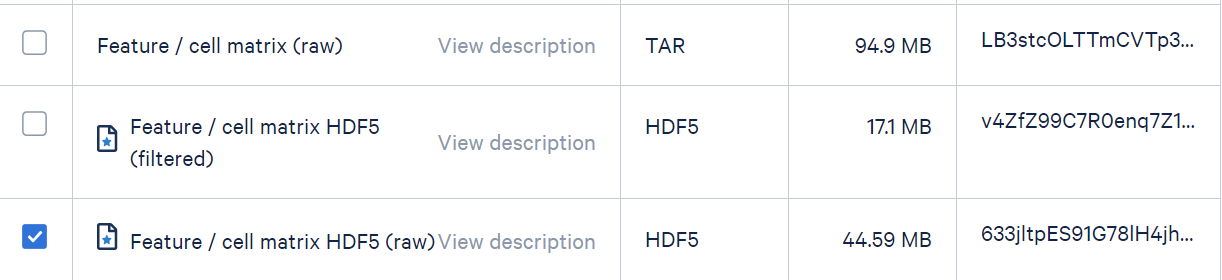

# Running CellBender using Northeastern's Discovery Cluster

CellBender runs extremely slowly without a dedicated GPU. GMGI's rhel server can do it, but since there is no GPU it will take forever (a week to run 7 files without a GPU).

Use Northeastern's Discovery Cluster instead.
Attempt CellBender on Northeastern Computing Cluster, using a GPU for more speed

Login to computing cluster: https://ood.discovery.neu.edu/pun/sys/dashboard/files/fs//home/r.kellogg

Upload the raw .h5 files to /home directory.

Activate conda following this guide: https://rc-docs.northeastern.edu/en/latest/software/packagemanagers/conda.html
https://rc-docs.northeastern.edu/en/latest/runningjobs/workingwithgpus.html


Create a new environment with the command 'conda create -n cellbender python=3.7'
Activate cell bender environment: 'conda activate cellbender'
Add cellbender with: pip install cellbender

While in the activated conda environment 'cellbender', navigate to the folder with your .h5 raw files.


Created a script, 'RunCellBender.sh':

#!/bin/bash
#SBATCH --partition=gpu
#SBATCH --gres=gpu:1
#SBATCH --job-name=testgpu_run               # Job name
#SBATCH --nodes=1                   # Number of nodes
#SBATCH --ntasks=1                  # Number of tasks
#SBATCH --mem=4GB 
#SBATCH --output=output_%j.txt       # Standard output file
#SBATCH --error=error_%j.txt        # Standard error file
#Loop through .h5files and apply cellbender
conda init
conda activate cellbender

for file in /home/r.kellogg/RawH5Files/*.h5; do cellbender remove-background --input "$file" --output "$(basename "$file" .h5)denoised.h5" --total-droplets-included 50000
 --expected-cells 10000 --fpr 0.01 --epochs 150 --cuda; done
#To run from login node: type 'sbatch RunCellBender.sh' 

-----------------------------------------------------------------------------------------------
--partition=gpu requests a GPU be used for faster processing. it will take longer to get since you have to wait until a resource becomes available. 

Run the script in batch mode, from the login node, using 'sbatch RunCellBender.sh'


It will loop through all raw .h5 files using cellbender remove-background. Including --cuda makes it use the GPU. 

'for file in *h5; do cellbender remove-background --input $file --output ../CleanH5Files/$(basename $file .h5)denoised --total-droplets-included 50000 --expected-cells 10000 --fpr 0.01 --epochs 150; done'


To compare, I assigned this task to GMGIs server-- over the weekend, it only completed 1 sample out of 7. 

CellBender will make 8 output files per input file

# Processing in JPYN

In [40]:
import os
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

import sys
import os
sys.path.append('C:/Users/Riss Kellogg/miniconda3/envs/scvi-env/Lib/site-packages')
import doubletdetection
import scvi
#set random seed for scvi: for reproducible multiple calls to 'model.differential_expression'
scvi.settings.seed = 5623

Seed set to 5623


In [3]:
import warnings
warnings.simplefilter("ignore", FutureWarning)
warnings.simplefilter("ignore", UserWarning)
warnings.simplefilter("ignore", RuntimeWarning)
%matplotlib inline

# See how much background RNA was removed using metrics.csv file

In [4]:
os.listdir(path="C:/Users/Riss Kellogg/Desktop/CellBenderMetricsFiles")

['Ctrl1denoised_metrics.csv',
 'Ctrl3denoised_metrics.csv',
 'Ctrl4denoised_metrics.csv',
 'Zap1denoised_metrics.csv',
 'Zap3denoised_metrics.csv',
 'Zap4denoised_metrics.csv']

In [5]:
pd.read_csv("C:/Users/Riss Kellogg/Desktop/CellBenderMetricsFiles/Ctrl1denoised_metrics.csv")

,total_raw_counts,48307716.000
0,total_output_counts,4.210713e+07
1,total_counts_removed,6.200588e+06
2,fraction_counts_removed,1.280000e-01
3,total_raw_counts_in_cells,4.830772e+07
4,total_counts_removed_from_cells,6.200588e+06
5,fraction_counts_removed_from_cells,1.280000e-01
6,average_counts_removed_per_cell,3.083030e+02
7,target_fpr,1.000000e-02
8,expected_cells,1.000000e+04
9,found_cells,2.011200e+04


In [6]:
#Create a dataframe from metrics data
path = "C:/Users/Riss Kellogg/Desktop/CellBenderMetricsFiles/"
metrics = []

for file in [x for x in os.listdir(path) if x.endswith('metrics.csv')]:
    t= pd.read_csv(path + file,
                  header = None, names = ['Metric', 'Value']).set_index('Metric').T
    t['File'] = file
    metrics.append(t)
    
metrics = pd.concat(metrics).reset_index()

In [7]:
metrics
#1 row per sample
#Notice that Fraction_counts_removed are all high, especially for zaps (>10%)

Metric,index,total_raw_counts,total_output_counts,total_counts_removed,fraction_counts_removed,total_raw_counts_in_cells,total_counts_removed_from_cells,fraction_counts_removed_from_cells,average_counts_removed_per_cell,target_fpr,expected_cells,found_cells,output_average_counts_per_cell,ratio_of_found_cells_to_expected_cells,found_empties,fraction_of_analyzed_droplets_that_are_nonempty,convergence_indicator,overall_change_in_train_elbo,File
0,Value,48307716.0,42107128.0,6200588.0,0.128,48307716.0,6200588.0,0.128,308.303,0.01,10000.0,20112.0,2093.632,2.011,29888.0,0.402,0.486,746.549,Ctrl1denoised_metrics.csv
1,Value,59595662.0,54315781.0,5279881.0,0.089,59595662.0,5279881.0,0.089,232.502,0.01,10000.0,22709.0,2391.817,2.271,27291.0,0.454,0.674,895.723,Ctrl3denoised_metrics.csv
2,Value,48851600.0,47118855.0,1732745.0,0.035,48851600.0,1732745.0,0.035,108.107,0.01,10000.0,16028.0,2939.784,1.603,33972.0,0.321,0.654,838.467,Ctrl4denoised_metrics.csv
3,Value,22719358.0,17848575.0,4870783.0,0.214,22719358.0,4870783.0,0.214,218.538,0.01,10000.0,22288.0,800.815,2.229,27712.0,0.446,0.947,266.870,Zap1denoised_metrics.csv
4,Value,12814609.0,10718269.0,2096340.0,0.164,12814609.0,2096340.0,0.164,125.147,0.01,10000.0,16751.0,639.858,1.675,33249.0,0.335,0.602,172.386,Zap3denoised_metrics.csv
5,Value,30481001.0,26154972.0,4326029.0,0.142,30481001.0,4326029.0,0.142,192.208,0.01,10000.0,22507.0,1162.082,2.251,27493.0,0.450,2.362,462.175,Zap4denoised_metrics.csv


In [374]:
#Histogram of fraction_counts_removed

metrics.plot.bar(x = 'File', y = 'fraction_counts_removed_from_cells', grid=False)

#6 samples total

from IPython.display import clear_output
clear_output(wait=True)

# Working with new filtered.h5 files

In [2]:
os.listdir(path="C:/Users/Riss Kellogg/Desktop/CellBenderCleanH5Files")

['Ctrl1_denoised_filtered.h5',
 'Ctrl3_denoised_filtered.h5',
 'Ctrl4_denoised_filtered.h5',
 'Zap1_denoised_filtered.h5',
 'Zap3_denoised_filtered.h5',
 'Zap4_denoised_filtered.h5']

In [3]:
pathH5s = "C:/Users/Riss Kellogg/Desktop/CellBenderCleanH5Files/"
adatas = [x for x in os.listdir(pathH5s) if x.endswith('filtered.h5')]
#you could also use a whitelist of barcodes from the filtered barcodes for each sample
#in this case, you would open the unfiltered then filter it based on the whitelist

In [4]:
adatas

['Ctrl1_denoised_filtered.h5',
 'Ctrl3_denoised_filtered.h5',
 'Ctrl4_denoised_filtered.h5',
 'Zap1_denoised_filtered.h5',
 'Zap3_denoised_filtered.h5',
 'Zap4_denoised_filtered.h5']

In [5]:
def load_it(adata):
    samp = adata.split('_')[0]
    dx = adata.split('_')[1]
    adata = sc.read_10x_h5(pathH5s + adata)
    adata.obs['Sample'] = samp
    #adata.obs['DX'] = dx
    #adata.obs['Sample'] = adata.obs['Patient'] + '_' + adata.obs['DX']
    adata.obs.index = adata.obs.index + '-' + samp
    return adata

In [6]:
adatas = [load_it(ad) for ad in adatas]

C:\Users\Riss Kellogg\miniconda3\envs\sc2024\lib\site-packages\anndata\_core\anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\Riss Kellogg\miniconda3\envs\sc2024\lib\site-packages\anndata\_core\anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\Riss Kellogg\miniconda3\envs\sc2024\lib\site-packages\anndata\_core\anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\Riss Kellogg\miniconda3\envs\sc2024\lib\site-packages\anndata\_core\anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\Riss Kellogg\miniconda3\envs\sc2024\lib\site-packages\anndata\_core\anndata.py:1820

In [7]:
adatas

[AnnData object with n_obs × n_vars = 20112 × 27447
     obs: 'Sample'
     var: 'gene_ids', 'feature_types', 'genome',
 AnnData object with n_obs × n_vars = 22709 × 27447
     obs: 'Sample'
     var: 'gene_ids', 'feature_types', 'genome',
 AnnData object with n_obs × n_vars = 16028 × 27447
     obs: 'Sample'
     var: 'gene_ids', 'feature_types', 'genome',
 AnnData object with n_obs × n_vars = 22288 × 27447
     obs: 'Sample'
     var: 'gene_ids', 'feature_types', 'genome',
 AnnData object with n_obs × n_vars = 16751 × 27447
     obs: 'Sample'
     var: 'gene_ids', 'feature_types', 'genome',
 AnnData object with n_obs × n_vars = 22507 × 27447
     obs: 'Sample'
     var: 'gene_ids', 'feature_types', 'genome']

In [35]:
#background RNA is now gone
#used cellbender to determine what is an actual cell BUT cellbender is good at removing backgoround, not so good at calling cells
#Look at the adata objects above: they are all cells x genes. We expected 10,000 cells, and they are all 16-20k+. So cellbender has included too many.
def qc(adata):
    sc.pp.filter_cells(adata, min_genes = 200) #anything below 200 genes is very likely not going to be a cell
    adata.var["mt"] = adata.var_names.str.startswith('mrp143') #try filtering mitochondrial genes in SP. need to pull mito genes and make a separate list, then pass LOC names. here is just one as an example.
    adata.var["ribo"] = adata.var_names.str.startswith("RPS", "RPL") #placeholder for ribosomal genes
    sc.pp.calculate_qc_metrics(adata, qc_vars=['mt','ribo'], inplace=True, percent_top=[20], log1p=True)
    remove = ['total_counts_mt', 'log1p_total_counts_mt', 'total_counts_ribo', 
          'log1p_total_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb'] #get rid of unuseful columns
    
    adata.obs = adata.obs[[x for x in adata.obs.columns if x not in remove]]
    adata.var_names_make_unique()
    
    return adata

In [36]:
adatas = [qc(ad) for ad in adatas]

In [37]:
df = pd.concat([x.obs for x in adatas])
df = df.sort_values('Sample')

In [38]:
df

,Sample,n_genes,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_20_genes,pct_counts_mt,pct_counts_ribo
CTTCCTTAGCCTGACC-1-Ctrl1,Ctrl1,4838,4838,8.484463,42237,10.651076,13.983001,0.0,0.0
TGGTGATTCCACCTCA-1-Ctrl1,Ctrl1,575,575,6.356108,1173,7.068172,22.506394,0.0,0.0
TAAGCCAAGCTGTTCA-1-Ctrl1,Ctrl1,602,602,6.401917,1187,7.080026,19.629318,0.0,0.0
TTTAGTCAGATACCAA-1-Ctrl1,Ctrl1,652,652,6.481577,1264,7.142827,18.196203,0.0,0.0
GAAATGAGTGGATTTC-1-Ctrl1,Ctrl1,610,610,6.415097,1247,7.129298,23.817161,0.0,0.0
...,...,...,...,...,...,...,...,...,...
CCTGTTGCATCACGGC-1-Zap4,Zap4,560,560,6.329721,1487,7.305188,26.630800,0.0,0.0
GTCCACTCATCGCTCT-1-Zap4,Zap4,844,844,6.739337,1450,7.280008,17.931034,0.0,0.0
CGGGTCAGTACTAGCT-1-Zap4,Zap4,626,626,6.440947,1449,7.279319,26.846101,0.0,0.0
CTATCTATCTGGGAGA-1-Zap4,Zap4,666,666,6.502790,1491,7.307873,23.742455,0.0,0.0


In [375]:
#Visualize how many total counts were in each sample using Ridge Plots
#look at the commented-out "#value" below. Switch through them to see each dataset. 
#Red line is the median.

#value = "pct_counts_mt"
#value = "n_genes" #some may have multi-modal distributions; usually the first bump is filtered out
#value = 'pct_counts_in_top_20_genes' #genes that are highly expressed all the time, they account for a big proportion of the total reads. Just 20 genes account for 20% of the total counts from a cell. 
value = "log1p_total_counts" #total counts, but on log1p scale.

sns.set(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})

g = sns.FacetGrid(df, row="Sample", hue="Sample", aspect=15, height=0.5, palette="tab20")

g.map(sns.kdeplot, value, clip_on=False, fill=True, alpha=1, linewidth=1.5)
g.map(sns.kdeplot, value, clip_on=False, color="w", lw=2)

g.map(plt.axhline, y=0, lw=2, clip_on=False)

def label(x, color, label):
    ax = plt.gca()
    ax.text(0, .2, label, fontweight="bold", color=color,
            ha="left", va="center", transform=ax.transAxes)

g.map(label, value)

g.figure.subplots_adjust(hspace=-.6)

g.set_titles("")
g.set(yticks=[], ylabel="")
g.despine(bottom=True, left=True)

for ax in g.axes.flat:
    ax.axvline(x=df[value].median(), color='r', linestyle='-')


plt.show()

from IPython.display import clear_output
clear_output(wait=True)

KeyError: 'Sample'

# Pre-processing

In [40]:
#Filter out low quality cells based on QC metrics and get rid of doublets
#Get rid of doublets using doubletdetection. SCVI tools is ok too but takes longer.
import doubletdetection
from scipy.stats import median_abs_deviation as mad
import numpy as np

In [41]:
#Look at one specific sample
a = df[df.Sample == 'Zap4'].log1p_total_counts #save log1p_total_counts to "a"

In [42]:
a

TATCTTGAGGTTCATC-1-Zap4    6.555357
CGAGTGCCATTGCTGA-1-Zap4    6.543912
ATCGCCTCACTCAAGT-1-Zap4    6.593045
CTCTCGATCACTTATC-1-Zap4    6.505784
TACACCCTCGATACGT-1-Zap4    6.584791
                             ...   
CCTGTTGCATCACGGC-1-Zap4    7.305188
GTCCACTCATCGCTCT-1-Zap4    7.280008
CGGGTCAGTACTAGCT-1-Zap4    7.279319
CTATCTATCTGGGAGA-1-Zap4    7.307873
TCCATCGGTAACACCT-1-Zap4    5.463832
Name: log1p_total_counts, Length: 16991, dtype: float64

In [43]:
#get the median 
np.median(a)

6.934397209928558

In [44]:
np.median(a) - 5 * mad(a) #median - 5 deviations below

4.280282149959844

In [45]:
np.median(a) + 5 * mad(a) #median + 5 deviations above

9.588512269897272

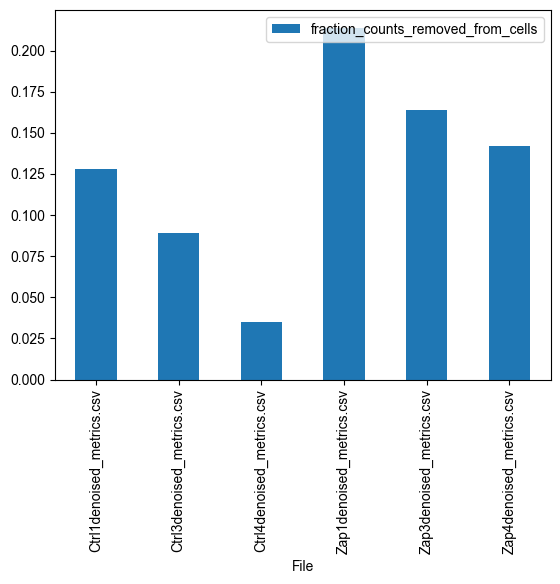

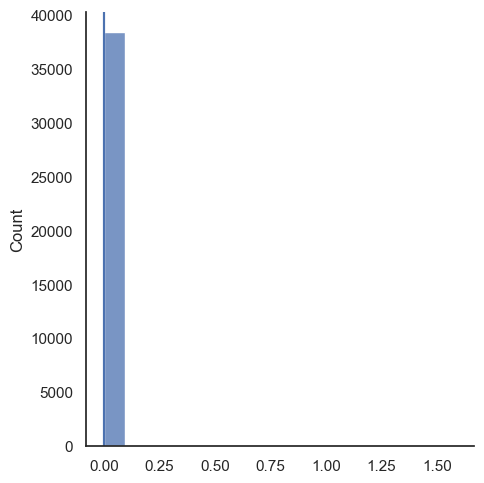

In [376]:
#plot the distribution

ax=sns.displot(a)
plt.axvline(np.median(a) - 5 * mad(a))
plt.axvline(np.median(a) + 5 * mad(a))
%matplotlib inline
plt.show()

from IPython.display import clear_output
clear_output(wait=True)

In [47]:
# We see that all the majority of cells lie between the 2 lines are within 5 absolute deviations of the median 
# Reccd by Germain et al 2020 (Genome Biology https://doi.org/10.1186/s13059-020-02136-7)

In [48]:
#Detect outliers using MAD (median absolute deviation)
#Helper function to flag cells as being in or out of mad bounds

def mad_outlier(adata, metric, nmads, upper_only = False): #metric is log1p_total_counts
    M = adata.obs[metric]
    
    if not upper_only:
        return (M < np.median(M) - nmads * mad(M)) | (M > np.median(M) +nmads * mad(M))
    
    return (M > np.median(M) + nmads + mad(M))

In [49]:
#Recc'd settings for DoubletDetection
clf = doubletdetection.BoostClassifier(
    n_iters=10,
    clustering_algorithm="louvain",
    standard_scaling = True,
    pseudocount = 0.1,
    n_jobs=-1)

In [50]:
#Create the pre-processing (pp) function

def pp(adata):
    adata = adata[adata.obs.pct_counts_mt < 25] #you can lower this based on the overal distribution of your dataset
    
    bool_vector = mad_outlier(adata, 'log1p_total_counts', 5) +\
            mad_outlier(adata, 'log1p_n_genes_by_counts', 5) +\
            mad_outlier(adata, 'pct_counts_in_top_20_genes', 5) +\
            mad_outlier(adata, 'pct_counts_mt', 3, upper_only = True)
    adata = adata[~bool_vector]

    adata.uns['cells_removed'] = sum(bool_vector)

    doublets = clf.fit(adata.X).predict(p_thresh=1e-16, voter_thresh=0.5) #recc thresholds
    doublet_score = clf.doublet_score()

    adata.obs["doublet"] = doublets
    adata.obs["doublet_score"] = doublet_score

    adata.uns['doublets_removed'] = adata.obs.doublet.sum()
    adata = adata[adata.obs.doublet == 0]
    adata.var_names_make_unique()

    return adata

In [51]:
#Call the preprocessing (pp) function on all adatas
adatas = [pp(ad) for ad in adatas] #create a list of individual adata objects

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

In [53]:
#Look at #of cells | cells removed | doublets removed for each sample
for adata in adatas:
    print(len(adata), adata.uns['cells_removed'], adata.uns['doublets_removed'])

14986 482 1369.0
13870 516 1268.0
9726 650 193.0
12538 123 1015.0
8682 118 399.0
15178 103 1710.0


These stats look good. Note that if your data are more noisy (ie, it says 0 doublets removed; thats not correct) you will need to adjust settings.

If the number of cells removed in MAD filtering is very large relative to overall cells, it may be worthwhile to increase thresholds or use a less conservative method. ~5-15% is typical.

Expected doublet rate is typically ~2-10% depending on the number of cells sequenced for 10x workflows

If anything deviates drastically, visit that sample specifically.

You can try to increase the p_thresh= (1e-16 to start) closer to 1 (1e-3) or move voter_thresh closer to 0.

****MAKE SURE PREPROCESSING LOOKS RIGHT BECAUSE IT WILL AFFECT EVERYTHING DOWNSTREAM*****

single cell best practices by the Theis lab is a good resource https://www.nature.com/articles/s41576-023-00586-w https://www.sc-best-practices.org/preprocessing_visualization/quality_control.html

In [54]:
#Look at how distributions look, after this preprocessing
df2 = pd.concat([x.obs for x in adatas])
df2 = df2.sort_values('Sample')

In [377]:
#value = "pct_counts_mt"
#value = "n_genes"
#value = 'pct_counts_in_top_20_genes'
value = "log1p_total_counts"

sns.set(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})

g = sns.FacetGrid(df2, row="Sample", hue="Sample", aspect=15, height=0.5, palette="tab20")

g.map(sns.kdeplot, value, clip_on=False, fill=True, alpha=1, linewidth=1.5)
g.map(sns.kdeplot, value, clip_on=False, color="w", lw=2)

g.map(plt.axhline, y=0, lw=2, clip_on=False)

def label(x, color, label):
    ax = plt.gca()
    ax.text(0, .2, label, fontweight="bold", color=color,
            ha="left", va="center", transform=ax.transAxes)

g.map(label, value)

g.figure.subplots_adjust(hspace=-.6)

g.set_titles("")
g.set(yticks=[], ylabel="")
g.despine(bottom=True, left=True)

for ax in g.axes.flat:
    ax.axvline(x=df2[value].median(), color='r', linestyle='-')


plt.show()

from IPython.display import clear_output
clear_output(wait=True)

KeyError: 'Sample'

# END OF PREPROCESSING
ambient RNA, doublets, and low quality cells are now removed.

# Saving all adatas into one concatenated adata

In [56]:
import scanpy as sc
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scvi

In [57]:
#%pip install celltypist hyperopt "ray[tune]" anndata2ri

In [58]:
import celltypist
from celltypist import models

In [59]:
#models.get_all_models()

In [60]:
adatas

[AnnData object with n_obs × n_vars = 14986 × 27447
     obs: 'Sample', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'pct_counts_mt', 'pct_counts_ribo', 'doublet', 'doublet_score'
     var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
     uns: 'cells_removed', 'doublets_removed',
 AnnData object with n_obs × n_vars = 13870 × 27447
     obs: 'Sample', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'pct_counts_mt', 'pct_counts_ribo', 'doublet', 'doublet_score'
     var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
     uns: 'cells_removed', 'doublets_removed',
 AnnData object wi

In [61]:
#combine all preprocessed adata objects into 1 adata object
adata = sc.concat(adatas)

In [62]:
adata

AnnData object with n_obs × n_vars = 74980 × 27447
    obs: 'Sample', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'pct_counts_mt', 'pct_counts_ribo', 'doublet', 'doublet_score'

# ADATA Save Point #1

In [64]:
#ADATA SAVE POINT 1: save as a h5ad format file
adata.write_h5ad('6_27_24_cellbenderdatasintegrated.h5ad')

In [65]:
##############################################3

# Part II: Mapping and Cluster Labelling

In [66]:
#%pip install scvi-tools
#need a version with AutoTune included

In [67]:
#Load the concatentated adata object. Note that this is NOT "INTEGRATED", all weve done is put the data into 1 object.
adata = sc.read_h5ad('6_27_24_cellbenderdatasintegrated.h5ad')

In [68]:
adata #remember that this is cells x genes

AnnData object with n_obs × n_vars = 74980 × 27447
    obs: 'Sample', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'pct_counts_mt', 'pct_counts_ribo', 'doublet', 'doublet_score'

In [69]:
# Use SCVI to get the embeddings to get the data to integrate together 
# 2024 single-cell guide Part 2: time = 21:43 
# You could use SCVI default parameters or Use hyperparameter tuning to make the model as good as possible
#from scvi.autotune import ModelTuner
from scvi.autotune import ModelTuner
from ray import tune

In [70]:
#Filter out lowly-expressed genes
sc.pp.filter_genes(adata, min_cells = 50)

In [72]:
adata
#now we're down to 18,173 genes

AnnData object with n_obs × n_vars = 74980 × 18173
    obs: 'Sample', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'pct_counts_mt', 'pct_counts_ribo', 'doublet', 'doublet_score'
    var: 'n_cells'

In [73]:
# here is where you could narrow these 18k genes down to the 2000 most differentially expressed genes

In [74]:
#Model for hyperparameter tuning
model_cls = scvi.model.SCVI
model_cls.setup_anndata(adata, categorical_covariate_keys = ['Sample'],
                             continuous_covariate_keys=['pct_counts_mt', 'pct_counts_ribo'])

tuner = ModelTuner(model_cls)

Unable to initialize backend 'cuda': 
Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
Unable to initialize backend 'tpu': UNIMPLEMENTED: LoadPjrtPlugin is not implemented on windows yet.


In [75]:
tuner.info()

ModelTuner registry for SCVI

                  Tunable hyperparameters                  
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃      Hyperparameter      ┃ Default value ┃    Source    ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│         n_hidden         │      128      │     VAE      │
│         n_latent         │      10       │     VAE      │
│         n_layers         │       1       │     VAE      │
│       dropout_rate       │      0.1      │     VAE      │
│        dispersion        │     gene      │     VAE      │
│     log_variational      │     True      │     VAE      │
│     gene_likelihood      │     zinb      │     VAE      │
│   latent_distribution    │    normal     │     VAE      │
│    encode_covariates     │     False     │     VAE      │
│ deeply_inject_covariates │     True      │     VAE      │
│      use_batch_norm      │     both      │     VAE      │
│      use_layer_norm      │     none      │     VAE      │
│  use_observed_lib_size   │     True      │     VAE      │
│      var_activation      │     None      │     VAE      │
│        optimizer         │     Adam      │ TrainingPlan │
│            lr            │     0.001     │ TrainingPlan │
│       weight_decay       │     1e-06     │ TrainingPlan │
│           eps            │     0.01      │ TrainingPlan │
│    n_steps_kl_warmup     │     None      │ TrainingPlan │
│    n_epochs_kl_warmup    │      400      │ TrainingPlan │
│   reduce_lr_on_plateau   │     False     │ TrainingPlan │
│        lr_factor         │      0.6      │ TrainingPlan │
│       lr_patience        │      30       │ TrainingPlan │
│       lr_threshold       │      0.0      │ TrainingPlan │
│          lr_min          │       0       │ TrainingPlan │
│      max_kl_weight       │      1.0      │ TrainingPlan │
│      min_kl_weight       │      0.0      │ TrainingPlan │
│        batch_size        │      128      │     SCVI     │
└──────────────────────────┴───────────────┴──────────────┘

       Available metrics        
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃     Metric      ┃    Mode    ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ validation_loss │    min     │
└─────────────────┴────────────┘

                         Default search space                         
┏━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Hyperparameter ┃ Sample function ┃  Arguments  ┃ Keyword arguments ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│    n_hidden    │     choice      │ [[64, 128]] │        {}         │
└────────────────┴─────────────────┴─────────────┴───────────────────┘

In [76]:
#^ a list of all the hyperparameters in our model that we can change. SCVI default is ok but we can tune for an even better job.
#5/13/24 tuner isnt working, so im using SCVI default params rather than searching for the best one.


In [77]:
# search_space = {
#     "n_hidden": tune.choice([92, 128, 192, 256]),
#     "n_latent": tune.choice([10, 20, 30, 40, 50, 60]),
#     "n_layers": tune.choice([1, 2, 3]),
#     "lr": tune.loguniform(1e-4, 1e-2),
#     "gene_likelihood": tune.choice(["nb", "zinb"])}

In [78]:
# results = tuner.fit(adata, metric="validation_loss",
#                     search_space = search_space,
#                    num_samples = 100, #how many combinations it will test; higher= more accurate but will take longer. training the model 100 times.
#                    max_epochs = 20)

# Run Integration Model (scvi)

In [80]:
scvi.model.SCVI.setup_anndata(adata,
                              categorical_covariate_keys = ['Sample'],
                             continuous_covariate_keys=['pct_counts_mt', 'pct_counts_ribo'])

In [81]:
#model if you want to pass tunable parameters
#model = scvi.model.SCVI(adata, n_hidden = 256, n_latent = 10, n_layers = 3, gene_likelihood = 'zinb')

In [82]:
#USING THE DEFAULT SCVI MODEL PARAMETERS
model = scvi.model.SCVI(adata)

In [84]:
model.train(early_stopping = True)
#max_epochs=200
#be aware: this takes 24hrs without a gpu

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs


Epoch 107/107: 100%|███████████████████████████████████████████████████████████████████████████████████████████| 107/107 [6:41:45<00:00, 227.48s/it, v_num=1, train_loss_step=2.46e+3, train_loss_epoch=2.41e+3]

`Trainer.fit` stopped: `max_epochs=107` reached.


Epoch 107/107: 100%|███████████████████████████████████████████████████████████████████████████████████████████| 107/107 [6:41:45<00:00, 225.29s/it, v_num=1, train_loss_step=2.46e+3, train_loss_epoch=2.41e+3]


# SAVE THE MODEL

In [85]:
model.save('6_27_24_cellbender_Ctrl134_Zap134_adatasintegrated.model')

# 6_27_24 stopped here to let model run and save overnight.

# Get embeddings

In [86]:
# Get the embeddings (used to find neighbors and do clutering). Using the model as an integration method
adata.obsm['X_scVI'] = model.get_latent_representation()
adata.obsm['X_scVI'].shape

(74980, 10)

# Calculate neighbors

In [87]:
#calculate neighbors
sc.pp.neighbors(adata, use_rep = 'X_scVI')

Epoch 1/200:   0%|                                                                                                                                                                   | 0/200 [18:32:24<?, ?it/s]


# Do Leiden Clustering (Resolution = 1)

In [88]:
#do clustering
sc.tl.leiden(adata, resolution = 1)

# Visualize using UMAP

In [3]:
#visuzalize using UMAP
sc.tl.umap(adata)

In [3]:
sc.pl.umap(adata, color =['leiden'], palette='tab20', frameon = True, legend_loc = "on data")

C:\Users\Riss Kellogg\miniconda3\envs\sc2024\lib\site-packages\scanpy\plotting\_utils.py:341: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


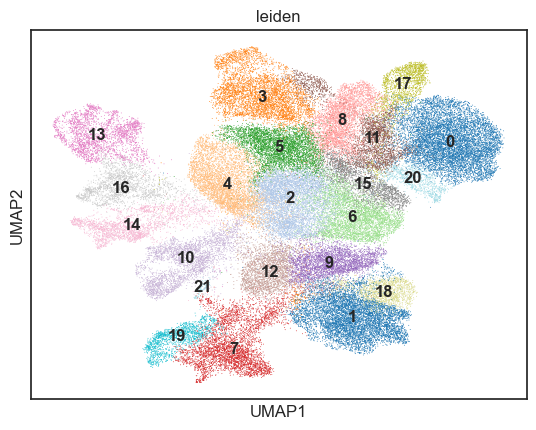

In [90]:
sc.pl.umap(adata, color =['leiden'], palette='tab20', frameon = True, legend_loc = "on data")

# Normalize and Scale Data for UMAP visualization and celltype assignment, but always keep raw data in a different layer for DE

In [91]:
#make a new layer called "counts" by copying the raw X data. this is saved for later DE.
adata.layers['counts'] = adata.X.copy()

In [92]:
#normalizing: the right way to do it is the default method by scanpy : according to nature methods "Comparison of transformations for single-cell RNAseq data")
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

#SO: Raw data is stored in adata.layers['counts']. It was a copy of adata.X before adata.X was normalized.
#Adata.X was normalized and then log1p transformed. Log1p means take the log of (1+data).

# ADATA SAVEPOINT #2

In [93]:
#UPDATE ADATA
adata.write_h5ad('6_27_24_cellbenderclean_adata_norm_scaled.h5ad')

In [94]:
adata

AnnData object with n_obs × n_vars = 74980 × 18173
    obs: 'Sample', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'pct_counts_mt', 'pct_counts_ribo', 'doublet', 'doublet_score', '_scvi_batch', '_scvi_labels', 'leiden'
    var: 'n_cells'
    uns: '_scvi_uuid', '_scvi_manager_uuid', 'neighbors', 'leiden', 'umap', 'leiden_colors', 'log1p'
    obsm: '_scvi_extra_categorical_covs', '_scvi_extra_continuous_covs', 'X_scVI', 'X_umap'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [95]:
adata.uns.markers

AttributeError: 'collections.OrderedDict' object has no attribute 'markers'

# Assign Condition

In [96]:
#Add the column "Condition" to adata.obs
def map_condition(x):
    if 'Zap' in x:
        return 'UVB-dosed'
    else:
        return 'Control'

adata.obs['condition'] = adata.obs.Sample.map(map_condition) #give a new column to adata.obs called condition, labels 'Control' or 'UVB dosed'


In [98]:
adata.obs

,Sample,n_genes,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_20_genes,pct_counts_mt,pct_counts_ribo,doublet,doublet_score,_scvi_batch,_scvi_labels,leiden,condition
CTTCCTTAGCCTGACC-1-Ctrl1,Ctrl1,4838,4838,8.484463,42237,10.651076,13.983001,0.0,0.0,0.0,2.391601e+01,0,0,11,Control
GGAATCTCAATACCTG-1-Ctrl1,Ctrl1,4689,4689,8.453188,39382,10.581090,13.437611,0.0,0.0,0.0,2.391601e+01,0,0,17,Control
AGAGAATTCAAACTGC-1-Ctrl1,Ctrl1,3595,3595,8.187577,38857,10.567669,19.566616,0.0,0.0,0.0,2.786184e+01,0,0,11,Control
ACGTCCTAGAACAAGG-1-Ctrl1,Ctrl1,3938,3938,8.278682,37340,10.527847,17.185324,0.0,0.0,0.0,2.786184e+01,0,0,11,Control
GCTTGGGCAACTGATC-1-Ctrl1,Ctrl1,3858,3858,8.258163,33841,10.429458,18.258917,0.0,0.0,0.0,2.786184e+01,0,0,11,Control
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TATCAGGCATCACGGC-1-Zap4,Zap4,216,216,5.379897,239,5.480639,17.991632,0.0,0.0,0.0,7.023997e-16,0,0,6,UVB-dosed
TTCTTGAGTCCAAGAG-1-Zap4,Zap4,201,201,5.308268,231,5.446737,19.480519,0.0,0.0,0.0,3.303654e-23,0,0,15,UVB-dosed
TCCTCTTCATCGGCCA-1-Zap4,Zap4,212,212,5.361292,250,5.525453,22.400000,0.0,0.0,0.0,4.278883e-02,0,0,9,UVB-dosed
CGAGGAACAAGTCATC-1-Zap4,Zap4,219,219,5.393628,265,5.583496,20.377358,0.0,0.0,0.0,4.478076e-14,0,0,9,UVB-dosed


# Plot the UMAP showing distribution regarding Condition

In [5]:
fig, ax = plt.subplots()

sc.pl.umap(adata, color=['condition'], frameon=True, title='', show=False, ax=ax, palette='bwr')
ax.set_xticks(range(-4,22,2))
ax.set_yticks(range(-8,17,2))
ax.legend(loc='upper left')
matplotlib.pyplot.savefig('6_28_24_UMAP_Condition_Plot.png', dpi='figure')
plt.show()

NameError: name 'matplotlib' is not defined

# Plot the UMAP showing all Leiden Clusters

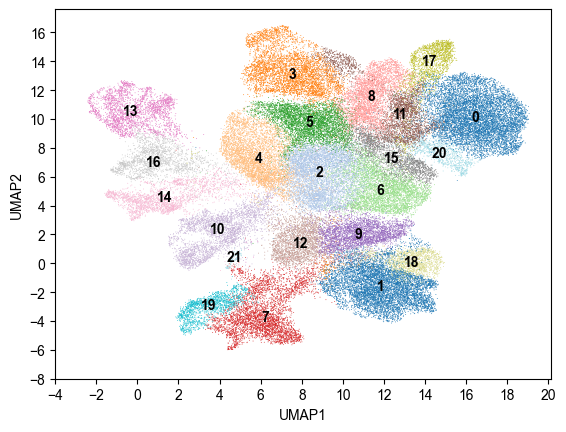

In [26]:
fig, ax = plt.subplots()
%matplotlib inline
sc.pl.umap(adata, color=['leiden'], frameon=True, legend_loc = 'on data', title='', show=False, ax=ax, palette='tab20')
ax.set_xticks(range(-4,22,2))
ax.set_yticks(range(-8,17,2))
matplotlib.pyplot.savefig('C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig1 300dpi/UMAP_AllClusters_Plot_600dpi.png', dpi=600)
plt.show()

# Prepare the Dictionary of Cell Types

In [180]:
#Dictionary- map cell type to cluster. simple groups: phagocytes, red cells, colorless cells, vibratile cells.
cell_type = {"0":"Phagocytes",
"1":"Phagocytes",
"2":"Phagocytes",
"3":"Phagocytes",
"4":"Phagocytes",
"5":"Phagocytes", #NOTE: not confident; shows only prolif markers, no TLRs, no c3. phago based on map alone.
"6":"Phagocytes",
"7":"Vibratile Cells",
"8":"Phagocytes",
"9":"Phagocytes",
"10":"Colorless Cells",
"11":"Phagocytes",
"12":"Phagocytes",
"13":"Red Cells",
"14":"Colorless Cells",
"15":"Phagocytes",
"16":"Red Cells",
"17":"Phagocytes",
"18":"Phagocytes",
"19":"Vibratile Cells",
"20":"Phagocytes",
"21": "Vibratile Cells" #NOTE: not confident; shows only dynein. Assigned vib based on map position.
    }

adata.obs['cell_type'] = adata.obs.leiden.map(cell_type)

# To assign cell types, look for marker genes of phagocytes, red cells, colorless cells, and vibratile cells

In [112]:
#note: this is a quick way to do DE to find marker genes, but not reccd for actual DE analysis.
sc.tl.rank_genes_groups(adata, groupby = 'leiden')
markers = sc.get.rank_genes_groups_df(adata, group = None)
markers = markers[(markers.pvals_adj < 0.05) & (markers.logfoldchanges > 0.5)]
adata.uns['markers'] = markers

C:\Users\Riss Kellogg\miniconda3\envs\sc2024\lib\site-packages\scanpy\tools\_rank_genes_groups.py:429: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
C:\Users\Riss Kellogg\miniconda3\envs\sc2024\lib\site-packages\scanpy\tools\_rank_genes_groups.py:431: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
C:\Users\Riss Kellogg\miniconda3\envs\sc2024\lib\site-packages\scanpy\tools\_rank_genes_groups.py:434: Performanc

In [114]:
adata.uns['markers'].names

0                 ATP6
1                 COX3
2            LOC579510
3            LOC588119
4            LOC593238
              ...     
382831    LOC100893826
382832    LOC115918496
382833       LOC582943
382834       LOC764453
382835       LOC579498
Name: names, Length: 54582, dtype: object

# ADATA SAVE POINT

In [181]:
adata

AnnData object with n_obs × n_vars = 74980 × 18173
    obs: 'Sample', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'pct_counts_mt', 'pct_counts_ribo', 'doublet', 'doublet_score', '_scvi_batch', '_scvi_labels', 'leiden', 'condition', 'cell_type'
    var: 'n_cells'
    uns: '_scvi_uuid', '_scvi_manager_uuid', 'neighbors', 'leiden', 'umap', 'leiden_colors', 'log1p', 'condition_colors', 'rank_genes_groups', 'markers'
    obsm: '_scvi_extra_categorical_covs', '_scvi_extra_continuous_covs', 'X_scVI', 'X_umap'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [182]:
#UPDATE ADATA
#NOTE: HAVE TO REDO ADATA.UNS.MARKERS EVERYTIME... it wont let me save with this...
adata.write_h5ad('6_27_24_cellbenderclean_adata_norm_scaled.h5ad')

... storing 'cell_type' as categorical


TypeError: Can't implicitly convert non-string objects to strings

# Map LOC name to Gene name using a lookup table dictionary

In [17]:
import pandas as pd

#Read in the mapping excel file
excel_file = 'SpurpLOClookuptable.xlsx'
name_mapping_df = pd.read_excel(excel_file)

In [18]:
name_mapping_df

,Gene_symbol,Gene_name,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,LOC115919120,coiled-coil domain-containing protein 77-like,ECB-GENE-23008870,7668,115919120,NaN,NaN
1,LOC115923689,histone H2A-like,ECB-GENE-23008874,7668,115923689,NaN,NaN
2,LOC115921875,histone H2B,ECB-GENE-23008878,7668,115921875,NaN,NaN
3,LOC115922805,"histone H3, embryonic-like",ECB-GENE-23008882,7668,115922805,NaN,NaN
4,LOC115919121,"histone H3, embryonic-like",ECB-GENE-23008886,7668,115919121,NaN,NaN
...,...,...,...,...,...,...,...
50680,ppara2,peroxisome proliferator activated receptor alp...,ECB-GENE-24495484,133434,110991238,NaN,NaN
50681,LOC110991243,43 kDa receptor-associated protein of the syna...,ECB-GENE-24495492,133434,110991243,NaN,NaN
50682,LOC110991245,synaptotagmin-5,ECB-GENE-24495504,133434,110991245,NaN,NaN
50683,LOC110991255,MPN domain-containing protein-like,ECB-GENE-24495512,133434,110991255,NaN,NaN


In [19]:
#Create the dictionary from that excel file above
name_mapping_dict = dict(zip(name_mapping_df['Gene_symbol'], name_mapping_df['Gene_name']))

In [4]:
#name_mapping_dict

In [122]:
#add these new names to the "markers" dataframe
markers['new_names'] = markers['names'].apply(lambda x: name_mapping_df.loc[name_mapping_df['Gene_symbol']==x, 'Gene_name'].values[0] if x in name_mapping_df['Gene_symbol'].values else x)

In [123]:
markers

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
0,0,ATP6,161.277298,1.542205,0.000000,0.000000,ATP6
1,0,COX3,159.784622,1.557315,0.000000,0.000000,COX3
2,0,LOC579510,134.916794,2.309399,0.000000,0.000000,filamin-A
3,0,LOC588119,128.610947,1.788774,0.000000,0.000000,gelsolin-like protein 2
4,0,LOC593238,127.508080,2.125052,0.000000,0.000000,tetraspanin-4
...,...,...,...,...,...,...,...
382831,21,LOC100893826,2.256484,3.248393,0.025929,0.049181,uncharacterized LOC100893826
382832,21,LOC115918496,2.253776,2.338540,0.026103,0.049507,neurofilament heavy polypeptide-like
382833,21,LOC582943,2.252624,0.635419,0.026174,0.049636,LOC582943
382834,21,LOC764453,2.250038,5.832238,0.026349,0.049957,phospholipid scramblase 1


# Look for (now annotated) Marker Genes

# Red Cells

In [124]:
#RED CELLS
#Start with cell types you know are going to be in the data
#LOC588806 is sp-pks1, the only marker gene i know (for red cells) IN DATASET
#LOC115922158 = sp-pks2, not in dataset
#LOC592147 = sp-pks2 (?another one), not in dataset
#sc.pl.umap(adata, color = ['LOC588806'], frameon= False, layer = 'scvi_normalized')

In [126]:
markers[markers.names == 'LOC588806']

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
236252,13,LOC588806,116.790344,6.457880,0.0,0.0,probable polyketide synthase 1
290771,16,LOC588806,49.108288,5.133327,0.0,0.0,probable polyketide synthase 1


In [127]:
markers[markers.names == 'LOC115922158']

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


In [128]:
markers[markers.names == 'LOC592147']

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


# Phagocytes

LOC115920362	toll-like receptor 13
LOC578987	toll-like receptor 13
LOC115926438	toll-like receptor 13
LOC592383	toll-like receptor 13
LOC105437054	toll-like receptor 13
LOC115923185	toll-like receptor 13
LOC115923192	toll-like receptor 13
LOC105440385	toll-like receptor 13
LOC115926210	toll-like receptor 13
LOC115926656	toll-like receptor 13
LOC115926361	toll-like receptor 13
LOC754483	toll-like receptor 13
LOC105443904	toll-like receptor 13
LOC752489	toll-like receptor 13
LOC100887890	toll-like receptor 13
LOC115929085	toll-like receptor 2
LOC115929088	toll-like receptor 2
LOC115924324	toll-like receptor 2 type-2
LOC115924329	toll-like receptor 2 type-2
LOC583603	toll-like receptor 2 type-2
LOC115920561	toll-like receptor 2 type-2
LOC589241	toll-like receptor 3
LOC115921257	toll-like receptor 3
LOC115921855	toll-like receptor 3
LOC100891845	toll-like receptor 3
LOC115922846	toll-like receptor 3
LOC100893588	toll-like receptor 3
LOC100892728	toll-like receptor 3
LOC593135	toll-like receptor 3
LOC590735	toll-like receptor 3
LOC591392	toll-like receptor 3
LOC757162	toll-like receptor 3
LOC105446965	toll-like receptor 3
LOC105444115	toll-like receptor 3
LOC115925040	toll-like receptor 3
LOC590412	toll-like receptor 3
LOC594808	toll-like receptor 3
LOC115925979	toll-like receptor 3
LOC115925984	toll-like receptor 3
LOC115925906	toll-like receptor 3
LOC105445890	toll-like receptor 3
LOC105438617	toll-like receptor 3
LOC105436704	toll-like receptor 3
LOC105442321	toll-like receptor 3
LOC590785	toll-like receptor 3
LOC105440004	toll-like receptor 3
LOC115927477	toll-like receptor 3
LOC115927745	toll-like receptor 3
LOC105436587	toll-like receptor 3
LOC105439388	toll-like receptor 3
LOC105445616	toll-like receptor 3
LOC115927853	toll-like receptor 3
LOC115928239	toll-like receptor 3
LOC115927855	toll-like receptor 3
LOC105447490	toll-like receptor 3
LOC115929900	toll-like receptor 3
LOC115919778	toll-like receptor 3
LOC105447508	toll-like receptor 3
LOC105438910	toll-like receptor 3
LOC115919878	toll-like receptor 3
LOC115919967	toll-like receptor 3
LOC121408626	toll-like receptor 3
LOC100893618	toll-like receptor 4
LOC105440421	toll-like receptor 4
LOC105438647	toll-like receptor 4
LOC754279	toll-like receptor 4
LOC115923189	toll-like receptor 4
LOC115923190	toll-like receptor 4
LOC115923194	toll-like receptor 4
LOC115923196	toll-like receptor 4
LOC584045	toll-like receptor 4
LOC115923265	toll-like receptor 4
LOC105442526	toll-like receptor 4
LOC105444403	toll-like receptor 4
LOC115923479	toll-like receptor 4
LOC115923751	toll-like receptor 4
LOC100891668	toll-like receptor 4
LOC764601	toll-like receptor 4
LOC115924323	toll-like receptor 4
LOC115924268	toll-like receptor 4
LOC115924325	toll-like receptor 4
LOC115924330	toll-like receptor 4
LOC105437272	toll-like receptor 4
LOC752672	toll-like receptor 4
LOC582847	toll-like receptor 4
LOC105436867	toll-like receptor 4
LOC115925982	toll-like receptor 4
LOC115925983	toll-like receptor 4
LOC115926194	toll-like receptor 4
LOC105446117	toll-like receptor 4
LOC105437589	toll-like receptor 4
LOC105444833	toll-like receptor 4
LOC105440655	toll-like receptor 4
LOC115926498	toll-like receptor 4
LOC115926560	toll-like receptor 4
LOC105439406	toll-like receptor 4
LOC582609	toll-like receptor 4
LOC115927854	toll-like receptor 4
LOC115927876	toll-like receptor 4
LOC115927877	toll-like receptor 4
LOC115927878	toll-like receptor 4
LOC105442298	toll-like receptor 4
LOC585150	toll-like receptor 4
LOC115927946	toll-like receptor 4
LOC105445299	toll-like receptor 4
LOC115927999	toll-like receptor 4
LOC105438620	toll-like receptor 4
LOC105442573	toll-like receptor 4
LOC115920022	toll-like receptor 4
LOC105440143	toll-like receptor 4
LOC105442957	toll-like receptor 4
LOC115929919	toll-like receptor 5
LOC115923732	toll-like receptor 5
Tlr1.1	toll-like receptor Tlr1.1
Tlr1.2	toll-like receptor Tlr1.2
LOC373485	toll-like receptor Tlr2.1
LOC100890666	toll-like receptor Tollo
LOC105438943	toll-like receptor Tollo
LOC579765	toll-like receptor Tollo
LOC115926002	toll-like receptor Tollo
LOC100888512	toll-like receptor Tollo
LOC121411578	toll-like receptor Tollo
LOC121427692	toll-like receptor Tollo
LOC119726567	toll-like receptor Tollo
LOC119746052	toll-like receptor Tollo
LOC110979067	toll-like receptor Tollo
LOC110989538	toll-like receptor Tollo


In [129]:
#SpTrf phagoytes
markers[markers.names == '185/333']

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
183,0,185/333,55.907455,3.014632,0.000000e+00,0.000000e+00,185/333
200623,11,185/333,11.521449,1.155822,4.238234e-30,2.684609e-29,185/333
363669,20,185/333,18.479408,2.698142,3.210176e-66,9.563692e-65,185/333


In [130]:
#Sp-B7L3 phagocytes
markers[markers.names == 'LOC762504'] 

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
20581,1,LOC762504,4.108355,0.967073,4.022271e-05,7.121649e-05,kin of IRRE-like protein 1
163966,9,LOC762504,11.476089,4.596381,6.183458e-30,5.012131e-29,kin of IRRE-like protein 1
218641,12,LOC762504,4.631562,2.122711,3.799918e-06,1.227443e-05,kin of IRRE-like protein 1
328747,18,LOC762504,2.739896,1.265471,6.210294e-03,1.026090e-02,kin of IRRE-like protein 1


In [132]:
#TLR phagocytes
markers[markers.names == 'Tlr1.1'] #TLR1.1

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
1886,0,Tlr1.1,12.934290,1.775080,5.587224e-38,2.642806e-37,toll-like receptor Tlr1.1
73326,4,Tlr1.1,8.117768,2.098091,5.957924e-16,3.465856e-15,toll-like receptor Tlr1.1
111709,6,Tlr1.1,4.182692,1.489905,2.934124e-05,8.589214e-05,toll-like receptor Tlr1.1


In [133]:
markers[markers.names == 'LOC115929085'] #TLR2

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


In [135]:
#TLR phagocytes
markers[markers.names == 'LOC105442321'] #TLR3

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
18318,1,LOC105442321,41.444874,1.747903,0.000000e+00,0.000000e+00,toll-like receptor 3
145545,8,LOC105442321,34.780193,1.695756,2.767603e-232,1.229723e-230,toll-like receptor 3
200172,11,LOC105442321,23.983959,1.569010,1.309893e-116,3.005641e-115,toll-like receptor 3
255128,14,LOC105442321,6.554852,0.523326,6.787321e-11,3.507136e-10,toll-like receptor 3
327245,18,LOC105442321,22.640886,1.772055,2.752870e-99,7.116346e-98,toll-like receptor 3
363540,20,LOC105442321,25.814528,2.283239,2.818388e-114,1.803471e-112,toll-like receptor 3


In [136]:
markers[markers.names == 'LOC105446117'] #TLR4

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
37137,2,LOC105446117,8.218873,1.164423,2.493324e-16,1.667691e-15,toll-like receptor 4
55062,3,LOC105446117,5.685739,0.995697,1.374478e-08,2.847839e-08,toll-like receptor 4
72962,4,LOC105446117,13.681010,1.850071,7.484582e-42,7.675474e-41,toll-like receptor 4
110274,6,LOC105446117,7.270035,1.335528,4.190488e-13,2.085545e-12,toll-like receptor 4
164253,9,LOC105446117,8.100979,1.585072,7.481274e-16,4.071794e-15,toll-like receptor 4


In [137]:
markers[markers.names == 'LOC115929919'] #TlR5

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


In [138]:
markers[markers.names == 'LOC115926210'] #TLR13

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
2273,0,LOC115926210,10.564922,1.486151,5.959624e-26,2.219349e-25,toll-like receptor 13
146117,8,LOC115926210,11.703129,2.748456,4.056762e-31,2.722435e-30,toll-like receptor 13
201388,11,LOC115926210,4.620898,1.356595,3.980076e-06,8.609681e-06,toll-like receptor 13
328368,18,LOC115926210,4.045293,1.671027,5.464822e-05,1.085261e-04,toll-like receptor 13
364819,20,LOC115926210,5.331151,2.040454,1.194119e-07,3.973037e-07,toll-like receptor 13


In [139]:
markers[markers.names == 'LOC100890666'] #Tollo

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
36631,2,LOC100890666,14.037817,1.549432,4.727822e-44,6.890033e-43,toll-like receptor Tollo
109666,6,LOC100890666,11.063129,1.494209,4.233008e-28,3.403825e-27,toll-like receptor Tollo
164782,9,LOC100890666,5.612957,0.762269,2.141816e-08,7.689297e-08,toll-like receptor Tollo
273279,15,LOC100890666,6.695531,1.286005,2.772625e-11,1.246584e-10,toll-like receptor Tollo


In [141]:
#Cells with complement c3 (note: all phagocyte clusters)
markers[markers.names == 'c3']

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
123,0,c3,64.607079,1.013855,0.000000e+00,0.000000e+00,complement C3
36346,2,c3,70.699287,1.459009,0.000000e+00,0.000000e+00,complement C3
72752,4,c3,62.146976,1.204319,0.000000e+00,0.000000e+00,complement C3
109038,6,c3,119.146767,2.654159,0.000000e+00,0.000000e+00,complement C3
163561,9,c3,105.450546,2.112320,0.000000e+00,0.000000e+00,complement C3
200106,11,c3,28.275974,0.793787,3.249982e-158,1.056564e-156,complement C3


# Vibratile Cells

In [142]:
markers[markers.names == 'LOC591536'] #Sp-P2rx4

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
127267,7,LOC591536,39.996872,4.764126,7.726635e-298,2.400276e-296,P2X purinoceptor 4
345356,19,LOC591536,31.276432,4.588307,3.963374e-168,4.596451e-167,P2X purinoceptor 4


In [144]:
markers[markers.names == 'FoxJ1']

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
19941,1,FoxJ1,6.764288,1.153286,1.431569e-11,3.774797e-11,FoxJ1
127734,7,FoxJ1,11.533333,3.097376,2.475213e-30,1.508958e-29,FoxJ1
345963,19,FoxJ1,8.145037,3.095647,7.529063e-16,2.024348e-15,FoxJ1
364563,20,FoxJ1,6.557145,2.245531,8.574341e-11,3.631357e-10,FoxJ1


In [146]:
# Cells doing clotting (vibratile cells)
markers[markers.names == 'AMAS4']

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
127215,7,AMAS4,114.527260,6.081396,0.0,0.0,AMAS4
345291,19,AMAS4,126.794769,6.270511,0.0,0.0,AMAS4


In [148]:
#Check for dynein (to indicate flagella = vibs)
markers[markers.names == 'LOC762758']

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
127986,7,LOC762758,8.784042,2.382532,2.229077e-18,1.017814e-17,"dynein heavy chain 9, axonemal"
274637,15,LOC762758,2.898104,1.209165,3.794524e-03,9.489181e-03,"dynein heavy chain 9, axonemal"
346561,19,LOC762758,4.452593,1.775139,9.064001e-06,1.595197e-05,"dynein heavy chain 9, axonemal"
382406,21,LOC762758,2.936626,3.864895,4.008562e-03,8.258515e-03,"dynein heavy chain 9, axonemal"


# Colorless Cells

In [149]:
#Cells with bactericidal LOC100889613 (Assigned cluster as "bactericidal colorless cells")
markers[markers.names == 'LOC100889613']

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
181783,10,LOC100889613,39.605766,7.863503,7.361043e-278,4.206674e-276,bactericidal permeability-increasing protein


In [150]:
#DD104, DD104 protein, upregulated upon bacterial challenge and trauma
markers[markers.names == 'DD104']

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
236750,13,DD104,14.799458,1.321761,1.037971e-47,6.148320e-47,"DD104 protein, upregulated upon bacterial chal..."
254422,14,DD104,102.874252,7.939331,0.000000e+00,0.000000e+00,"DD104 protein, upregulated upon bacterial chal..."
290768,16,DD104,59.468147,4.727993,0.000000e+00,0.000000e+00,"DD104 protein, upregulated upon bacterial chal..."


In [152]:
#LOC587263 lysozyme
#LOC753728 strongylocin2
#Going to call these "cytotoxic colorless cells"
markers[markers.names == 'LOC587263']

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
236707,13,LOC587263,15.740224,2.650458,1.906376e-53,1.198774e-52,lysozyme
254556,14,LOC587263,17.452215,5.502024,3.539125e-64,6.871422e-63,lysozyme
291436,16,LOC587263,6.645180,1.787004,3.898436e-11,1.657610e-10,lysozyme


In [154]:
markers[markers.names == 'LOC753728'] #strongylocin2

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
129139,7,LOC753728,3.871595,0.580666,1.094952e-04,2.459649e-04,strongylocin 2
254539,14,LOC753728,18.577818,5.357795,6.327789e-72,1.359278e-70,strongylocin 2
291967,16,LOC753728,4.145279,0.970216,3.533526e-05,1.037731e-04,strongylocin 2
310243,17,LOC753728,3.669959,0.819126,2.496180e-04,4.093401e-04,strongylocin 2
328343,18,LOC753728,4.139829,1.082025,3.645463e-05,7.349568e-05,strongylocin 2


# DNA Repair Enzymes

In [156]:
#Find XRCC1 DNA repair protein
markers[markers.names == 'LOC580530']

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
76120,4,LOC580530,2.523368,0.685511,0.011653,0.023833,LOC580530
186649,10,LOC580530,2.290239,0.755334,0.022070,0.042574,LOC580530
238245,13,LOC580530,4.896630,1.543429,0.000001,0.000002,LOC580530


In [157]:
#UV genes
#UVrag LOC586516
#UV RAD23 LOC578143
#sc.pl.umap(adata, color = ['LOC586516','LOC578143'], frameon= False, layer = 'scvi_normalized')
markers[markers.names == 'LOC578143'] #RAD23

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
20371,1,LOC578143,4.911672,0.620580,9.200922e-07,0.000002,UV excision repair protein RAD23 homolog A
309983,17,LOC578143,4.786512,1.510785,1.841479e-06,0.000003,UV excision repair protein RAD23 homolog A
365212,20,LOC578143,4.099051,1.079054,4.463686e-05,0.000121,UV excision repair protein RAD23 homolog A


In [158]:
markers[markers.names == 'LOC586516'] #UVrag

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
114006,6,LOC586516,2.329186,0.543003,1.989088e-02,3.787480e-02,LOC586516
182453,10,LOC586516,8.238603,1.752089,2.517952e-16,1.694768e-15,LOC586516
237738,13,LOC586516,6.424697,1.285914,1.558836e-10,4.145263e-10,LOC586516
255716,14,LOC586516,3.764024,0.999421,1.712457e-04,5.414142e-04,LOC586516
292907,16,LOC586516,2.336432,0.806913,1.956828e-02,4.212941e-02,LOC586516


# Markers of Proliferation (dividing cells)

In [159]:
#Check for proliferation markers
markers[markers.names == 'LOC765052'] #PCNA; cell division. proliferating cell nuclear antigen

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
54869,3,LOC765052,8.766832,1.554029,2.477731e-18,7.555002e-18,proliferating cell nuclear antigen
73636,4,LOC765052,6.293490,0.921953,3.365207e-10,1.496718e-09,proliferating cell nuclear antigen
91599,5,LOC765052,6.392400,0.963682,1.787005e-10,8.439514e-10,proliferating cell nuclear antigen
236611,13,LOC765052,18.714851,3.139049,2.102810e-73,1.577151e-72,proliferating cell nuclear antigen


In [161]:
#Check for proliferation markers
markers[markers.names == 'LOC100890576'] #PCNA; cell division. PCNA-associated factor.

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
55281,3,LOC100890576,3.987553,0.981633,6.769516e-05,1.181318e-04,PCNA-associated factor
73554,4,LOC100890576,6.636569,1.299198,3.551159e-11,1.677983e-10,PCNA-associated factor
185786,10,LOC100890576,2.783820,0.651996,5.403044e-03,1.196995e-02,PCNA-associated factor
236676,13,LOC100890576,16.655079,3.951958,3.120761e-59,2.069084e-58,PCNA-associated factor


In [162]:
markers[markers.names == 'LOC115918456'] #PCNA; cell division. proliferating cell nuclear antigen-like

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
55087,3,LOC115918456,5.513335,1.135229,3.694747e-08,7.483799e-08,proliferating cell nuclear antigen-like
74067,4,LOC115918456,5.040501,0.770380,4.798719e-07,1.705596e-06,proliferating cell nuclear antigen-like
91611,5,LOC115918456,6.295191,1.035965,3.339112e-10,1.549979e-09,proliferating cell nuclear antigen-like
129168,7,LOC115918456,3.823159,0.873847,1.335494e-04,2.974620e-04,proliferating cell nuclear antigen-like
184462,10,LOC115918456,3.787600,0.740512,1.548260e-04,4.452687e-04,proliferating cell nuclear antigen-like
236777,13,LOC115918456,14.216693,2.733881,3.128394e-44,1.767246e-43,proliferating cell nuclear antigen-like


In [163]:
markers[markers.names == 'LOC579977'] #histone H3, embryonic

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
2711,0,LOC579977,8.393022,1.459540,5.370313e-17,1.575633e-16,"histone H3, embryonic"
55242,3,LOC579977,4.205628,1.574761,2.649189e-05,4.730174e-05,"histone H3, embryonic"
73990,4,LOC579977,5.230389,1.493062,1.761062e-07,6.495592e-07,"histone H3, embryonic"
237526,13,LOC579977,7.359704,2.558069,2.459760e-13,7.425452e-13,"histone H3, embryonic"


In [164]:
markers[markers.names == 'LOC373245'] #cyclin D

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
36875,2,LOC373245,10.229199,0.789970,2.301691e-24,2.070724e-23,cyclin D
54782,3,LOC373245,11.513050,1.083155,2.670337e-30,1.067959e-29,cyclin D
91068,5,LOC373245,18.136580,1.358612,3.539187e-71,5.506647e-70,cyclin D
164411,9,LOC373245,7.126526,0.743790,1.241538e-12,5.831600e-12,cyclin D
272978,15,LOC373245,9.318521,1.416854,2.978845e-20,1.980050e-19,cyclin D


In [165]:
markers[markers.names == 'LOC110980132'] #cyclin E

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


In [166]:
markers[markers.names == 'ccne1'] #cyclin E

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


In [167]:
markers[markers.names == 'LOC110984714'] #cyclin B

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


In [168]:
markers[markers.names == 'ccnb2'] #cyclin B

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


In [169]:
markers[markers.names == 'LOC110980811'] #TERT

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


In [170]:
markers[markers.names == 'tert'] #TERT

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


In [171]:
markers[markers.names == 'myc'] #MyC

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


# Stem-ness Markers

In [172]:
#Check for stem-cell markers (piwi and vasa)
markers[markers.names == 'piwil1'] #piwi1

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


In [174]:
markers[markers.names == 'LOC583253'] #piwi2; gene name is seali

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
186262,10,LOC583253,2.514065,1.036079,0.011983,0.024549,seali
239297,13,LOC583253,3.005999,0.946384,0.002671,0.004480,seali


In [175]:
markers[markers.names == 'seali'] #piwi2; gene name is seali

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


In [176]:
markers[markers.names == 'LOC373434'] #piwi3

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names
39744,2,LOC373434,2.818015,0.687476,0.004848,0.011163,LOC373434
75294,4,LOC373434,3.227184,0.626304,0.001258,0.003061,LOC373434
114049,6,LOC373434,2.297083,0.681854,0.021657,0.040947,LOC373434
165964,9,LOC373434,3.205773,0.957241,0.001359,0.003269,LOC373434
183794,10,LOC373434,4.557330,1.194550,0.000005,0.000019,LOC373434


In [177]:
markers[markers.names == 'ddx4'] #Sp-vasa

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


In [178]:
markers[markers.names == 'LOC110980149'] #Sp-vasa 

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


In [179]:
#Check for Kruppel-like factors (Zn fingers); transcription factors essential for maintaining pluripotency

markers[markers.names == 'LOC373243'] #Sp-Kruppel

,group,names,scores,logfoldchanges,pvals,pvals_adj,new_names


# Use Scanpy to plot a UMAP showing conditions

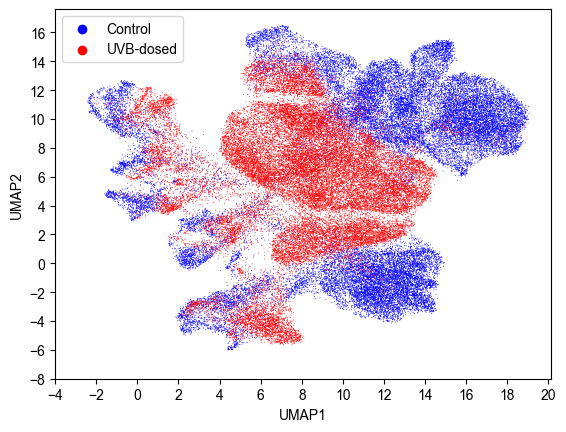

In [28]:
fig, ax = plt.subplots()

sc.pl.umap(adata, color=['condition'], frameon=True, title='', show=False, ax=ax, palette='bwr')
ax.set_xticks(range(-4,22,2))
ax.set_yticks(range(-8,17,2))
ax.legend(loc='upper left')

matplotlib.pyplot.savefig('C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig1 300dpi/UMAP_Condition_600dpi.png', dpi=600)
plt.show()

# Use Scanpy to plot a UMAP showing distribution of assigned cell types

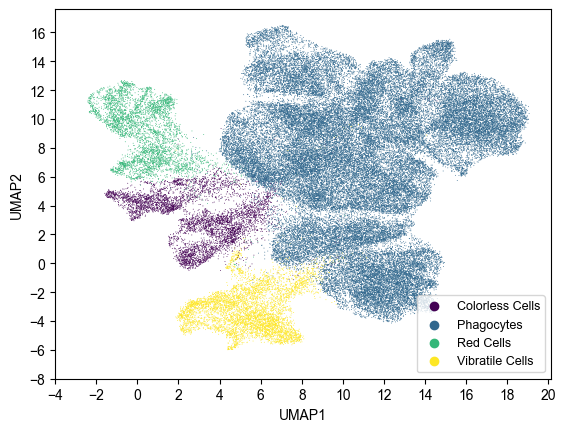

In [24]:
fig, ax = plt.subplots()

sc.pl.umap(adata, color= 'cell_type', frameon = True, title='', show=False, ax=ax, palette= 'viridis')
ax.set_xticks(range(-4,22,2))
ax.set_yticks(range(-8,17,2))
ax.legend(loc='lower right', fontsize='9')
matplotlib.pyplot.savefig('C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig1 300dpi/UMAP_CellTypes_600dpi.png', dpi=600)
plt.show()

# Cell Counting: Plot using Matplotlib and Seaborn

In [424]:
#Cell Counting: How many zap and control cells are in each cluster?
#Count # of cells in each cluster
cluster_tot_cells = adata.obs.groupby(['leiden']).count() 
cluster_tot_cells = dict(zip(cluster_tot_cells.index, cluster_tot_cells.doublet)) #gives a dictionary of sample:total cells
cluster_tot_cells


{'0': 8431,
 '1': 7164,
 '2': 5586,
 '3': 4879,
 '4': 4722,
 '5': 4526,
 '6': 4521,
 '7': 4287,
 '8': 3828,
 '9': 3374,
 '10': 3093,
 '11': 2952,
 '12': 2678,
 '13': 2564,
 '14': 2315,
 '15': 1998,
 '16': 1940,
 '17': 1712,
 '18': 1649,
 '19': 1602,
 '20': 1043,
 '21': 116}

In [432]:
#Group by Condition (ctrl vs zap),
cluster_type_counts = adata.obs.groupby(['leiden', 'condition']).count()
cluster_type_counts = cluster_type_counts[cluster_type_counts.sum(axis = 1) > 0].reset_index() #show only rows with at least 1 cell
cluster_type_counts = cluster_type_counts[cluster_type_counts.columns[0:3]] #keep only the first 4 columns

#cluster_type_counts.rename(columns = {'Sample':'Cells_in_condition'}, inplace = True)
cluster_type_counts.to_csv('fraction of ctrl and zap cells in each cluster.csv')

In [431]:
#Add a new total_cells column
cluster_type_counts['total_cells'] = cluster_type_counts.Sample.map(cluster_tot_cells).astype(int) #cluster_tot_cells is the dictionary made above
cluster_type_counts['frequency'] = cellcluster_type_counts.Cells_in_condition / cell_type_counts.total_cells #add a frequency column (cells / total cells)
#cell_type_counts

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer

In [185]:
#CELL COUNTING
# "Condition" label was already assigned to each cell above
#Distinguish control samples from zapped samples
#adata.obs.Sample.unique().tolist()

In [30]:
#For frequency, Count the number of cells in each cell type, AND the number of cells total in each sample
#Total cells in each sample
num_tot_cells = adata.obs.groupby(['Sample']).count() 
num_tot_cells = dict(zip(num_tot_cells.index, num_tot_cells.doublet)) #gives a dictionary of sample:total cells
num_tot_cells

C:\Users\Riss Kellogg\AppData\Local\Temp\ipykernel_22956\2820134817.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  num_tot_cells = adata.obs.groupby(['Sample']).count()


{'Ctrl1': 14986,
 'Ctrl3': 13870,
 'Ctrl4': 9726,
 'Zap1': 12538,
 'Zap3': 8682,
 'Zap4': 15178}

In [31]:
#Group by Sample, Condition (ctrl vs zap), and cell type NOTE: "doublet" column  is not really doublets, its total cells
cell_type_counts = adata.obs.groupby(['Sample', 'condition', 'cell_type']).count()
cell_type_counts = cell_type_counts[cell_type_counts.sum(axis = 1) > 0].reset_index() #show only rows with at least 1 cell
cell_type_counts = cell_type_counts[cell_type_counts.columns[0:4]] #keep only the first 4 columns

cell_type_counts.rename(columns = {'n_genes':'cell_type_count'}, inplace = True)
cell_type_counts

C:\Users\Riss Kellogg\AppData\Local\Temp\ipykernel_22956\4194913417.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cell_type_counts = adata.obs.groupby(['Sample', 'condition', 'cell_type']).count()


,Sample,condition,cell_type,cell_type_count
0,Ctrl1,Control,Colorless Cells,1183
1,Ctrl1,Control,Phagocytes,12421
2,Ctrl1,Control,Red Cells,467
3,Ctrl1,Control,Vibratile Cells,915
4,Ctrl3,Control,Colorless Cells,654
5,Ctrl3,Control,Phagocytes,10381
6,Ctrl3,Control,Red Cells,1251
7,Ctrl3,Control,Vibratile Cells,1584
8,Ctrl4,Control,Colorless Cells,1065
9,Ctrl4,Control,Phagocytes,7598


In [32]:
#Add a new total_cells column
cell_type_counts['total_cells'] = cell_type_counts.Sample.map(num_tot_cells).astype(int) #num_tot_cells is the dictionary made above
cell_type_counts['frequency'] = cell_type_counts.cell_type_count / cell_type_counts.total_cells #add a frequency column (cells / total cells)
#cell_type_counts

C:\Users\Riss Kellogg\AppData\Local\Temp\ipykernel_22956\118286589.py:7: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax2 = sns.swarmplot(data = cell_type_counts, x = 'cell_type', y = 'frequency', hue = 'condition', color = 'k', size = 6, dodge= True, legend = False)


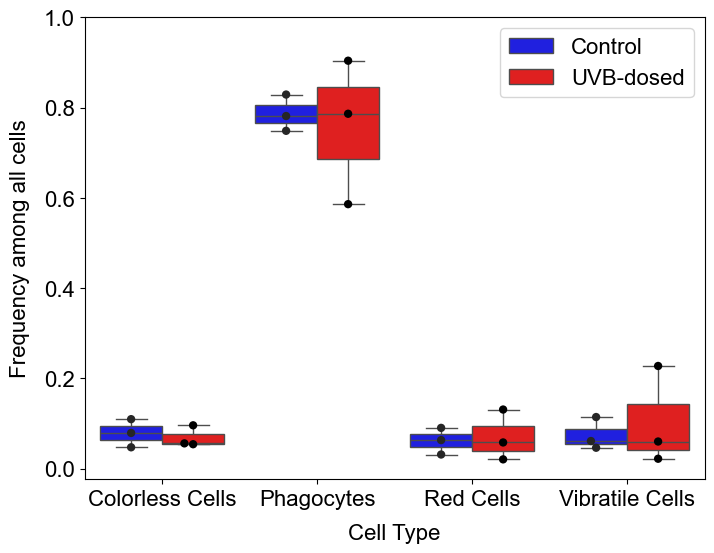

In [33]:
#Plot the frequency
import matplotlib.pyplot as plt
plt.figure(figsize = (8,6))

my_pal={'Control':'blue', 'UVB-dosed':'red'}
ax = sns.boxplot(data = cell_type_counts, x = 'cell_type', y = 'frequency', hue = 'condition', palette=my_pal)
ax2 = sns.swarmplot(data = cell_type_counts, x = 'cell_type', y = 'frequency', hue = 'condition', color = 'k', size = 6, dodge= True, legend = False)

for box in ax.artists:
    box.set_edgecolor('black')

#sns.move_legend(ax, "upper left")
#ax.legend_.texts[0].set_text('Control')
#ax.legend_.texts[1].set_text('Zap')

sns.move_legend(
    ax, "lower center",
    bbox_to_anchor=(.8, .8), ncol=4, title=None, frameon=False,
)

plt.ylabel('Frequency among all cells', fontsize=16, labelpad=10)
plt.xlabel('Cell Type', labelpad=10, fontsize= 16)
plt.xticks(rotation = 0, rotation_mode = 'anchor', fontsize = 16)
plt.yticks(np.arange(0,1.1,step=.2), fontsize=16)
plt.legend(loc='upper right', fontsize=16)

matplotlib.pyplot.savefig('C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig1 300dpi/BoxPlot_CellTypeFrequency_600dpi.png', dpi=600)
plt.show()


# SCVI Differential Expression Analysis do this !!!!ONCE ONLY!!!!, save output as dataframe

In [12]:
#DE analysis needs to use RAW DATA. Recall that above, adata.X became normalized and log1p transformed for UMAP visualization and celltype assignment purposes.
#These were the commands:
#sc.pp.normalize_total(adata)
#sc.pp.log1p(adata)

#HOWEVER... DE analysis needs to be done on RAW DATA. not normalized. 
#I stored the raw data (that is, adata.X before it was normalized and log1p transformed) with this command:
#adata.layers['counts']=adata.X.copy()
#So the raw adata.X data is in adata.layers['counts']

#Take a look at adata.layers['counts'] to see that the numbers are in fact whole integers:
# Print the first 10 rows and columns of the raw count data
#print(adata.layers['counts'][:10, :10])
#there they are! The raw data.

#OK so having that stored in that 'counts' layer is confusing (and I forgot...). So let's store it in adata.raw instead.

import scanpy as sc

# Create a new AnnData object with the raw counts and variable annotations
adata_raw = sc.AnnData(X=adata.layers['counts'], var=adata.var.copy())

# Assign it to adata.raw
adata.raw = adata_raw

# Verify that the raw data is stored correctly
print("Raw data stored in adata.raw.X:")
#print(adata.raw.X[:10, :10])




Raw data stored in adata.raw.X:


In [19]:
#Check adata.X
print(adata.X[:3, :3])

  (0, 0)	11
  (0, 1)	252
  (0, 2)	40
  (1, 0)	3
  (1, 1)	170
  (1, 2)	33
  (2, 0)	15
  (2, 1)	457
  (2, 2)	50


In [7]:
print(adata.layers['counts'][:3, :3])

  (0, 0)	11
  (0, 1)	252
  (0, 2)	40
  (1, 0)	3
  (1, 1)	170
  (1, 2)	33
  (2, 0)	15
  (2, 1)	457
  (2, 2)	50


In [20]:
print(adata.raw.var_names[:3])

Index(['ATP8', 'COX1', 'ND5'], dtype='object')


In [9]:
# RUN THIS ONCE!!! DO NOT REPEAT; YOU WILL GET SLIGHTLY DIFFERENT RESULTS EVERY TIME DUE TO MODEL.DIFFERENTIAL_EXPRESSION.
# Saved output to excel file, used for heatmap in R; reread in here as pandas dataframe

In [9]:
#Test if model.diff_express just calls adata.X by default. Save the current adata.X as a layer as backup
#adata.layers['normalized_counts']=adata.X.copy()
#adata.write_h5ad('9_6_24_cellbenderclean_adata_norm_scaled_rawdatasaved.h5ad')

In [11]:
adata

AnnData object with n_obs × n_vars = 74980 × 18173
    obs: 'Sample', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'pct_counts_mt', 'pct_counts_ribo', 'doublet', 'doublet_score', '_scvi_batch', '_scvi_labels', 'leiden', 'condition', 'cell_type'
    var: 'n_cells'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'condition_colors', 'leiden', 'leiden_colors', 'log1p', 'markers', 'neighbors', 'rank_genes_groups', 'umap'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs', '_scvi_extra_continuous_covs'
    layers: 'counts', 'normalized_counts'
    obsp: 'connectivities', 'distances'

In [26]:
ZvC_DE_genes = model.differential_expression(
     idx1=[(adata.obs.condition == 'UVB-dosed')],  # we use the same cells as chosen before
     idx2=[(adata.obs.condition == 'Control')]
)

DE...: 100%|█████████████████████████████████████████████████████████████████████████████| 1/1 [00:48<00:00, 48.74s/it]


In [27]:
ZvC_DE_genes = ZvC_DE_genes[(ZvC_DE_genes['is_de_fdr_0.05'])] #filter so only DE genes are shown

In [28]:
num_genes = df['gene_column'].nunique()
print(f'The number of unique genes in the DataFrame is: {num_genes}')


In [28]:
#What is the maximum value lfc_mean value in this dataframe?

#ZvC_DE_genes.loc[ZvC_DE_genes['lfc_mean'].idxmax()]

proba_de                   0.9752
proba_not_de               0.0248
bayes_factor             3.671799
scale1                   0.000198
scale2                   0.000014
pseudocounts                  0.0
delta                        0.25
lfc_mean                 3.818128
lfc_median               3.913084
lfc_std                  3.179331
lfc_min                 -8.075817
lfc_max                  13.18784
raw_mean1                0.064747
raw_mean2                0.002848
non_zeros_proportion1    0.049975
non_zeros_proportion2    0.005391
raw_normalized_mean1     1.245282
raw_normalized_mean2     0.047052
is_de_fdr_0.05               True
Name: LOC115922628, dtype: object

In [29]:
ZvC_DE_genes.loc[ZvC_DE_genes['lfc_mean'].idxmax()]

proba_de                     0.975
proba_not_de                 0.025
bayes_factor              3.663561
scale1                    0.000175
scale2                    0.000012
pseudocounts                   0.0
delta                         0.25
lfc_mean                  3.950306
lfc_median                4.094576
lfc_std                   3.389707
lfc_min                  -7.332407
lfc_max                  12.665781
raw_mean1                 0.168333
raw_mean2                 0.015033
non_zeros_proportion1     0.049975
non_zeros_proportion2     0.005391
raw_normalized_mean1      1.578644
raw_normalized_mean2      0.043444
is_de_fdr_0.05                True
Name: LOC115922628, dtype: object

In [31]:
# manipulate the DE results for plotting
ZvC_DE_genes["log10_pscore"] = np.log10(ZvC_DE_genes["proba_not_de"]) #get the log10p value
ZvC_DE_genes["negativelog10_pscore"] = (ZvC_DE_genes["log10_pscore"]*-1) #get the NEGATIVE log10p-value (what is finally plotted)
ZvC_DE_genes = ZvC_DE_genes.join(adata.var, how="inner")

In [32]:
# #assign an Entrez ID column by copying the index column to it
ZvC_DE_genes["Gene_symbol"] = (ZvC_DE_genes.index)

In [38]:
ZvC_DE_genes

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,...,log10_pscore,negativelog10_pscore,n_cells,Gene_symbol,Gene_name,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,0.9838,0.0162,4.106411,0.000001,2.062431e-05,0.0,0.25,-4.478287,-4.542070,2.535420,...,-1.790485,1.790485,1241,LOC115929841,uncharacterized LOC115929841,ECB-GENE-23166070,7668,115929841,NaN,NaN
1,0.9818,0.0182,3.987965,0.000114,9.377541e-06,0.0,0.25,3.605163,3.750057,1.874040,...,-1.739929,1.739929,3907,LOC100893003,E3 ubiquitin-protein ligase TRIM8-like,ECB-GENE-23021535,7668,100893003,NaN,NaN
2,0.9810,0.0190,3.944133,0.000115,1.579408e-03,0.0,0.25,-4.294201,-4.619638,2.495666,...,-1.721246,1.721246,20175,LOC764822,uncharacterized LOC764822,ECB-GENE-23055182,7668,764822,NaN,NaN
3,0.9806,0.0194,3.922891,0.000016,4.616485e-04,0.0,0.25,-4.810023,-4.792937,3.317264,...,-1.712198,1.712198,8503,LOC100891265,uncharacterized LOC100891265,ECB-GENE-23161850,7668,100891265,NaN,NaN
4,0.9802,0.0198,3.902074,0.000034,8.201835e-04,0.0,0.25,-4.480245,-4.689450,3.245772,...,-1.703335,1.703335,11549,LOC593507,diamine acetyltransferase 2,ECB-GENE-23012851,7668,593507,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2081,0.9398,0.0602,2.747995,0.000012,9.550075e-06,0.0,0.25,0.453031,0.420745,3.072589,...,-1.220404,1.220404,1070,LOC755292,uncharacterized LOC755292,ECB-GENE-23156271,7668,755292,NaN,NaN
2082,0.9398,0.0602,2.747995,0.000024,7.932438e-06,0.0,0.25,1.872555,1.962049,2.068889,...,-1.220404,1.220404,1515,LOC100889150,uncharacterized LOC100889150,ECB-GENE-23111460,7668,100889150,NaN,NaN
2083,0.9398,0.0602,2.747995,0.000010,9.800300e-06,0.0,0.25,0.419014,0.376512,3.075132,...,-1.220404,1.220404,1303,LOC591245,receptor-type tyrosine-protein phosphatase eps...,ECB-GENE-23137036,7668,591245,NaN,NaN
2084,0.9398,0.0602,2.747995,0.000004,7.451578e-07,0.0,0.25,2.081832,2.092721,2.296010,...,-1.220404,1.220404,150,LOC105442442,"NACHT, LRR and PYD domains-containing protein ...",ECB-GENE-23033498,7668,105442442,NaN,NaN


In [34]:
#Need to somehow map "gene name" to df.index... 
# # Load lookup table (csv)
lookup = pd.read_excel('SpurpLOClookuptable.xlsx', engine='openpyxl')

In [35]:
lookup

,Gene_symbol,Gene_name,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,LOC115919120,coiled-coil domain-containing protein 77-like,ECB-GENE-23008870,7668,115919120,NaN,NaN
1,LOC115923689,histone H2A-like,ECB-GENE-23008874,7668,115923689,NaN,NaN
2,LOC115921875,histone H2B,ECB-GENE-23008878,7668,115921875,NaN,NaN
3,LOC115922805,"histone H3, embryonic-like",ECB-GENE-23008882,7668,115922805,NaN,NaN
4,LOC115919121,"histone H3, embryonic-like",ECB-GENE-23008886,7668,115919121,NaN,NaN
...,...,...,...,...,...,...,...
50680,ppara2,peroxisome proliferator activated receptor alp...,ECB-GENE-24495484,133434,110991238,NaN,NaN
50681,LOC110991243,43 kDa receptor-associated protein of the syna...,ECB-GENE-24495492,133434,110991243,NaN,NaN
50682,LOC110991245,synaptotagmin-5,ECB-GENE-24495504,133434,110991245,NaN,NaN
50683,LOC110991255,MPN domain-containing protein-like,ECB-GENE-24495512,133434,110991255,NaN,NaN


In [36]:
# #"lookup" is a pandas dataframe, and "ZvC_DE_genes" is a pandas dataframe.
# #Both contain the column "Gene_symbol", so should be able to merge on that. ZvC_DE_genes should end up with a new column "Gene_name"
ZvC_DE_genes = pd.merge(ZvC_DE_genes, lookup, on='Gene_symbol', how = 'inner')

In [37]:
ZvC_DE_genes.head()

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,...,log10_pscore,negativelog10_pscore,n_cells,Gene_symbol,Gene_name,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,0.9838,0.0162,4.106411,0.000001,0.000021,0.0,0.25,-4.478287,-4.542070,2.535420,...,-1.790485,1.790485,1241,LOC115929841,uncharacterized LOC115929841,ECB-GENE-23166070,7668,115929841,NaN,NaN
1,0.9818,0.0182,3.987965,0.000114,0.000009,0.0,0.25,3.605163,3.750057,1.874040,...,-1.739929,1.739929,3907,LOC100893003,E3 ubiquitin-protein ligase TRIM8-like,ECB-GENE-23021535,7668,100893003,NaN,NaN
2,0.9810,0.0190,3.944133,0.000115,0.001579,0.0,0.25,-4.294201,-4.619638,2.495666,...,-1.721246,1.721246,20175,LOC764822,uncharacterized LOC764822,ECB-GENE-23055182,7668,764822,NaN,NaN
3,0.9806,0.0194,3.922891,0.000016,0.000462,0.0,0.25,-4.810023,-4.792937,3.317264,...,-1.712198,1.712198,8503,LOC100891265,uncharacterized LOC100891265,ECB-GENE-23161850,7668,100891265,NaN,NaN
4,0.9802,0.0198,3.902074,0.000034,0.000820,0.0,0.25,-4.480245,-4.689450,3.245772,...,-1.703335,1.703335,11549,LOC593507,diamine acetyltransferase 2,ECB-GENE-23012851,7668,593507,NaN,NaN


In [40]:
ZvC_DE_genes.to_csv('RAWDATA_ZvC_DE_genes_VolcanoPlotInput_randomseed5623.csv')

In [22]:
ZvC_DE_genes['Gene_ID'].nunique()

2071

# Load in DEGs as a dataframe

In [3]:
#Load in dataframe created previously by model.differnetial_expression

ZvC_DE_genes = pd.read_excel('C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/ZapAllDEGs_randomseed5623.xlsx', sheet_name='ALL')
#"C:\Users\Riss Kellogg\Desktop\scRNAseq Results C134 Z134 6_28_24\ZapAllDEGs_randomseed5623.xlsx"


In [4]:
ZvC_DE_genes.head()

,Gene_symbol,Gene_name,lfc_mean,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,...,raw_normalized_mean2,is_de_fdr_0.05,log10_pscore,negativelog10_pscore,n_cells,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,LOC115922628,integrator complex subunit 4-like,3.950306,0.9750,0.0250,3.663561,0.000175,1.207140e-05,0,0.25,...,0.043444,True,-1.602060,1.602060,2027,ECB-GENE-23051880,7668,115922628,NaN,NaN
1,LOC105438260,E3 ubiquitin-protein ligase TRIM68-like,3.911245,0.9722,0.0278,3.554525,0.000031,1.493562e-06,0,0.25,...,0.008826,True,-1.555955,1.555955,1006,ECB-GENE-23130104,7668,105438260,NaN,NaN
2,LOC115926496,RING finger protein 207-like,3.752138,0.9792,0.0208,3.851782,0.000027,1.858763e-06,0,0.25,...,0.009251,True,-1.681937,1.681937,805,ECB-GENE-23112711,7668,115926496,NaN,NaN
3,LOC105446106,low-density lipoprotein receptor-related prote...,3.681770,0.9718,0.0282,3.539828,0.000044,1.472175e-06,0,0.25,...,0.014059,True,-1.549751,1.549751,938,ECB-GENE-23138283,7668,105446106,NaN,NaN
4,LOC115922200,uncharacterized LOC115922200,3.630535,0.9720,0.0280,3.547151,0.000007,8.569754e-07,0,0.25,...,0.003086,True,-1.552842,1.552842,111,ECB-GENE-23044445,7668,115922200,NaN,NaN


# Interactive Volcano plot of DE genes using scvi tools

# Bokeh Volcano Plot

In [5]:
# The dataframe above has what we need to make a bokeh volcano plot: lfc_mean is X, -log10_pscore is Y.
# Import plotting tools
import pandas as pd
import bokeh
import selenium
from bokeh.io import push_notebook, show, output_notebook, export_png, export_svgs
from bokeh.layouts import row
from bokeh.plotting import figure, show, save
from bokeh.transform import factor_cmap
from bokeh.models import ColumnDataSource, Span
from bokeh.models.tools import HoverTool
from bokeh.resources import CDN
from bokeh.embed import file_html

In [6]:
#Define some Functions

#A function that will allow us to add, color, and outline groups of differentially expressed genes
def add_points(p, df, x, y, color, alpha=0.2, outline=False): #alpha is opacity
    source1 = bokeh.models.ColumnDataSource(df)
    
    p.circle(x=x, y=y, size=7, alpha=alpha, source=source1, color=color, name='circles')
    
    if outline:
        p.circle(x=x, y=y, size=7, alpha=1, source=source1, color='black', fill_color=None, name='outlines')
        
    return p

#A function to separate significantly upregulated and downregulated genes
def selector(df):
    sig_up = (ZvC_DE_genes.negativelog10_pscore > 1.3) & (ZvC_DE_genes.lfc_mean > 1)
    sig_down = (ZvC_DE_genes.negativelog10_pscore > 1.3) & (ZvC_DE_genes.lfc_mean < (-1))
    ups = ZvC_DE_genes[sig_up]
    downs = ZvC_DE_genes[sig_down]
    return ups, downs

In [7]:
from bokeh.plotting import figure, show
from bokeh.models import MathText

#Set all fonts in Bokeh to Arial


In [9]:
#Create the volcano plot figure comparing Zaps vs. Controls DE genes (p)
p = bokeh.plotting.figure(x_range=[-6,6], y_range=[1.22,2], width=800, height=800)
p.xaxis.axis_label = 'Log2(Fold Change(UVB-Dosed:Control))'
p.yaxis.axis_label = '-log10(p value)'

#Add the hover tool
hover = HoverTool()
p.add_tools(hover)
hover.tooltips=[('Gene_ID', '@Gene_ID'),
                ('Name', '@Gene_name'),
                ('LOC', '@Gene_symbol'),
               ('-log10pval', '@negativelog10_pscore'),
               ('lfc', '@lfc_mean')]

#Add the pvalue cutoff of 0.05 line (note, when p=0.05, -log10(0.05) = 1.3)
p.line(x=[-10,10], y=[1.3,1.3],
      color='grey', line_dash='dashed', line_width=1)
from bokeh.models import Label
label = Label(x=-5, y=1.3, text="p = 0.05", text_font_size="16pt", text_color="black")
p.add_layout(label)

#Add the lfc <1 or lfc>1 cutoff lines
p.line(x=[-1,-1], y=[0,10],
      color='grey', line_dash='dashed', line_width=1)
p.line(x=[1,1], y=[0,10], 
      color='grey', line_dash='dashed', line_width=1)

#Add the data
p.circle('lfc_mean','negativelog10_pscore', source=ZvC_DE_genes, fill_alpha=0.1, size=10, color='grey')


#Color sig. upregulated genes in green; Color sig. downregulated genes in red
ups, downs = selector(ZvC_DE_genes)
p = add_points(p, ups, 'lfc_mean','negativelog10_pscore', color='green', alpha=0.6, outline=True)
p = add_points(p, downs, 'lfc_mean', 'negativelog10_pscore', color='red', alpha=0.6, outline=True)

#when using add_points to color ups and downs, it wont accept "legend_label" as an argument, 
#so redoing here so legend labels will show up
p.circle('lfc_mean','negativelog10_pscore', source=ups, color='green', alpha=0.6, 
         legend_label='Significantly upregulated in UVB-dosed cells')
p.circle('lfc_mean','negativelog10_pscore', source=downs, color='red', alpha=0.6, 
         legend_label='Significantly downregulated in UVB-dosed cells')


#Add the legend
p.legend.location = "top_right"
#p.legend.title = "Legend"
p.legend.border_line_color = "#000000"
p.legend.border_line_width = 3
p.legend.label_text_font_size = "16pt"
p.legend.label_text_color = "black"

#Adjust axis label settings
p.xaxis.axis_label_text_font_size = "16pt"
p.yaxis.axis_label_text_font_size = "16pt"
p.xaxis.major_label_text_font_size = "16pt"
p.yaxis.major_label_text_font_size = "16pt"
p.xaxis.axis_label_text_color = "black"
p.yaxis.axis_label_text_color = "black"
p.xaxis.axis_label_text_font_style = "normal" #no italics
p.yaxis.axis_label_text_font_style = "normal" #no italics

#Adjust tick label settings
p.xaxis.major_label_text_color = "black"
p.xaxis.major_tick_line_color = "black"
p.yaxis.major_label_text_color = "black"
p.yaxis.major_tick_line_color = "black"

#Keeps the created plot in-line in the notebook
#bokeh.io.reset_output()
#bokeh.io.output_notebook()


from bokeh.io import export_png
from bokeh.io.export import export_svgs
p.output_backend = "svg"

export_svgs(p, filename='C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig2 300dpi/AllCellsDEGs_LFC1_VolcanoPlot.svg')
#export_png(p, filename='C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig2 300dpi/AllCellsDEGs_LFC1_VolcanoPlot.png')
show(p)

#Green = Significantly upregulated in Zaps
#Red = Significantly downregulated in Zaps

In [11]:
len(ups)

493

In [12]:
len(downs)

284

In [13]:
ups.to_csv('AllCellsUps.csv')

In [14]:
downs.to_csv('AllCellsDowns.csv')

In [27]:
# Open the image with Pillow and set the DPI
with Image.open("C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig2 300dpi/8_29_24_Zaps_DEGenes_LFC1_VolcanoPlot.png") as img:
    img.save("C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig2 300dpi/test.png", dpi=(300, 300))

In [23]:
#pip install pillow

from PIL import Image

Name: pillow
Version: 10.3.0
Summary: Python Imaging Library (Fork)
Home-page: 
Author: 
Author-email: "Jeffrey A. Clark" <aclark@aclark.net>
License: HPND
Location: c:\users\riss kellogg\miniconda3\envs\sc2024\lib\site-packages
Requires: 
Required-by: bokeh, matplotlib
Note: you may need to restart the kernel to use updated packages.


# GO (gene ontology) using GOATools

In [190]:
# NOTE: this method will work with gene symbols or ENTREZ IDs. 
#If you have ensemble IDS youll need to make a dictionary to convert them.
# all seem to be in either gene symbol or ENTREZ format (LOCs are LOC+Entrez#)

In [191]:
#%pip install goatools

In [49]:
import goatools

#First need to make the background gene set
#First find out what the NCBI taxonomy ID is for the organism. For Spurp, its: 7668
#https://www.ncbi.nlm.nih.gov/datasets/taxonomy/7668/
#Go to http://www.ncbi.nlm.nih.gov/gene.
In the search bar, copy and paste this string:
"7668"[Taxonomy ID] AND alive[property] AND genetype protein coding[Properties]
Hit search
It gives you Items: 1 to 20 of 27525, so 27,525 coding genes.
Use Send To > File > Tabular text > Create file.
File will download.
Move the downloaded file (called gene_result.txt) to your current directory using:
!mv /C:/users/Riss Kellogg/Downloads/gene_result.txt . 

Now need to find where the .py script called "ncbi_gene_results_to_python.py" is
"C:\Users\Riss Kellogg\miniconda3\Scripts\ncbi_gene_results_to_python.py"
"C:\Users\Riss Kellogg\miniconda3\Lib\site-packages\goatools"

Below I am calling !python to the ncbi_gene_results_to_python.py, saying give me an output (-o) file w my chosen name, and passing it the downloaded ncbi gene list (gene_result.txt)

In [50]:
!python "C:/Users/Riss Kellogg/miniconda3/Scripts/ncbi_gene_results_to_python.py" -o genes_ncbi_spurpuratus_proteincoding.py gene_result.txt 

      27,526 lines READ:  gene_result.txt
      27,525 geneids WROTE: genes_ncbi_spurpuratus_proteincoding.py


end up with the new file, genes_ncbi_spurpuratus_proteincoding.py

In [51]:
from genes_ncbi_spurpuratus_proteincoding import GENEID2NT as GeneID2nt_spurp

In [52]:
#Import goatool packages
from goatools.base import download_go_basic_obo
from goatools.base import download_ncbi_associations
from goatools.obo_parser import GODag
from goatools.anno.genetogo_reader import Gene2GoReader
from goatools.goea.go_enrichment_ns import GOEnrichmentStudyNS

In [53]:
#Download additional NCBI data
obo_fname = download_go_basic_obo()
fin_gene2go = download_ncbi_associations()
obodag = GODag("go-basic.obo")

  EXISTS: go-basic.obo
  EXISTS: gene2go
go-basic.obo: fmt(1.2) rel(2024-01-17) 45,869 Terms


In [54]:
#obodag #a dictionary of different GO terms and their metadata

In [55]:
#GeneID2nt_spurp[574826] #If you pass this an entrez geneID it will pull up the info for that gene

In [76]:
#Since this data uses gene symbols and LOC names, need to make a new dictionary called mapper that related gene symbol to entrezID
mapper = {}

for key in GeneID2nt_spurp:
    mapper[GeneID2nt_spurp[key].Symbol] = GeneID2nt_spurp[key].GeneID
    
inv_map = {v: k for k, v in mapper.items()} #a reverse mapper that goes from entrez to symbol

In [57]:
#mapper

In [58]:
#Read NCBI gene2go. Store annotations in a list of named tuples.
objanno = Gene2GoReader(fin_gene2go, taxids=[7668])

#returns namespace2association where namespace is:
#     BP: biological process
#     MF: molecular_function
#     CC: cellular_components
#         association is a dictionary:
#                 key = NCBI GeneID
#                 value = a set of GO IDs associated with that gene
ns2assoc = objanno.get_ns2assc()    

HMS:0:02:29.192045  70,586 annotations, 20,280 genes,  5,339 GOs, 1 taxids READ: gene2go 


In [59]:
#ns2assoc #this is a dictionary of dictionaries. 

In [60]:
goeaobj = GOEnrichmentStudyNS(
    GeneID2nt_spurp.keys(), #list of spurp protein coding genes
    ns2assoc, #geneid/GO associations
    obodag, #ontologies
    propagate_counts = False,
    alpha = 0.05, #default significance cutoff
    methods = ['fdr_bh']) #default multiple-test correction method


Load BP Ontology Enrichment Analysis ...
 53% 14,562 of 27,525 population items found in association

Load CC Ontology Enrichment Analysis ...
 49% 13,361 of 27,525 population items found in association

Load MF Ontology Enrichment Analysis ...
 63% 17,296 of 27,525 population items found in association


In [77]:
#List of all the GO terms that contain duplicate GO terms
GO_items = []

temp = goeaobj.ns2objgoea['BP'].assoc
for item in temp:
    GO_items += temp[item]
    
temp = goeaobj.ns2objgoea['CC'].assoc
for item in temp:
    GO_items += temp[item]
    
temp = goeaobj.ns2objgoea['MF'].assoc
for item in temp:
    GO_items += temp[item]

# GO Enrichment: Pass in previous DE results dataframe, then using GOATOOLS to assign GO Terms. Looking at Zaps first.

In [62]:
#Load in dataframe created previously by model.differnetial_expression

ZvC_DE_genes = pd.read_excel('C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/ZapAllDEGs_randomseed5623.xlsx', sheet_name='ALL')
#"C:\Users\Riss Kellogg\Desktop\scRNAseq Results C134 Z134 6_28_24\ZapAllDEGs_randomseed5623.xlsx"

In [63]:
#Purpose is to go from Gene List to Enriched Pathways

#Load Differential Expression Analysis DF: 
scvi_de = ZvC_DE_genes

#Filter the output dataframe: keep only fdr 0.05=True, and lfc is >0.5.
scvi_de = scvi_de[(scvi_de['is_de_fdr_0.05']) & (scvi_de.lfc_mean > 0.5)]

scvi_de_upreg_genelist = scvi_de.Gene_symbol
scvi_de_upreg_genelist

0       LOC115922628
1       LOC105438260
2       LOC115926496
3       LOC105446106
4       LOC115922200
            ...     
1273    LOC115927436
1274    LOC115919296
1275       LOC580984
1276    LOC105438052
1277    LOC105439600
Name: Gene_symbol, Length: 1278, dtype: object

In [64]:
#A function that does the mapping from gene ID to GO, then GO analysis, then filters on pval, then parses output and makes a dataframe

def go_it(test_genes):
    print(f'input genes: {len(test_genes)}')
    
    mapped_genes = []
    for gene in test_genes:
        try:
            mapped_genes.append(mapper[gene])
        except:
            pass
    print(f'mapped genes: {len(mapped_genes)}')
    
    goea_results_all = goeaobj.run_study(mapped_genes)
    goea_results_sig = [r for r in goea_results_all if r.p_fdr_bh < 0.05]
    GO = pd.DataFrame(list(map(lambda x: [x.GO, x.goterm.name, x.goterm.namespace, x.p_uncorrected, x.p_fdr_bh,\
                   x.ratio_in_study[0], x.ratio_in_study[1], GO_items.count(x.GO), list(map(lambda y: inv_map[y], x.study_items)),\
                   ], goea_results_sig)), columns = ['GO', 'term', 'class', 'p', 'p_corr', 'n_genes',\
                                                    'n_study', 'n_go', 'study_genes'])

    GO = GO[GO.n_genes > 1]
    return GO

In [65]:
test_genes = scvi_de_upreg_genelist
df = go_it(test_genes)

input genes: 1278
mapped genes: 1278

Runing BP Ontology Analysis: current study set of 1278 IDs.
 48%    608 of  1,278 study items found in association
100%  1,278 of  1,278 study items found in population(27525)
Calculating 2,546 uncorrected p-values using fisher_scipy_stats
   2,546 terms are associated with 14,562 of 27,525 population items
     375 terms are associated with    608 of  1,278 study items
  METHOD fdr_bh:
       1 GO terms found significant (< 0.05=alpha) (  1 enriched +   0 purified): statsmodels fdr_bh
      87 study items associated with significant GO IDs (enriched)
       0 study items associated with significant GO IDs (purified)

Runing CC Ontology Analysis: current study set of 1278 IDs.
 43%    554 of  1,278 study items found in association
100%  1,278 of  1,278 study items found in population(27525)
Calculating 837 uncorrected p-values using fisher_scipy_stats
     837 terms are associated with 13,361 of 27,525 population items
     134 terms are associated

In [66]:
df

,GO,term,class,p,p_corr,n_genes,n_study,n_go,study_genes
0,GO:0045893,positive regulation of DNA-templated transcrip...,biological_process,6.042696e-31,1.538470e-27,87,1278,441,"[LOC115926535, LOC587287, LOC105442330, LOC115..."
1,GO:0000785,chromatin,cellular_component,3.222433e-33,2.697177e-30,89,1278,431,"[LOC115926535, LOC587287, LOC105442330, LOC115..."
2,GO:0005654,nucleoplasm,cellular_component,2.130275e-32,8.915200e-30,92,1278,470,"[LOC115926535, LOC587287, LOC105442330, LOC115..."
3,GO:0004842,ubiquitin-protein transferase activity,molecular_function,2.445420e-36,4.783241e-33,99,1278,486,"[LOC115926535, LOC587287, LOC105442330, LOC115..."
4,GO:0008270,zinc ion binding,molecular_function,2.318799e-15,2.267785e-12,122,1278,1233,"[LOC115926535, LOC587287, LOC105442330, LOC755..."


In [67]:
#Percent of genes in the GO term that were in the DE genes
#For example: 'GO:0045893' has a total of 441 genes. 77 of them appeared in the data, so % of this GO represented in data = 17%
df['Percent_represented'] = (df.n_genes/df.n_go)*100

In [68]:
df = df.sort_values('n_genes', ascending=False)
df

,GO,term,class,p,p_corr,n_genes,n_study,n_go,study_genes,Percent_represented
4,GO:0008270,zinc ion binding,molecular_function,2.318799e-15,2.267785e-12,122,1278,1233,"[LOC115926535, LOC587287, LOC105442330, LOC755...",9.894566
3,GO:0004842,ubiquitin-protein transferase activity,molecular_function,2.445420e-36,4.783241e-33,99,1278,486,"[LOC115926535, LOC587287, LOC105442330, LOC115...",20.370370
2,GO:0005654,nucleoplasm,cellular_component,2.130275e-32,8.915200e-30,92,1278,470,"[LOC115926535, LOC587287, LOC105442330, LOC115...",19.574468
1,GO:0000785,chromatin,cellular_component,3.222433e-33,2.697177e-30,89,1278,431,"[LOC115926535, LOC587287, LOC105442330, LOC115...",20.649652
0,GO:0045893,positive regulation of DNA-templated transcrip...,biological_process,6.042696e-31,1.538470e-27,87,1278,441,"[LOC115926535, LOC587287, LOC105442330, LOC115...",19.727891


In [69]:
#capitalize the words in the "Term" column to make it look nicer
df.term = df.term.str.capitalize()
df['term'] = df['term'].str.replace('dna','DNA') #one of the terms has 'dna'; make this capitalized
df['term'] = df['term'].str.replace('Camp','cAMP')

In [70]:
df

,GO,term,class,p,p_corr,n_genes,n_study,n_go,study_genes,Percent_represented
4,GO:0008270,Zinc ion binding,molecular_function,2.318799e-15,2.267785e-12,122,1278,1233,"[LOC115926535, LOC587287, LOC105442330, LOC755...",9.894566
3,GO:0004842,Ubiquitin-protein transferase activity,molecular_function,2.445420e-36,4.783241e-33,99,1278,486,"[LOC115926535, LOC587287, LOC105442330, LOC115...",20.370370
2,GO:0005654,Nucleoplasm,cellular_component,2.130275e-32,8.915200e-30,92,1278,470,"[LOC115926535, LOC587287, LOC105442330, LOC115...",19.574468
1,GO:0000785,Chromatin,cellular_component,3.222433e-33,2.697177e-30,89,1278,431,"[LOC115926535, LOC587287, LOC105442330, LOC115...",20.649652
0,GO:0045893,Positive regulation of DNA-templated transcrip...,biological_process,6.042696e-31,1.538470e-27,87,1278,441,"[LOC115926535, LOC587287, LOC105442330, LOC115...",19.727891


In [7]:
import matplotlib.pyplot as plt
import matplotlib as matplotlib
from matplotlib import cm
import seaborn as sns
import textwrap

In [72]:
#sns.reset_defaults()

In [74]:
# #fig, ax = plt.subplots(figsize = (0.5, 2.75))

# plt.figure(figsize = (15,5))
# ax = sns.barplot(data = df, x = 'term', y = 'n_genes', color='red', linewidth=1, edgecolor="black")

# ax.set_xticklabels([textwrap.fill(e, 25) for e in df['term']], fontsize=10) #do text wrapping after n characters

# ax.set_title('GO Pathways of Differentally Expressed Upregulated Genes in UV-B Dosed Samples', fontsize='11')

# ax.set_xlabel('', fontsize='12')
# ax.set_ylabel('Number of Genes', fontsize='12')


# plt.savefig('6_28_24_BoxPlot_ZappedUpregGOTermsBarPlot.png', dpi='figure')
# plt.show()

# #I tried plotting here, but its much easier to do/manipulate in excel-- therefore exported to excel data and plotted there

In [75]:
df.to_csv('8_29_24_GOTerms_ZappedUpregulated.csv')

# GO Enrichment: Using SCVI Tools to do DE analysis, then using GOATOOLS to assign GO Terms. Looking at Controls now.

# NOTE: RESET GO_ITEMS = []

In [255]:
#scroll up and rerun the cell that defines GO_items = []

In [78]:
#Differential Expression: Upregulated Genes in Controls
scvi_de2 = ZvC_DE_genes 

#Filter the output dataframe: keep only fdr 0.05=True, and lfc is < -0.5.
scvi_de2 = scvi_de2[(scvi_de2['is_de_fdr_0.05']) & (scvi_de2.lfc_mean < -0.5)] #above looked at all genes with lfc > 0.5 (upregulated in UVB-dosed.) Now looking at all genes with lfc < -0.05 (downregulated in dosed; therefore upregulated in controls)

scvi_de2_upreg_genelist = scvi_de2.Gene_symbol
scvi_de2_upreg_genelist

1479    LOC100889388
1480    LOC115919530
1481    LOC105438793
1482    LOC100889819
1483       LOC579550
            ...     
2066    LOC105440131
2067            wnt1
2068    LOC115929841
2069       LOC593507
2070    LOC100891265
Name: Gene_symbol, Length: 592, dtype: object

In [79]:
scvi_de2

,Gene_symbol,Gene_name,lfc_mean,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,...,raw_normalized_mean2,is_de_fdr_0.05,log10_pscore,negativelog10_pscore,n_cells,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
1479,LOC100889388,uncharacterized LOC100889388,-0.503966,0.9456,0.0544,2.855455,7.677515e-07,0.000003,0,0.25,...,0.028422,True,-1.264401,1.264401,98,ECB-GENE-23162186,7668,100889388,NaN,NaN
1480,LOC115919530,uncharacterized LOC115919530,-0.507922,0.9502,0.0498,2.948657,8.197443e-06,0.000026,0,0.25,...,0.181112,True,-1.302771,1.302771,1847,ECB-GENE-23170767,7668,115919530,NaN,NaN
1481,LOC105438793,uncharacterized LOC105438793,-0.508152,0.9400,0.0600,2.751535,2.904068e-06,0.000006,0,0.25,...,0.029840,True,-1.221849,1.221849,452,ECB-GENE-23059166,7668,105438793,NaN,NaN
1482,LOC100889819,muscarinic acetylcholine receptor M4,-0.511888,0.9494,0.0506,2.931878,1.909295e-06,0.000005,0,0.25,...,0.036838,True,-1.295849,1.295849,270,ECB-GENE-23177259,7668,100889819,NaN,NaN
1483,LOC579550,uncharacterized LOC579550,-0.519206,0.9402,0.0598,2.755087,2.328777e-05,0.000028,0,0.25,...,0.216409,True,-1.223299,1.223299,1504,ECB-GENE-23072369,7668,579550,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2066,LOC105440131,nucleolin-like,-4.377202,0.9780,0.0220,3.794467,2.197475e-06,0.000091,0,0.25,...,0.732651,True,-1.657577,1.657577,3797,ECB-GENE-23159544,7668,105440131,NaN,NaN
2067,wnt1,Wnt family member 1,-4.399649,0.9740,0.0260,3.623314,3.413693e-06,0.000114,0,0.25,...,0.928827,True,-1.585027,1.585027,2634,ECB-GENE-23180148,7668,373498,P28094,NaN
2068,LOC115929841,uncharacterized LOC115929841,-4.478287,0.9838,0.0162,4.106411,1.357994e-06,0.000021,0,0.25,...,0.155932,True,-1.790485,1.790485,1241,ECB-GENE-23166070,7668,115929841,NaN,NaN
2069,LOC593507,diamine acetyltransferase 2,-4.480245,0.9802,0.0198,3.902074,3.352110e-05,0.000820,0,0.25,...,7.492395,True,-1.703335,1.703335,11549,ECB-GENE-23012851,7668,593507,NaN,NaN


In [80]:
test_genes2 = scvi_de2_upreg_genelist
df2 = go_it(test_genes2)

df2

input genes: 592
mapped genes: 592

Runing BP Ontology Analysis: current study set of 592 IDs.
 39%    230 of    592 study items found in association
100%    592 of    592 study items found in population(27525)
Calculating 2,546 uncorrected p-values using fisher_scipy_stats
   2,546 terms are associated with 14,562 of 27,525 population items
     212 terms are associated with    230 of    592 study items
  METHOD fdr_bh:
       2 GO terms found significant (< 0.05=alpha) (  2 enriched +   0 purified): statsmodels fdr_bh
      11 study items associated with significant GO IDs (enriched)
       0 study items associated with significant GO IDs (purified)

Runing CC Ontology Analysis: current study set of 592 IDs.
 42%    247 of    592 study items found in association
100%    592 of    592 study items found in population(27525)
Calculating 837 uncorrected p-values using fisher_scipy_stats
     837 terms are associated with 13,361 of 27,525 population items
      72 terms are associated wit

,GO,term,class,p,p_corr,n_genes,n_study,n_go,study_genes
0,GO:0030574,collagen catabolic process,biological_process,8.663521e-08,0.000221,9,592,38,"[LOC581157, LOC577128, LOC583211, LOC574861, M..."
1,GO:0030198,extracellular matrix organization,biological_process,9.995458e-07,0.001272,11,592,79,"[LOC581157, LOC577128, LOC583211, LOC574861, M..."
2,GO:0031012,extracellular matrix,cellular_component,2.031828e-08,0.000017,17,592,147,"[LOC581157, LOC577128, LOC575337, LOC583211, L..."
3,GO:0005615,extracellular space,cellular_component,6.620285e-07,0.000277,33,592,588,"[LOC582531, LOC115929733, LOC115926413, LOC753..."
4,GO:0005576,extracellular region,cellular_component,8.556349e-05,0.023872,14,592,194,"[LOC115922336, LOC115929733, LOC757285, LOC575..."
5,GO:0008083,growth factor activity,molecular_function,2.914040e-07,0.000302,8,592,32,"[LOC115922368, ntf5, LOC115929733, LOC11592232..."
6,GO:0004222,metalloendopeptidase activity,molecular_function,3.089109e-07,0.000302,16,592,157,"[LOC115917888, LOC581157, LOC577128, LOC583211..."
7,GO:0050840,extracellular matrix binding,molecular_function,1.384338e-05,0.009026,4,592,8,"[LOC753040, LOC100892279, LOC757294, LOC763199]"
8,GO:0005518,collagen binding,molecular_function,2.449337e-05,0.011977,4,592,9,"[LOC753040, LOC100892279, LOC757294, LOC763199]"
9,GO:0008191,metalloendopeptidase inhibitor activity,molecular_function,6.518884e-05,0.021252,6,592,33,"[LOC100889219, LOC575337, LOC762609, LOC115918..."


In [81]:
#Percent of genes in the GO term that were in the DE genes
#For example: 'GO:0045893' has a total of 441 genes. 77 of them appeared in the data, so % of this GO represented in data = 17%
df2['Percent_represented'] = (df2.n_genes/df2.n_go)*100

df2 = df2.sort_values('n_genes', ascending=False)
df2

import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import cm
import seaborn as sns
import textwrap

In [82]:
#capitalize the words in the "Term" column to make it look nicer
df2.term = df2.term.str.capitalize()
df2['term'] = df2['term'].str.replace('dna','DNA') #one of the terms has 'dna'; make this capitalized

In [83]:
# #fig, ax = plt.subplots(figsize = (0.5, 2.75))

# plt.figure(figsize = (15,5))
# ax = sns.barplot(data = df2, x = 'term', y = 'n_genes', color='blue', linewidth=1, edgecolor="black")

# ax.set_xticklabels([textwrap.fill(e, 13) for e in df2['term']], fontsize=7) #do text wrapping after n characters

# ax.set_title('GO Pathways of Differentally Expressed Upregulated Genes in Control Samples', fontsize='11')

# ax.set_xlabel('', fontsize='12')
# ax.set_ylabel('Number of Genes', fontsize='12')

# matplotlib.pyplot.savefig('6_28_24_BoxPlot_ControlUpregGOTermsBarPlot.png', dpi='figure')
# plt.show()

# #As with other plot, exported data to excel and plotted there. 

In [84]:
df2.to_csv('8_29_24_GOTerms_ControlsUpregulated.csv')

#NOTE: these .csv files were saved as excel files. Barplots were redrawn in Excel (better flexibility to edit)

In [296]:
#%pip install geckodriver


  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for geckodriver: filename=geckodriver-0.0.1-py3-none-any.whl size=1105 sha256=51916f02cacd1b37b288d21584f4f354b998b7b1f3221f0e0ba56bae7c2c0e0c
  Stored in directory: c:\users\riss kellogg\appdata\local\pip\cache\wheels\f6\f2\09\e8a9ecbf92489a52f94e669b73589cfcccd53b611ac24bad83
Successfully built geckodriver


# Usually out of memory by this point. options:
1. Use GC: collects and frees memory that is no longer in use by the program
import gc
gc.collect()

3. Remove all variables from memory using %reset -f

2. Close everything down and reload adata and model:

#To load a previously trained and saved model and adata object
adata = sc.read_h5ad('6_27_24_cellbenderclean_adata_norm_scaled.h5ad')
model = scvi.model.SCVI.load('6_27_24_cellbender_Ctrl134_Zap134_adatasintegrated.model', adata = adata)

In [387]:
%reset -f

In [3]:
#To load a previously trained and saved model and adata object

import os
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

import sys
sys.path.append('C:/Users/Riss Kellogg/miniconda3/envs/scvi-env/Lib/site-packages')
import doubletdetection
import scvi

#adata = sc.read_h5ad('6_27_24_cellbenderclean_adata_norm_scaled.h5ad')
adata = sc.read_h5ad('9_6_24_cellbenderclean_adata_norm_scaled_rawdatasaved.h5ad')
model = scvi.model.SCVI.load('6_27_24_cellbender_Ctrl134_Zap134_adatasintegrated.model', adata = adata)


INFO     File 6_27_24_cellbender_Ctrl134_Zap134_adatasintegrated.model\model.pt already downloaded                 


C:\Users\Riss Kellogg\miniconda3\envs\sc2024\lib\site-packages\scvi\data\fields\_base_field.py:64: UserWarning: adata.X does not contain unnormalized count data. Are you sure this is what you want?
  self.validate_field(adata)


In [4]:
adata

AnnData object with n_obs × n_vars = 74980 × 18173
    obs: 'Sample', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'pct_counts_mt', 'pct_counts_ribo', 'doublet', 'doublet_score', '_scvi_batch', '_scvi_labels', 'leiden', 'condition', 'cell_type'
    var: 'n_cells'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'condition_colors', 'leiden', 'leiden_colors', 'log1p', 'markers', 'neighbors', 'rank_genes_groups', 'umap'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs', '_scvi_extra_continuous_covs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

# Check if adata.X is RAW or NORMALIZED. Use RAW for plotting.

In [5]:
#What does adata.X look like? If raw data, it should be integers (int). If normalized, it will be floating-point numbers.
adata.X

<74980x18173 sparse matrix of type '<class 'numpy.float64'>'
	with 56736185 stored elements in Compressed Sparse Row format>

In [6]:
print(adata.X[:3, :3])

#So adata.X is all normalized (everything is a decimal point).

  (0, 0)	0.27517889113704735
  (0, 1)	2.1110402447439847
  (0, 2)	0.7663405463879069
  (1, 0)	0.08860940466549437
  (1, 1)	1.832642468496532
  (1, 2)	0.7026972642110738
  (2, 0)	0.38468277486172303
  (2, 1)	2.7274201680378436
  (2, 2)	0.9415011899001813


In [88]:
adata
#You can swap adata.X to be adata.layers['counts'] (raw counts) and adata.layers['normalized_counts'] (normalized for UMAP plotting)

AnnData object with n_obs × n_vars = 74980 × 18173
    obs: 'Sample', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'pct_counts_mt', 'pct_counts_ribo', 'doublet', 'doublet_score', '_scvi_batch', '_scvi_labels', 'leiden', 'condition', 'cell_type', '_scvi_raw_norm_scaling'
    var: 'n_cells'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'condition_colors', 'leiden', 'leiden_colors', 'log1p', 'markers', 'neighbors', 'rank_genes_groups', 'umap'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs', '_scvi_extra_continuous_covs'
    layers: 'counts', 'normalized_counts'
    obsp: 'connectivities', 'distances'

# Scanpy RankGenesGroupsHeatmap

In [1]:
#Heatmap of the n=10 top upregulated genes in each category, or in each cell type
#First call rank_genes_groups to apply a Wilcoxon rank-sum test for each genes comparing controls vs treated groups.
#Then pass those Wilcoxon scores to the matrixplot function. 

In [6]:
#name_mapping_dict

In [35]:
# Use name mapping dictionary to add a new column to adata.var called "descriptive_name"
adata.var['descriptive_name'] = adata.var.index.map(name_mapping_dict)

#Some genes dont map (ATP8, COX1, CYTB etc). Fill in NaN data with these original gene names
adata.var['descriptive_name'] = adata.var['descriptive_name'].replace({None: adata.var.index})

#Cant add new names to plots below if there are duplicates. 
# Make each gene name unique by adding a suffix
unique_names = adata.var['descriptive_name'].groupby(adata.var['descriptive_name']).cumcount()
adata.var['descriptive_name'] = adata.var['descriptive_name'] + '_' + unique_names.astype(str)

In [36]:
adata.var

,n_cells,descriptive_name
ATP8,36917,ATP8_0
COX1,68089,COX1_0
ND5,45479,ND5_0
CYTB,69916,CYTB_0
ND1,59813,ND1_0
...,...,...
LOC594088,83,uncharacterized protein C6orf203 homolog_1
LOC578987,231,toll-like receptor 13_4
LOC575936,52,uncharacterized LOC575936_0
LOC115920579,115,L-asparaginase-like_0


In [111]:
adata

AnnData object with n_obs × n_vars = 74980 × 18173
    obs: 'Sample', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'pct_counts_mt', 'pct_counts_ribo', 'doublet', 'doublet_score', '_scvi_batch', '_scvi_labels', 'leiden', 'condition', 'cell_type', '_scvi_raw_norm_scaling'
    var: 'n_cells', 'descriptive_name'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'condition_colors', 'leiden', 'leiden_colors', 'log1p', 'markers', 'neighbors', 'rank_genes_groups', 'umap', 'dendrogram_cell_type'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs', '_scvi_extra_continuous_covs', 'X_pca'
    layers: 'counts', 'scaled'
    obsp: 'connectivities', 'distances'

In [112]:
adata.uns['rank_genes_groups']

{'params': {'groupby': 'condition',
  'reference': 'rest',
  'method': 'wilcoxon',
  'use_raw': False,
  'layer': None,
  'corr_method': 'benjamini-hochberg'},
 'names': rec.array([('LOC100890440', 'LOC576769'), ('LOC582022', 'pkd2'),
            ('LOC589099', 'LOC575271'), ..., ('LOC575271', 'LOC589099'),
            ('pkd2', 'LOC582022'), ('LOC576769', 'LOC100890440')],
           dtype=[('Control', 'O'), ('UVB-dosed', 'O')]),
 'scores': rec.array([(166.71553,   93.42954), (152.71913,   84.67947),
            (148.98848,   78.48386), ..., (-78.48386, -148.98848),
            (-84.67947, -152.71913), (-93.42954, -166.71553)],
           dtype=[('Control', '<f4'), ('UVB-dosed', '<f4')]),
 'pvals': rec.array([(0., 0.), (0., 0.), (0., 0.), ..., (0., 0.), (0., 0.),
            (0., 0.)],
           dtype=[('Control', '<f8'), ('UVB-dosed', '<f8')]),
 'pvals_adj': rec.array([(0., 0.), (0., 0.), (0., 0.), ..., (0., 0.), (0., 0.),
            (0., 0.)],
           dtype=[('Control', '<f8'), (

In [113]:
#Apply wilcoxon scores
#Change 'cell_type' to 'condition' to compare 
sc.tl.rank_genes_groups(adata, 'condition', n_genes=adata.raw, method = 'wilcoxon', corr_method = 'benjamini-hochberg', rankby_abs=True)

#OK so doing the above "sc.tl"rank_genes_groups" adds new layers to the adata: 
# adata.uns['rank_genes_groups'] is new and contains info on 'names', 'scores' (zscore), 'logfoldchanges', (log2fold change), 'pvals' (pvalues), 'pvals_adj', p vals corrected by benjamini-hochberg or bonferroni method (corr_methd). 

In [4]:
# RGGM = sc.pl.rank_genes_groups_matrixplot(
#     adata,
#     #gene_symbols = "descriptive_name",
#     n_genes=100,
#     values_to_plot="logfoldchanges",
#     cmap='bwr',
#     #vmin=-4,
#     #vmax=4,
#     min_logfoldchange=3,
#     colorbar_title='log_2 foldchange',
#     swap_axes=True,
#     figsize=(10, 30), #horizonal, vertical
#     #fontsize = 5,
#     return_fig=True
# )

# #RGGM.savefig('7_26_24_HeatmapTop100DEGs_condition.png')
# RGGM.show()

In [123]:
df = sc.get.rank_genes_groups_df(adata, group=None)
df.to_csv('test.csv')

In [120]:
adata.var = adata.var.sort_values(by='descriptive_name', group=None)

TypeError: sort_values() got an unexpected keyword argument 'group'

In [121]:
adata.var

,n_cells,descriptive_name
LOC575271,4093,(Lyso)-N-acylphosphatidylethanolamine lipase_0
LOC579432,71,"1,5-anhydro-D-fructose reductase_0"
LOC576124,602,1-acyl-sn-glycerol-3-phosphate acyltransferase...
LOC592014,596,1-acyl-sn-glycerol-3-phosphate acyltransferase...
LOC115919369,415,1-acyl-sn-glycerol-3-phosphate acyltransferase...
...,...,...
LOC105442114,121,zinc-binding protein A33-like_0
LOC755306,147,zona pellucida sperm-binding protein 3 recepto...
LOC581310,797,zonadhesin_0
LOC115918006,197,zygotic DNA replication licensing factor mcm6-...


# Comparing single genes using Scanpy violins and Scipy stats (MannWhitney Test)

In [405]:
# Based on final list of DEGs

#LOC100892870 = DNA damage-regulated autophagy modulator protein 1

In [89]:
GenesOfInterestDict = {
    "E3-ubiquitin-protein-ligase": ["LOC100891096",
"LOC115924737",
"LOC115924738",
"LOC105440427",
"LOC593824",
"LOC105441987",
"LOC100889249",
"LOC115926494",
"LOC105445220",
"LOC115928899",
"LOC115921848",
"LOC100888682",
"LOC105438260",
"LOC105437536",
"LOC115921571",
"LOC100893003",
],
    "DNA-Repair": ["LOC100892870", "LOC583635", "LOC581218", "LOC115922134", "LOC100892048"]
}

In [90]:
sc.pl.dotplot(adata, GenesOfInterestDict, "leiden", dendrogram=True, swap_axes=False)

         Falling back to preprocessing with `sc.pp.pca` and default params.


ValueError: `A` must be of floating or complex floating data type.

In [288]:
#Test for sig differences
#To tell if the difference is actually significant: 
from scipy import stats

In [289]:
#Make a copy of adata called adata_subset
#del adata_subset #if memory issue
adata_subset = adata.copy()
adata_subset.X = adata_subset.X.toarray() #need to array this subset first
temp = adata_subset
#temp = adata_subset[adata_subset.obs.cell_type == 'Phagocytes'] #if you want to see differences in a specific cell type

In [290]:
# Get the data slice in adata where the specific gene's counts are
i = np.where(temp.var_names == 'LOC100892048')[0][0]
i

14611

In [291]:
#a and b are just arrays of numbers
a = temp[temp.obs.condition == 'Control'].X[:,i]
b = temp[temp.obs.condition == 'UVB-dosed'].X[:,i]
a

ArrayView([0., 0., 0., ..., 0., 0., 0.])

In [292]:
#Since that data is NOT normally distributed, cannot use a Ttest-- use a non parametric test instead such as mannwhiteneyu
stats.mannwhitneyu(a, b)

MannwhitneyuResult(statistic=677799432.0, pvalue=4.328170410331019e-220)

In [1]:
#sc.tl.dendrogram(adata, groupby = 'cell_type')
#Need to reassign cell_types to adata using the simpler dictionary above
#Other useful option is to normalize the gene expression using sc.pp.scale. Here we store this information under the scale layer.
#adata.layers["scaled"] = sc.pp.scale(adata, copy=True).X

#matrix = sc.pl.matrixplot(
    #adata, GenesOfInterestDict, vmin=-2, vmax=2, use_raw=True, cmap="bwr", layer="scaled", groupby = ['cell_type','condition'], 
    #dendrogram=False, swap_axes=True, show=True, figsize = (10,18), return_fig=True
#)

#matrix.savefig('6_28_24_Matrix_DEGsCurated.png')
#matrix.show()

# PHAGOCYTES SCVI Differential Expression Analysis do this !!!!ONCE ONLY!!!!, save output as dataframe

In [3]:
# RUN THIS ONCE!!! DO NOT REPEAT; YOU WILL GET SLIGHTLY DIFFERENT RESULTS EVERY TIME DUE TO MODEL.DIFFERENTIAL_EXPRESSION.
# Saved output to excel file, used for heatmap in R; reread in here as pandas dataframe

In [24]:
#Differential Expression of Phagocytes
PhagocyteDEGs = model.differential_expression(
    idx1 = [(adata.obs['cell_type'].isin(['Phagocytes'])) & (adata.obs.condition == 'UVB-dosed')],
    idx2 = [(adata.obs['cell_type'].isin(['Phagocytes'])) & (adata.obs.condition == 'Control')]
    )

PhagocyteDEGs = PhagocyteDEGs[(PhagocyteDEGs['is_de_fdr_0.05'])] #filter so only DE genes are shown

DE...: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:35<00:00, 35.49s/it]


In [25]:
#What is the maximum value lfc_mean value in this dataframe?

PhagocyteDEGs.loc[PhagocyteDEGs['lfc_mean'].idxmax()]

proba_de                    0.9806
proba_not_de                0.0194
bayes_factor              3.922891
scale1                    0.000034
scale2                    0.000001
pseudocounts                   0.0
delta                         0.25
lfc_mean                  4.473547
lfc_median                 4.71562
lfc_std                   2.531265
lfc_min                  -4.758036
lfc_max                  14.727049
raw_mean1                 0.029481
raw_mean2                 0.001316
non_zeros_proportion1     0.028155
non_zeros_proportion2     0.001316
raw_normalized_mean1      0.304137
raw_normalized_mean2      0.004375
is_de_fdr_0.05                True
Name: LOC105438260, dtype: object

In [26]:
# manipulate the DE results for plotting
PhagocyteDEGs["log10_pscore"] = np.log10(PhagocyteDEGs["proba_not_de"]) #get the log10p value
PhagocyteDEGs["negativelog10_pscore"] = (PhagocyteDEGs["log10_pscore"]*-1) #get the NEGATIVE log10p-value (what is finally plotted)
PhagocyteDEGs = PhagocyteDEGs.join(adata.var, how="inner")

In [27]:
# #assign an Entrez ID column by copying the index column to it
PhagocyteDEGs["Gene_symbol"] = (PhagocyteDEGs.index)

In [28]:
#Need to somehow map "gene name" to df.index... 
# # Load lookup table (csv)
lookup = pd.read_excel('SpurpLOClookuptable.xlsx', engine='openpyxl')

In [29]:
lookup

,Gene_symbol,Gene_name,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,LOC115919120,coiled-coil domain-containing protein 77-like,ECB-GENE-23008870,7668,115919120,NaN,NaN
1,LOC115923689,histone H2A-like,ECB-GENE-23008874,7668,115923689,NaN,NaN
2,LOC115921875,histone H2B,ECB-GENE-23008878,7668,115921875,NaN,NaN
3,LOC115922805,"histone H3, embryonic-like",ECB-GENE-23008882,7668,115922805,NaN,NaN
4,LOC115919121,"histone H3, embryonic-like",ECB-GENE-23008886,7668,115919121,NaN,NaN
...,...,...,...,...,...,...,...
50680,ppara2,peroxisome proliferator activated receptor alp...,ECB-GENE-24495484,133434,110991238,NaN,NaN
50681,LOC110991243,43 kDa receptor-associated protein of the syna...,ECB-GENE-24495492,133434,110991243,NaN,NaN
50682,LOC110991245,synaptotagmin-5,ECB-GENE-24495504,133434,110991245,NaN,NaN
50683,LOC110991255,MPN domain-containing protein-like,ECB-GENE-24495512,133434,110991255,NaN,NaN


In [30]:
# #"lookup" is a pandas dataframe, and "PhagocyteDEGs" is a pandas dataframe.
# #Both contain the column "Gene_symbol", so should be able to merge on that. should end up with a new column "Gene_name"
PhagocyteDEGs = pd.merge(PhagocyteDEGs, lookup, on='Gene_symbol', how = 'inner')

In [31]:
PhagocyteDEGs.to_csv('PhagocyteDEGs_randomseed5623.csv')

In [32]:
PhagocyteDEGs.head()

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,...,log10_pscore,negativelog10_pscore,n_cells,Gene_symbol,Gene_name,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,0.9932,0.0068,4.984008,1.415873e-04,0.000012,0.0,0.25,3.693061,3.673690,1.550064,...,-2.167491,2.167491,5271,LOC583067,eukaryotic elongation factor 2 kinase,ECB-GENE-23019507,7668,583067,NaN,NaN
1,0.9924,0.0076,4.871977,6.194338e-05,0.001142,0.0,0.25,-4.236823,-4.262348,1.857753,...,-2.119186,2.119186,19949,LOC590268,uncharacterized LOC590268,ECB-GENE-23125395,7668,590268,NaN,NaN
2,0.9922,0.0078,4.845800,1.654044e-05,0.000003,0.0,0.25,2.812346,2.785205,1.202225,...,-2.107905,2.107905,829,LOC100890567,uncharacterized LOC100890567,ECB-GENE-23055434,7668,100890567,NaN,NaN
3,0.9920,0.0080,4.820280,9.265747e-07,0.000019,0.0,0.25,-4.670157,-4.631083,2.187871,...,-2.096910,2.096910,1241,LOC115929841,uncharacterized LOC115929841,ECB-GENE-23166070,7668,115929841,NaN,NaN
4,0.9910,0.0090,4.701489,5.523689e-05,0.000004,0.0,0.25,3.634433,3.755907,1.502711,...,-2.045757,2.045757,2088,LOC763697,"glutaminase kidney isoform, mitochondrial",ECB-GENE-23174641,7668,763697,NaN,NaN


# Load in DEGs as a dataframe

In [10]:
#Load in dataframe created previously by model.differnetial_expression

PhagocyteDEGs = pd.read_excel('C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/PhagocyteDEGs_randomseed5623.xlsx', sheet_name='ALL')
#"C:\Users\Riss Kellogg\Desktop\scRNAseq Results C134 Z134 6_28_24\PhagocyteDEGs_randomseed5623.xlsx"


In [11]:
PhagocyteDEGs.head()

,Gene_symbol,Gene_name,Gene_ID,lfc_mean,NCBI_taxon_ID,Entrez_ID,log10_pscore,negativelog10_pscore,pscore,proba_de,...,raw_mean1,raw_mean2,non_zeros_proportion1,non_zeros_proportion2,raw_normalized_mean1,raw_normalized_mean2,is_de_fdr_0.05,n_cells,Uniprot_IDs,ENSEMBL_IDs
0,LOC105438260,E3 ubiquitin-protein ligase TRIM68-like,ECB-GENE-23130104,4.473547,7668.0,105438260.0,-1.712198,1.712198,0.0194,0.9806,...,0.029481,0.001316,0.028155,0.001316,0.304137,0.004375,1.0,1006.0,NaN,NaN
1,LOC105446106,low-density lipoprotein receptor-related prote...,ECB-GENE-23138283,4.337416,7668.0,105446106.0,-1.754487,1.754487,0.0176,0.9824,...,0.050797,0.003355,0.027003,0.003289,0.448664,0.011939,1.0,938.0,NaN,NaN
2,LOC115922628,integrator complex subunit 4-like,ECB-GENE-23051880,4.335518,7668.0,115922628.0,-1.716699,1.716699,0.0192,0.9808,...,0.187245,0.012928,0.054914,0.004836,1.774867,0.029090,1.0,2027.0,NaN,NaN
3,LOC115922200,uncharacterized LOC115922200,ECB-GENE-23044445,4.223496,7668.0,115922200.0,-1.627088,1.627088,0.0236,0.9764,...,0.002756,0.000296,0.002547,0.000296,0.042400,0.001682,1.0,111.0,NaN,NaN
4,LOC115926494,E3 ubiquitin-protein ligase TRIM33-like,ECB-GENE-23112520,4.211964,7668.0,115926494.0,-1.537602,1.537602,0.0290,0.9710,...,0.020863,0.000789,0.019816,0.000789,0.235060,0.001646,1.0,630.0,NaN,NaN


# Interactive Volcano plot of DE genes using scvi tools

# Bokeh Volcano Plot

In [12]:
# The dataframe above has what we need to make a bokeh volcano plot: lfc_mean is X, -log10_pscore is Y.
# Import plotting tools
import pandas as pd
import bokeh
import selenium
from bokeh.io import push_notebook, show, output_notebook, export_png, export_svgs
from bokeh.layouts import row
from bokeh.plotting import figure, show, save
from bokeh.transform import factor_cmap
from bokeh.models import ColumnDataSource, Span
from bokeh.models.tools import HoverTool
from bokeh.resources import CDN
from bokeh.embed import file_html

In [13]:
#Define some Functions

#A function that will allow us to add, color, and outline groups of differentially expressed genes
def add_points(p, df, x, y, color, alpha=0.2, outline=False): #alpha is opacity
    source1 = bokeh.models.ColumnDataSource(df)
    
    p.circle(x=x, y=y, size=7, alpha=alpha, source=source1, color=color, name='circles')
    
    if outline:
        p.circle(x=x, y=y, size=7, alpha=1, source=source1, color='black', fill_color=None, name='outlines')
        
    return p

#A function to separate significantly upregulated and downregulated genes
def selector(df):
    sig_up = (PhagocyteDEGs.negativelog10_pscore > 1.3) & (PhagocyteDEGs.lfc_mean > 1)
    sig_down = (PhagocyteDEGs.negativelog10_pscore > 1.3) & (PhagocyteDEGs.lfc_mean < (-1))
    phagocyte_ups = PhagocyteDEGs[sig_up]
    phagocyte_downs = PhagocyteDEGs[sig_down]
    return phagocyte_ups, phagocyte_downs

In [14]:
from bokeh.plotting import figure, show

In [15]:
#Create the volcano plot figure comparing Phagocytes (zap vs control phagocytes)
p = bokeh.plotting.figure(x_range=[-6,6], y_range=[1.22,2.5], width=800, height=800)
p.xaxis.axis_label = 'Average Log2 Fold Change (UVB-Dosed Phagocytes vs. Control Phagocytes)'
p.yaxis.axis_label = '-log10(p value)'

#Add the hover tool
hover = HoverTool()
p.add_tools(hover)
hover.tooltips=[('Gene_ID', '@Gene_ID'),
                ('Name', '@Gene_name'),
                ('LOC', '@Gene_symbol'),
               ('-log10pval', '@negativelog10_pscore'),
               ('lfc', '@lfc_mean')]

#Add the pvalue cutoff of 0.05 line (note, when p=0.05, -log10(0.05) = 1.3)
p.line(x=[-10,10], y=[1.3,1.3],
      color='grey', line_dash='dashed', line_width=1)
from bokeh.models import Label
label = Label(x=-5, y=1.3, text="p = 0.05", text_font_size="16pt", text_color="black")
p.add_layout(label)

#Add the lfc <1 or lfc>1 cutoff lines
p.line(x=[-1,-1], y=[0,10],
      color='grey', line_dash='dashed', line_width=1)
p.line(x=[1,1], y=[0,10], 
      color='grey', line_dash='dashed', line_width=1)

#Add the data
p.circle('lfc_mean','negativelog10_pscore', source=PhagocyteDEGs, fill_alpha=0.1, size=10, color='grey')


#Color sig. upregulated genes in green; Color sig. downregulated genes in red
phagocyte_ups, phagocyte_downs = selector(PhagocyteDEGs)
p = add_points(p, phagocyte_ups, 'lfc_mean','negativelog10_pscore', color='green', alpha=0.6, outline=True)
p = add_points(p, phagocyte_downs, 'lfc_mean', 'negativelog10_pscore', color='red', alpha=0.6, outline=True)

#when using add_points to color ups and downs, it wont accept "legend_label" as an argument, 
#so redoing here so legend labels will show up
p.circle('lfc_mean','negativelog10_pscore', source=phagocyte_ups, color='green', alpha=0.6, 
         legend_label='Significantly upregulated in UVB-dosed Phagocytes')
p.circle('lfc_mean','negativelog10_pscore', source=phagocyte_downs, color='red', alpha=0.6, 
         legend_label='Significantly downregulated in UVB-dosed Phagocytes')


#Add the legend
p.legend.location = "top_right"
#p.legend.title = "Legend"
p.legend.border_line_color = "#000000"
p.legend.border_line_width = 3
p.legend.label_text_font_size = "16pt"
p.legend.label_text_color = "black"

#Adjust axis label settings
p.xaxis.axis_label_text_font_size = "16pt"
p.yaxis.axis_label_text_font_size = "16pt"
p.xaxis.major_label_text_font_size = "16pt"
p.yaxis.major_label_text_font_size = "16pt"
p.xaxis.axis_label_text_color = "black"
p.yaxis.axis_label_text_color = "black"
p.xaxis.axis_label_text_font_style = "normal" #no italics
p.yaxis.axis_label_text_font_style = "normal" #no italics

#Adjust tick label settings
p.xaxis.major_label_text_color = "black"
p.xaxis.major_tick_line_color = "black"
p.yaxis.major_label_text_color = "black"
p.yaxis.major_tick_line_color = "black"

#Keeps the created plot in-line in the notebook
#bokeh.io.reset_output()
#bokeh.io.output_notebook()


from bokeh.io import export_png
from bokeh.io.export import export_svgs
p.output_backend = "svg"

#export_svgs(p, filename='C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig2 300dpi/AllCellsDEGs_LFC1_VolcanoPlot.svg')
export_svgs(p, filename='C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig3 300dpi/Phagocytes_DEGenes_LFC1_VolcanoPlot.svg')
show(p)

#Green = Significantly upregulated in Zap Phagocytes
#Red = Significantly downregulated in Zap Phagocytes

In [41]:
len(phagocyte_ups)

933

In [42]:
len(phagocyte_downs)

318

In [21]:
phagocyte_ups.to_csv('PhagocyteUps.csv')

In [22]:
phagocyte_downs.to_csv('PhagocyteDowns.csv')

# RED CELLS SCVI Differential Expression Analysis do this !!!!ONCE ONLY!!!!, save output as dataframe

In [3]:
# RUN THIS ONCE!!! DO NOT REPEAT; YOU WILL GET SLIGHTLY DIFFERENT RESULTS EVERY TIME DUE TO MODEL.DIFFERENTIAL_EXPRESSION.
# Saved output to excel file, used for heatmap in R; reread in here as pandas dataframe

In [53]:
adata.X

<74980x18173 sparse matrix of type '<class 'numpy.int64'>'
	with 56736185 stored elements in Compressed Sparse Row format>

In [54]:
#Differential Expression of Phagocytes
RedCellDEGs = model.differential_expression(
    idx1 = [(adata.obs['cell_type'].isin(['Red Cells'])) & (adata.obs.condition == 'UVB-dosed')],
    idx2 = [(adata.obs['cell_type'].isin(['Red Cells'])) & (adata.obs.condition == 'Control')]
    )

RedCellDEGs = RedCellDEGs[(RedCellDEGs['is_de_fdr_0.05'])] #filter so only DE genes are shown

DE...: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:18<00:00, 18.09s/it]


In [55]:
#What is the maximum value lfc_mean value in this dataframe?

RedCellDEGs.loc[RedCellDEGs['lfc_mean'].idxmax()]

proba_de                    0.9826
proba_not_de                0.0174
bayes_factor              4.033731
scale1                    0.000015
scale2                    0.000001
pseudocounts                   0.0
delta                         0.25
lfc_mean                  3.842253
lfc_median                3.828751
lfc_std                   1.958777
lfc_min                  -4.282227
lfc_max                  10.895275
raw_mean1                  0.01105
raw_mean2                 0.001715
non_zeros_proportion1     0.010589
non_zeros_proportion2     0.001715
raw_normalized_mean1      0.101941
raw_normalized_mean2      0.002285
is_de_fdr_0.05                True
Name: LOC105447634, dtype: object

In [56]:
# manipulate the DE results for plotting
RedCellDEGs["log10_pscore"] = np.log10(RedCellDEGs["proba_not_de"]) #get the log10p value
RedCellDEGs["negativelog10_pscore"] = (RedCellDEGs["log10_pscore"]*-1) #get the NEGATIVE log10p-value (what is finally plotted)
RedCellDEGs = RedCellDEGs.join(adata.var, how="inner")

In [57]:
# #assign an Entrez ID column by copying the index column to it
RedCellDEGs["Gene_symbol"] = (RedCellDEGs.index)

In [12]:
#Need to somehow map "gene name" to df.index... 
# # Load lookup table (csv)
lookup = pd.read_excel('SpurpLOClookuptable.xlsx', engine='openpyxl')

In [13]:
lookup

,Gene_symbol,Gene_name,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,LOC115919120,coiled-coil domain-containing protein 77-like,ECB-GENE-23008870,7668,115919120,NaN,NaN
1,LOC115923689,histone H2A-like,ECB-GENE-23008874,7668,115923689,NaN,NaN
2,LOC115921875,histone H2B,ECB-GENE-23008878,7668,115921875,NaN,NaN
3,LOC115922805,"histone H3, embryonic-like",ECB-GENE-23008882,7668,115922805,NaN,NaN
4,LOC115919121,"histone H3, embryonic-like",ECB-GENE-23008886,7668,115919121,NaN,NaN
...,...,...,...,...,...,...,...
50680,ppara2,peroxisome proliferator activated receptor alp...,ECB-GENE-24495484,133434,110991238,NaN,NaN
50681,LOC110991243,43 kDa receptor-associated protein of the syna...,ECB-GENE-24495492,133434,110991243,NaN,NaN
50682,LOC110991245,synaptotagmin-5,ECB-GENE-24495504,133434,110991245,NaN,NaN
50683,LOC110991255,MPN domain-containing protein-like,ECB-GENE-24495512,133434,110991255,NaN,NaN


In [58]:
# #"lookup" is a pandas dataframe, and "PhagocyteDEGs" is a pandas dataframe.
# #Both contain the column "Gene_symbol", so should be able to merge on that. should end up with a new column "Gene_name"
RedCellDEGs = pd.merge(RedCellDEGs, lookup, on='Gene_symbol', how = 'inner')

In [59]:
RedCellDEGs.head()

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,...,log10_pscore,negativelog10_pscore,n_cells,Gene_symbol,Gene_name,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,0.9934,0.0066,5.014062,0.000108,0.000014,0.0,0.25,2.879147,2.940564,1.088789,...,-2.180456,2.180456,3562,LOC588374,chromodomain-helicase-DNA-binding protein 1-like,ECB-GENE-23051297,7668,588374,NaN,NaN
1,0.9928,0.0072,4.926447,0.000102,0.000014,0.0,0.25,2.810957,2.825615,1.019098,...,-2.142668,2.142668,3907,LOC100893003,E3 ubiquitin-protein ligase TRIM8-like,ECB-GENE-23021535,7668,100893003,NaN,NaN
2,0.9926,0.0074,4.898846,0.000263,0.000034,0.0,0.25,2.894660,2.883019,1.076612,...,-2.130768,2.130768,9765,LOC575087,charged multivesicular body protein 1a-like,ECB-GENE-23185473,7668,575087,NaN,NaN
3,0.9908,0.0092,4.679308,0.000099,0.000017,0.0,0.25,2.416189,2.411552,1.007136,...,-2.036212,2.036212,5716,LOC583583,ras-related protein Rab-20,ECB-GENE-23175936,7668,583583,NaN,NaN
4,0.9882,0.0118,4.427785,0.000076,0.000013,0.0,0.25,2.573720,2.583535,1.069753,...,-1.928118,1.928118,2837,LOC105438946,uncharacterized LOC105438946,ECB-GENE-23099590,7668,105438946,NaN,NaN


In [60]:
RedCellDEGs.to_csv('RedCellDEGs_randomseed5623.csv')

# Load in DEGs as a dataframe

In [16]:
#Load in dataframe created previously by model.differnetial_expression

RedCellDEGs = pd.read_excel('C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/RedCellDEGs_randomseed5623.xlsx', sheet_name='ALL')
#"C:\Users\Riss Kellogg\Desktop\scRNAseq Results C134 Z134 6_28_24\PhagocyteDEGs_randomseed5623.xlsx"


In [17]:
RedCellDEGs.head()

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,...,log10_pscore,negativelog10_pscore,n_cells,Gene_symbol,Gene_name,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,0.9934,0.0066,5.014062,0.000108,0.000014,0,0.25,2.879147,2.940564,1.088789,...,-2.180456,2.180456,3562,LOC588374,chromodomain-helicase-DNA-binding protein 1-like,ECB-GENE-23051297,7668,588374,NaN,NaN
1,0.9928,0.0072,4.926447,0.000102,0.000014,0,0.25,2.810957,2.825615,1.019098,...,-2.142668,2.142668,3907,LOC100893003,E3 ubiquitin-protein ligase TRIM8-like,ECB-GENE-23021535,7668,100893003,NaN,NaN
2,0.9926,0.0074,4.898846,0.000263,0.000034,0,0.25,2.894660,2.883019,1.076612,...,-2.130768,2.130768,9765,LOC575087,charged multivesicular body protein 1a-like,ECB-GENE-23185473,7668,575087,NaN,NaN
3,0.9908,0.0092,4.679308,0.000099,0.000017,0,0.25,2.416189,2.411552,1.007136,...,-2.036212,2.036212,5716,LOC583583,ras-related protein Rab-20,ECB-GENE-23175936,7668,583583,NaN,NaN
4,0.9882,0.0118,4.427785,0.000076,0.000013,0,0.25,2.573720,2.583535,1.069753,...,-1.928118,1.928118,2837,LOC105438946,uncharacterized LOC105438946,ECB-GENE-23099590,7668,105438946,NaN,NaN


# Interactive Volcano plot of DE genes using scvi tools

# RED CELLS Bokeh Volcano Plot

In [18]:
# The dataframe above has what we need to make a bokeh volcano plot: lfc_mean is X, -log10_pscore is Y.
# Import plotting tools
import pandas as pd
import bokeh
import selenium
from bokeh.io import push_notebook, show, output_notebook, export_png, export_svgs
from bokeh.layouts import row
from bokeh.plotting import figure, show, save
from bokeh.transform import factor_cmap
from bokeh.models import ColumnDataSource, Span
from bokeh.models.tools import HoverTool
from bokeh.resources import CDN
from bokeh.embed import file_html

In [19]:
#Define some Functions

#A function that will allow us to add, color, and outline groups of differentially expressed genes
def add_points(p, df, x, y, color, alpha=0.2, outline=False): #alpha is opacity
    source1 = bokeh.models.ColumnDataSource(df)
    
    p.circle(x=x, y=y, size=7, alpha=alpha, source=source1, color=color, name='circles')
    
    if outline:
        p.circle(x=x, y=y, size=7, alpha=1, source=source1, color='black', fill_color=None, name='outlines')
        
    return p

#A function to separate significantly upregulated and downregulated genes
def selector(df):
    sig_up = (RedCellDEGs.negativelog10_pscore > 1.3) & (RedCellDEGs.lfc_mean > 1)
    sig_down = (RedCellDEGs.negativelog10_pscore > 1.3) & (RedCellDEGs.lfc_mean < (-1))
    reds_ups = RedCellDEGs[sig_up]
    reds_downs = RedCellDEGs[sig_down]
    return reds_ups, reds_downs

In [20]:
from bokeh.plotting import figure, show

In [21]:
#Create the volcano plot figure comparing Red Cells (zap vs control red cells)
p = bokeh.plotting.figure(x_range=[-6,6], y_range=[1.22,2.5], width=800, height=800)
p.xaxis.axis_label = 'Average Log2 Fold Change (UVB-Dosed Red Cells vs. Control Red Cells)'
p.yaxis.axis_label = '-log10(p value)'

#Add the hover tool
hover = HoverTool()
p.add_tools(hover)
hover.tooltips=[('Gene_ID', '@Gene_ID'),
                ('Name', '@Gene_name'),
                ('LOC', '@Gene_symbol'),
               ('-log10pval', '@negativelog10_pscore'),
               ('lfc', '@lfc_mean')]

#Add the pvalue cutoff of 0.05 line (note, when p=0.05, -log10(0.05) = 1.3)
p.line(x=[-10,10], y=[1.3,1.3],
      color='grey', line_dash='dashed', line_width=1)
from bokeh.models import Label
label = Label(x=-5, y=1.3, text="p = 0.05", text_font_size="16pt", text_color="black")
p.add_layout(label)

#Add the lfc <1 or lfc>1 cutoff lines
p.line(x=[-1,-1], y=[0,10],
      color='grey', line_dash='dashed', line_width=1)
p.line(x=[1,1], y=[0,10], 
      color='grey', line_dash='dashed', line_width=1)

#Add the data
p.circle('lfc_mean','negativelog10_pscore', source=RedCellDEGs, fill_alpha=0.1, size=10, color='grey')


#Color sig. upregulated genes in green; Color sig. downregulated genes in red
reds_ups, reds_downs = selector(RedCellDEGs)
p = add_points(p, reds_ups, 'lfc_mean','negativelog10_pscore', color='green', alpha=0.6, outline=True)
p = add_points(p, reds_downs, 'lfc_mean', 'negativelog10_pscore', color='red', alpha=0.6, outline=True)

#when using add_points to color ups and downs, it wont accept "legend_label" as an argument, 
#so redoing here so legend labels will show up
p.circle('lfc_mean','negativelog10_pscore', source=reds_ups, color='green', alpha=0.6, 
         legend_label='Significantly upregulated in UVB-dosed Red Cells')
p.circle('lfc_mean','negativelog10_pscore', source=reds_downs, color='red', alpha=0.6, 
         legend_label='Significantly downregulated in UVB-dosed Red Cells')


#Add the legend
p.legend.location = "top_right"
#p.legend.title = "Legend"
p.legend.border_line_color = "#000000"
p.legend.border_line_width = 3
p.legend.label_text_font_size = "16pt"
p.legend.label_text_color = "black"

#Adjust axis label settings
p.xaxis.axis_label_text_font_size = "16pt"
p.yaxis.axis_label_text_font_size = "16pt"
p.xaxis.major_label_text_font_size = "16pt"
p.yaxis.major_label_text_font_size = "16pt"
p.xaxis.axis_label_text_color = "black"
p.yaxis.axis_label_text_color = "black"
p.xaxis.axis_label_text_font_style = "normal" #no italics
p.yaxis.axis_label_text_font_style = "normal" #no italics


#Adjust tick label settings
p.xaxis.major_label_text_color = "black"
p.xaxis.major_tick_line_color = "black"
p.yaxis.major_label_text_color = "black"
p.yaxis.major_tick_line_color = "black"

#Keeps the created plot in-line in the notebook
#bokeh.io.reset_output()
#bokeh.io.output_notebook()


from bokeh.io import export_png
from bokeh.io.export import export_svgs
p.output_backend = "svg"

#export_svgs(p, filename='C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig2 300dpi/AllCellsDEGs_LFC1_VolcanoPlot.svg')
export_svgs(p, filename='C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig3 300dpi/RedCells_DEGenes_LFC1_VolcanoPlot.svg')
show(p)


#Green = Significantly upregulated in Zap Red Cells
#Red = Significantly downregulated in Zap Red Cells

In [29]:
len(reds_ups)

140

In [30]:
len(reds_downs)

118

In [31]:
reds_ups.to_csv('RedsUps.csv')
reds_downs.to_csv('RedsDowns.csv')

# Colorless CELLS SCVI Differential Expression Analysis do this !!!!ONCE ONLY!!!!, save output as dataframe

In [70]:
# RUN THIS ONCE!!! DO NOT REPEAT; YOU WILL GET SLIGHTLY DIFFERENT RESULTS EVERY TIME DUE TO MODEL.DIFFERENTIAL_EXPRESSION.
# Saved output to excel file, used for heatmap in R; reread in here as pandas dataframe

In [71]:
adata.X

<74980x18173 sparse matrix of type '<class 'numpy.int64'>'
	with 56736185 stored elements in Compressed Sparse Row format>

In [72]:
#Differential Expression of Phagocytes
ColorlessCellDEGs = model.differential_expression(
    idx1 = [(adata.obs['cell_type'].isin(['Colorless Cells'])) & (adata.obs.condition == 'UVB-dosed')],
    idx2 = [(adata.obs['cell_type'].isin(['Colorless Cells'])) & (adata.obs.condition == 'Control')]
    )

ColorlessCellDEGs = ColorlessCellDEGs[(ColorlessCellDEGs['is_de_fdr_0.05'])] #filter so only DE genes are shown

DE...: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:15<00:00, 15.98s/it]


In [73]:
#What is the maximum value lfc_mean value in this dataframe?

ColorlessCellDEGs.loc[ColorlessCellDEGs['lfc_mean'].idxmax()]

proba_de                    0.9632
proba_not_de                0.0368
bayes_factor              3.264763
scale1                    0.000056
scale2                    0.000008
pseudocounts                   0.0
delta                         0.25
lfc_mean                   3.01728
lfc_median                3.157183
lfc_std                   2.878057
lfc_min                  -6.242316
lfc_max                  11.468198
raw_mean1                  0.06265
raw_mean2                 0.012061
non_zeros_proportion1     0.045092
non_zeros_proportion2     0.009304
raw_normalized_mean1       0.39078
raw_normalized_mean2        0.0424
is_de_fdr_0.05                True
Name: LOC115922601, dtype: object

In [74]:
# manipulate the DE results for plotting
ColorlessCellDEGs["log10_pscore"] = np.log10(ColorlessCellDEGs["proba_not_de"]) #get the log10p value
ColorlessCellDEGs["negativelog10_pscore"] = (ColorlessCellDEGs["log10_pscore"]*-1) #get the NEGATIVE log10p-value (what is finally plotted)
ColorlessCellDEGs = ColorlessCellDEGs.join(adata.var, how="inner")

In [75]:
# #assign an Entrez ID column by copying the index column to it
ColorlessCellDEGs["Gene_symbol"] = (ColorlessCellDEGs.index)

In [12]:
#Need to somehow map "gene name" to df.index... 
# # Load lookup table (csv)
lookup = pd.read_excel('SpurpLOClookuptable.xlsx', engine='openpyxl')

In [13]:
lookup

,Gene_symbol,Gene_name,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,LOC115919120,coiled-coil domain-containing protein 77-like,ECB-GENE-23008870,7668,115919120,NaN,NaN
1,LOC115923689,histone H2A-like,ECB-GENE-23008874,7668,115923689,NaN,NaN
2,LOC115921875,histone H2B,ECB-GENE-23008878,7668,115921875,NaN,NaN
3,LOC115922805,"histone H3, embryonic-like",ECB-GENE-23008882,7668,115922805,NaN,NaN
4,LOC115919121,"histone H3, embryonic-like",ECB-GENE-23008886,7668,115919121,NaN,NaN
...,...,...,...,...,...,...,...
50680,ppara2,peroxisome proliferator activated receptor alp...,ECB-GENE-24495484,133434,110991238,NaN,NaN
50681,LOC110991243,43 kDa receptor-associated protein of the syna...,ECB-GENE-24495492,133434,110991243,NaN,NaN
50682,LOC110991245,synaptotagmin-5,ECB-GENE-24495504,133434,110991245,NaN,NaN
50683,LOC110991255,MPN domain-containing protein-like,ECB-GENE-24495512,133434,110991255,NaN,NaN


In [76]:
# #"lookup" is a pandas dataframe, and "PhagocyteDEGs" is a pandas dataframe.
# #Both contain the column "Gene_symbol", so should be able to merge on that. should end up with a new column "Gene_name"
ColorlessCellDEGs = pd.merge(ColorlessCellDEGs, lookup, on='Gene_symbol', how = 'inner')

In [77]:
ColorlessCellDEGs.head()

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,...,log10_pscore,negativelog10_pscore,n_cells,Gene_symbol,Gene_name,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,0.9976,0.0024,6.029880,0.000010,0.000169,0.0,0.25,-4.103743,-4.070207,1.536749,...,-2.619789,2.619789,4490,LOC576716,scavenger receptor cysteine-rich type 1 protei...,ECB-GENE-23193064,7668,576716,NaN,NaN
1,0.9910,0.0090,4.701489,0.000011,0.000113,0.0,0.25,-3.435096,-3.435806,1.460788,...,-2.045757,2.045757,5745,LOC115918011,L-threonine ammonia-lyase-like,ECB-GENE-23138078,7668,115918011,NaN,NaN
2,0.9856,0.0144,4.226022,0.000107,0.000017,0.0,0.25,2.492279,2.482619,1.157941,...,-1.841638,1.841638,3562,LOC588374,chromodomain-helicase-DNA-binding protein 1-like,ECB-GENE-23051297,7668,588374,NaN,NaN
3,0.9852,0.0148,4.198217,0.000043,0.000009,0.0,0.25,2.247332,2.316019,0.936962,...,-1.829738,1.829738,2506,LOC591601,RING-box protein 1,ECB-GENE-23047994,7668,591601,NaN,NaN
4,0.9842,0.0158,4.131819,0.000054,0.000213,0.0,0.25,-2.086379,-2.019381,0.947138,...,-1.801343,1.801343,10657,LOC115918875,"b(0,+)-type amino acid transporter 1-like",ECB-GENE-23118146,7668,115918875,NaN,NaN


In [79]:
ColorlessCellDEGs.to_csv('ColorlessCellDEGs_randomseed5623.csv')

# Load in DEGs as a dataframe

In [22]:
#Load in dataframe created previously by model.differnetial_expression

ColorlessCellDEGs = pd.read_excel('C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/ColorlessCellDEGs_randomseed5623.xlsx', sheet_name='ALL')
#"C:\Users\Riss Kellogg\Desktop\scRNAseq Results C134 Z134 6_28_24\PhagocyteDEGs_randomseed5623.xlsx"


In [23]:
ColorlessCellDEGs.head()

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,...,log10_pscore,negativelog10_pscore,n_cells,Gene_symbol,Gene_name,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,0.9976,0.0024,6.029880,0.000010,0.000169,0,0.25,-4.103743,-4.070207,1.536749,...,-2.619789,2.619789,4490,LOC576716,scavenger receptor cysteine-rich type 1 protei...,ECB-GENE-23193064,7668,576716,NaN,NaN
1,0.9910,0.0090,4.701489,0.000011,0.000113,0,0.25,-3.435096,-3.435806,1.460788,...,-2.045757,2.045757,5745,LOC115918011,L-threonine ammonia-lyase-like,ECB-GENE-23138078,7668,115918011,NaN,NaN
2,0.9856,0.0144,4.226022,0.000107,0.000017,0,0.25,2.492279,2.482619,1.157941,...,-1.841638,1.841638,3562,LOC588374,chromodomain-helicase-DNA-binding protein 1-like,ECB-GENE-23051297,7668,588374,NaN,NaN
3,0.9852,0.0148,4.198217,0.000043,0.000009,0,0.25,2.247332,2.316019,0.936962,...,-1.829738,1.829738,2506,LOC591601,RING-box protein 1,ECB-GENE-23047994,7668,591601,NaN,NaN
4,0.9842,0.0158,4.131819,0.000054,0.000213,0,0.25,-2.086379,-2.019381,0.947138,...,-1.801343,1.801343,10657,LOC115918875,"b(0,+)-type amino acid transporter 1-like",ECB-GENE-23118146,7668,115918875,NaN,NaN


# Interactive Volcano plot of DE genes using scvi tools

In [24]:
# The dataframe above has what we need to make a bokeh volcano plot: lfc_mean is X, -log10_pscore is Y.
# Import plotting tools
import pandas as pd
import bokeh
import selenium
from bokeh.io import push_notebook, show, output_notebook, export_png, export_svgs
from bokeh.layouts import row
from bokeh.plotting import figure, show, save
from bokeh.transform import factor_cmap
from bokeh.models import ColumnDataSource, Span
from bokeh.models.tools import HoverTool
from bokeh.resources import CDN
from bokeh.embed import file_html

In [25]:
#Define some Functions

#A function that will allow us to add, color, and outline groups of differentially expressed genes
def add_points(p, df, x, y, color, alpha=0.2, outline=False): #alpha is opacity
    source1 = bokeh.models.ColumnDataSource(df)
    
    p.circle(x=x, y=y, size=7, alpha=alpha, source=source1, color=color, name='circles')
    
    if outline:
        p.circle(x=x, y=y, size=7, alpha=1, source=source1, color='black', fill_color=None, name='outlines')
        
    return p

#A function to separate significantly upregulated and downregulated genes
def selector(df):
    sig_up = (ColorlessCellDEGs.negativelog10_pscore > 1.3) & (ColorlessCellDEGs.lfc_mean > 1)
    sig_down = (ColorlessCellDEGs.negativelog10_pscore > 1.3) & (ColorlessCellDEGs.lfc_mean < (-1))
    colorless_ups = ColorlessCellDEGs[sig_up]
    colorless_downs = ColorlessCellDEGs[sig_down]
    return colorless_ups, colorless_downs

In [26]:
from bokeh.plotting import figure, show

In [27]:
#Create the volcano plot figure comparing colorless Cells (zap vs control white cells)
p = bokeh.plotting.figure(x_range=[-6,6], y_range=[1.22,2.5], width=800, height=800)
p.xaxis.axis_label = 'Average Log2FoldChange(UVB-Dosed Colorless Cells vs. Control Colorless Cells)'
p.yaxis.axis_label = '-log10(p value)'

#Add the hover tool
hover = HoverTool()
p.add_tools(hover)
hover.tooltips=[('Gene_ID', '@Gene_ID'),
                ('Name', '@Gene_name'),
                ('LOC', '@Gene_symbol'),
               ('-log10pval', '@negativelog10_pscore'),
               ('lfc', '@lfc_mean')]

#Add the pvalue cutoff of 0.05 line (note, when p=0.05, -log10(0.05) = 1.3)
p.line(x=[-10,10], y=[1.3,1.3],
      color='grey', line_dash='dashed', line_width=1)
from bokeh.models import Label
label = Label(x=-5, y=1.3, text="p = 0.05", text_font_size="16pt", text_color="black")
p.add_layout(label)

#Add the lfc <1 or lfc>1 cutoff lines
p.line(x=[-1,-1], y=[0,10],
      color='grey', line_dash='dashed', line_width=1)
p.line(x=[1,1], y=[0,10], 
      color='grey', line_dash='dashed', line_width=1)

#Add the data
p.circle('lfc_mean','negativelog10_pscore', source=ColorlessCellDEGs, fill_alpha=0.1, size=10, color='grey')


#Color sig. upregulated genes in green; Color sig. downregulated genes in red
colorless_ups, colorless_downs = selector(ColorlessCellDEGs)
p = add_points(p, colorless_ups, 'lfc_mean','negativelog10_pscore', color='green', alpha=0.6, outline=True)
p = add_points(p, colorless_downs, 'lfc_mean', 'negativelog10_pscore', color='red', alpha=0.6, outline=True)

#when using add_points to color ups and downs, it wont accept "legend_label" as an argument, 
#so redoing here so legend labels will show up
p.circle('lfc_mean','negativelog10_pscore', source=colorless_ups, color='green', alpha=0.6, 
         legend_label='Significantly upregulated in UVB-dosed Colorless Cells')
p.circle('lfc_mean','negativelog10_pscore', source=colorless_downs, color='red', alpha=0.6, 
         legend_label='Significantly downregulated in UVB-dosed Colorless Cells')


#Add the legend
p.legend.location = "top_right"
#p.legend.title = "Legend"
p.legend.border_line_color = "#000000"
p.legend.border_line_width = 3
p.legend.label_text_font_size = "16pt"
p.legend.label_text_color = "black"

#Adjust axis label settings
p.xaxis.axis_label_text_font_size = "16pt"
p.yaxis.axis_label_text_font_size = "16pt"
p.xaxis.major_label_text_font_size = "16pt"
p.yaxis.major_label_text_font_size = "16pt"
p.xaxis.axis_label_text_color = "black"
p.yaxis.axis_label_text_color = "black"
p.xaxis.axis_label_text_font_style = "normal" #no italics
p.yaxis.axis_label_text_font_style = "normal" #no italics


#Adjust tick label settings
p.xaxis.major_label_text_color = "black"
p.xaxis.major_tick_line_color = "black"
p.yaxis.major_label_text_color = "black"
p.yaxis.major_tick_line_color = "black"

#Keeps the created plot in-line in the notebook
#bokeh.io.reset_output()
#bokeh.io.output_notebook()


from bokeh.io import export_png
from bokeh.io.export import export_svgs
p.output_backend = "svg"

#export_svgs(p, filename='C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig2 300dpi/AllCellsDEGs_LFC1_VolcanoPlot.svg')
export_svgs(p, filename='C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig3 300dpi/ColorlessCells_DEGenes_LFC1_VolcanoPlot.svg')
show(p)


#Green = Significantly upregulated in Zap clear Cells
#Red = Significantly downregulated in Zap clear Cells

In [38]:
len(colorless_ups)

108

In [39]:
len(colorless_downs)

153

In [40]:
colorless_ups.to_csv('ColorlessUps.csv')
colorless_downs.to_csv('ColorlessDowns.csv')

# Vibratile CELLS SCVI Differential Expression Analysis do this !!!!ONCE ONLY!!!!, save output as dataframe

In [70]:
# RUN THIS ONCE!!! DO NOT REPEAT; YOU WILL GET SLIGHTLY DIFFERENT RESULTS EVERY TIME DUE TO MODEL.DIFFERENTIAL_EXPRESSION.
# Saved output to excel file, used for heatmap in R; reread in here as pandas dataframe

In [91]:
adata.X

<74980x18173 sparse matrix of type '<class 'numpy.int64'>'
	with 56736185 stored elements in Compressed Sparse Row format>

In [92]:
#Differential Expression of Phagocytes
VibCellDEGs = model.differential_expression(
    idx1 = [(adata.obs['cell_type'].isin(['Vibratile Cells'])) & (adata.obs.condition == 'UVB-dosed')],
    idx2 = [(adata.obs['cell_type'].isin(['Vibratile Cells'])) & (adata.obs.condition == 'Control')]
    )

VibCellDEGs = VibCellDEGs[(VibCellDEGs['is_de_fdr_0.05'])] #filter so only DE genes are shown

DE...: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:18<00:00, 18.25s/it]


In [93]:
#What is the maximum value lfc_mean value in this dataframe?

VibCellDEGs.loc[VibCellDEGs['lfc_mean'].idxmax()]

proba_de                   0.9912
proba_not_de               0.0088
bayes_factor             4.724163
scale1                   0.000007
scale2                   0.000001
pseudocounts                  0.0
delta                        0.25
lfc_mean                 4.058534
lfc_median                4.13193
lfc_std                   1.76608
lfc_min                 -3.530586
lfc_max                   9.23197
raw_mean1                0.003598
raw_mean2                     0.0
non_zeros_proportion1    0.003271
non_zeros_proportion2         0.0
raw_normalized_mean1     0.079007
raw_normalized_mean2          0.0
is_de_fdr_0.05               True
Name: LOC115919902, dtype: object

In [94]:
# manipulate the DE results for plotting
VibCellDEGs["log10_pscore"] = np.log10(VibCellDEGs["proba_not_de"]) #get the log10p value
VibCellDEGs["negativelog10_pscore"] = (VibCellDEGs["log10_pscore"]*-1) #get the NEGATIVE log10p-value (what is finally plotted)
VibCellDEGs = VibCellDEGs.join(adata.var, how="inner")

In [95]:
# #assign an Entrez ID column by copying the index column to it
VibCellDEGs["Gene_symbol"] = (VibCellDEGs.index)

In [12]:
#Need to somehow map "gene name" to df.index... 
# # Load lookup table (csv)
lookup = pd.read_excel('SpurpLOClookuptable.xlsx', engine='openpyxl')

In [13]:
lookup

,Gene_symbol,Gene_name,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,LOC115919120,coiled-coil domain-containing protein 77-like,ECB-GENE-23008870,7668,115919120,NaN,NaN
1,LOC115923689,histone H2A-like,ECB-GENE-23008874,7668,115923689,NaN,NaN
2,LOC115921875,histone H2B,ECB-GENE-23008878,7668,115921875,NaN,NaN
3,LOC115922805,"histone H3, embryonic-like",ECB-GENE-23008882,7668,115922805,NaN,NaN
4,LOC115919121,"histone H3, embryonic-like",ECB-GENE-23008886,7668,115919121,NaN,NaN
...,...,...,...,...,...,...,...
50680,ppara2,peroxisome proliferator activated receptor alp...,ECB-GENE-24495484,133434,110991238,NaN,NaN
50681,LOC110991243,43 kDa receptor-associated protein of the syna...,ECB-GENE-24495492,133434,110991243,NaN,NaN
50682,LOC110991245,synaptotagmin-5,ECB-GENE-24495504,133434,110991245,NaN,NaN
50683,LOC110991255,MPN domain-containing protein-like,ECB-GENE-24495512,133434,110991255,NaN,NaN


In [96]:
# #"lookup" is a pandas dataframe, and "PhagocyteDEGs" is a pandas dataframe.
# #Both contain the column "Gene_symbol", so should be able to merge on that. should end up with a new column "Gene_name"
VibCellDEGs = pd.merge(VibCellDEGs, lookup, on='Gene_symbol', how = 'inner')

In [97]:
VibCellDEGs.head()

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,...,log10_pscore,negativelog10_pscore,n_cells,Gene_symbol,Gene_name,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,0.9962,0.0038,5.568944,0.000136,0.000010,0.0,0.25,3.710196,3.771651,1.280214,...,-2.420216,2.420216,3562,LOC588374,chromodomain-helicase-DNA-binding protein 1-like,ECB-GENE-23051297,7668,588374,NaN,NaN
1,0.9950,0.0050,5.293303,0.000078,0.000012,0.0,0.25,2.684114,2.728742,0.983947,...,-2.301030,2.301030,2837,LOC105438946,uncharacterized LOC105438946,ECB-GENE-23099590,7668,105438946,NaN,NaN
2,0.9944,0.0056,5.179371,0.000057,0.000005,0.0,0.25,3.805209,3.848577,1.442996,...,-2.251812,2.251812,102,LOC115929937,uncharacterized LOC115929937,ECB-GENE-23170620,7668,115929937,NaN,NaN
3,0.9928,0.0072,4.926447,0.000018,0.000002,0.0,0.25,3.762638,3.828221,1.451944,...,-2.142668,2.142668,355,LOC115927746,zinc finger protein OZF-like,ECB-GENE-23121235,7668,115927746,NaN,NaN
4,0.9924,0.0076,4.871977,0.000115,0.000010,0.0,0.25,3.598417,3.663972,1.478620,...,-2.119186,2.119186,1724,LOC100892048,DNA repair-scaffolding protein,ECB-GENE-23187281,7668,100892048,NaN,NaN


In [98]:
VibCellDEGs.to_csv('VibCellDEGs_randomseed5623.csv')

# Load in DEGs as a dataframe

In [28]:
#Load in dataframe created previously by model.differnetial_expression

VibCellDEGs = pd.read_excel('C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/VibCellDEGs_randomseed5623.xlsx', sheet_name='ALL')


In [29]:
VibCellDEGs.head()

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,...,log10_pscore,negativelog10_pscore,n_cells,Gene_symbol,Gene_name,Gene_ID,NCBI_taxon_ID,Entrez_ID,Uniprot_IDs,ENSEMBL_IDs
0,0.9962,0.0038,5.568944,0.000136,0.000010,0,0.25,3.710196,3.771651,1.280214,...,-2.420216,2.420216,3562,LOC588374,chromodomain-helicase-DNA-binding protein 1-like,ECB-GENE-23051297,7668,588374,NaN,NaN
1,0.9950,0.0050,5.293303,0.000078,0.000012,0,0.25,2.684114,2.728742,0.983947,...,-2.301030,2.301030,2837,LOC105438946,uncharacterized LOC105438946,ECB-GENE-23099590,7668,105438946,NaN,NaN
2,0.9944,0.0056,5.179371,0.000057,0.000005,0,0.25,3.805209,3.848578,1.442996,...,-2.251812,2.251812,102,LOC115929937,uncharacterized LOC115929937,ECB-GENE-23170620,7668,115929937,NaN,NaN
3,0.9928,0.0072,4.926447,0.000018,0.000002,0,0.25,3.762638,3.828221,1.451944,...,-2.142668,2.142668,355,LOC115927746,zinc finger protein OZF-like,ECB-GENE-23121235,7668,115927746,NaN,NaN
4,0.9924,0.0076,4.871977,0.000115,0.000010,0,0.25,3.598417,3.663972,1.478620,...,-2.119186,2.119186,1724,LOC100892048,DNA repair-scaffolding protein,ECB-GENE-23187281,7668,100892048,NaN,NaN


# Interactive Volcano plot of DE genes using scvi tools

In [30]:
# The dataframe above has what we need to make a bokeh volcano plot: lfc_mean is X, -log10_pscore is Y.
# Import plotting tools
import pandas as pd
import bokeh
import selenium
from bokeh.io import push_notebook, show, output_notebook, export_png, export_svgs
from bokeh.layouts import row
from bokeh.plotting import figure, show, save
from bokeh.transform import factor_cmap
from bokeh.models import ColumnDataSource, Span
from bokeh.models.tools import HoverTool
from bokeh.resources import CDN
from bokeh.embed import file_html

In [31]:
#Define some Functions

#A function that will allow us to add, color, and outline groups of differentially expressed genes
def add_points(p, df, x, y, color, alpha=0.2, outline=False): #alpha is opacity
    source1 = bokeh.models.ColumnDataSource(df)
    
    p.circle(x=x, y=y, size=7, alpha=alpha, source=source1, color=color, name='circles')
    
    if outline:
        p.circle(x=x, y=y, size=7, alpha=1, source=source1, color='black', fill_color=None, name='outlines')
        
    return p

#A function to separate significantly upregulated and downregulated genes
def selector(df):
    sig_up = (VibCellDEGs.negativelog10_pscore > 1.3) & (VibCellDEGs.lfc_mean > 1)
    sig_down = (VibCellDEGs.negativelog10_pscore > 1.3) & (VibCellDEGs.lfc_mean < (-1))
    vibs_ups = VibCellDEGs[sig_up]
    vibs_downs = VibCellDEGs[sig_down]
    return vibs_ups, vibs_downs

In [32]:
from bokeh.plotting import figure, show

In [33]:
#Create the volcano plot figure comparing vib Cells (zap vs control vib cells)
p = bokeh.plotting.figure(x_range=[-6,6], y_range=[1.22,2.5], width=800, height=800)
p.xaxis.axis_label = 'Average Log2FoldChange(UVB-Dosed Vibratile Cells vs. Control Vibratile Cells)'
p.yaxis.axis_label = '-log10(p value)'

#Add the hover tool
hover = HoverTool()
p.add_tools(hover)
hover.tooltips=[('Gene_ID', '@Gene_ID'),
                ('Name', '@Gene_name'),
                ('LOC', '@Gene_symbol'),
               ('-log10pval', '@negativelog10_pscore'),
               ('lfc', '@lfc_mean')]

#Add the pvalue cutoff of 0.05 line (note, when p=0.05, -log10(0.05) = 1.3)
p.line(x=[-10,10], y=[1.3,1.3],
      color='grey', line_dash='dashed', line_width=1)
from bokeh.models import Label
label = Label(x=-5, y=1.3, text="p = 0.05", text_font_size="16pt", text_color="black")
p.add_layout(label)

#Add the lfc <1 or lfc>1 cutoff lines
p.line(x=[-1,-1], y=[0,10],
      color='grey', line_dash='dashed', line_width=1)
p.line(x=[1,1], y=[0,10], 
      color='grey', line_dash='dashed', line_width=1)

#Add the data
p.circle('lfc_mean','negativelog10_pscore', source=VibCellDEGs, fill_alpha=0.1, size=10, color='grey')


#Color sig. upregulated genes in green; Color sig. downregulated genes in red
vibs_ups, vibs_downs = selector(VibCellDEGs)
p = add_points(p, vibs_ups, 'lfc_mean','negativelog10_pscore', color='green', alpha=0.6, outline=True)
p = add_points(p, vibs_downs, 'lfc_mean', 'negativelog10_pscore', color='red', alpha=0.6, outline=True)

#when using add_points to color ups and downs, it wont accept "legend_label" as an argument, 
#so redoing here so legend labels will show up
p.circle('lfc_mean','negativelog10_pscore', source=vibs_ups, color='green', alpha=0.6, 
         legend_label='Significantly upregulated in UVB-dosed Vibratile Cells')
p.circle('lfc_mean','negativelog10_pscore', source=vibs_downs, color='red', alpha=0.6, 
         legend_label='Significantly downregulated in UVB-dosed Vibratile Cells')


#Add the legend
p.legend.location = "top_right"
#p.legend.title = "Legend"
p.legend.border_line_color = "#000000"
p.legend.border_line_width = 3
p.legend.label_text_font_size = "16pt"
p.legend.label_text_color = "black"

#Adjust axis label settings
p.xaxis.axis_label_text_font_size = "16pt"
p.yaxis.axis_label_text_font_size = "16pt"
p.xaxis.major_label_text_font_size = "16pt"
p.yaxis.major_label_text_font_size = "16pt"
p.xaxis.axis_label_text_color = "black"
p.yaxis.axis_label_text_color = "black"
p.xaxis.axis_label_text_font_style = "normal" #no italics
p.yaxis.axis_label_text_font_style = "normal" #no italics


#Adjust tick label settings
p.xaxis.major_label_text_color = "black"
p.xaxis.major_tick_line_color = "black"
p.yaxis.major_label_text_color = "black"
p.yaxis.major_tick_line_color = "black"

#Keeps the created plot in-line in the notebook
#bokeh.io.reset_output()
#bokeh.io.output_notebook()


from bokeh.io import export_png
from bokeh.io.export import export_svgs
p.output_backend = "svg"

#export_svgs(p, filename='C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig2 300dpi/AllCellsDEGs_LFC1_VolcanoPlot.svg')
export_svgs(p, filename='C:/Users/Riss Kellogg/Desktop/scRNAseq Results C134 Z134 6_28_24/INDIVIDUAL FIGURES/Fig3 300dpi/Vibratiles_DEGenes_LFC1_VolcanoPlot.svg')
show(p)


#Green = Significantly upregulated in zap vib Cells
#Red = Significantly downregulated in Zap vib Cells

In [47]:
len(vibs_ups)

680

In [48]:
len(vibs_downs)

126

In [49]:
vibs_ups.to_csv('VibsUps.csv')
vibs_downs.to_csv('VibsDowns.csv')

# Scanpy Dotplot looking at TRIM proteins

In [91]:
#Subset adata
adata_zapped = adata[adata.obs['condition'] == 'UVB-dosed']
adata_control = adata[adata.obs['condition'] == 'Control']


In [92]:
genes_of_interest = ['LOC115926494',
'LOC105438260',
'LOC100893003',
'LOC105440083',
'LOC115926496',
'LOC115927644',
'LOC105441963']

adata_zapped = adata_zapped[:, adata_zapped.var.index.isin(genes_of_interest)]
adata_control = adata_control[:, adata_control.var.index.isin(genes_of_interest)]


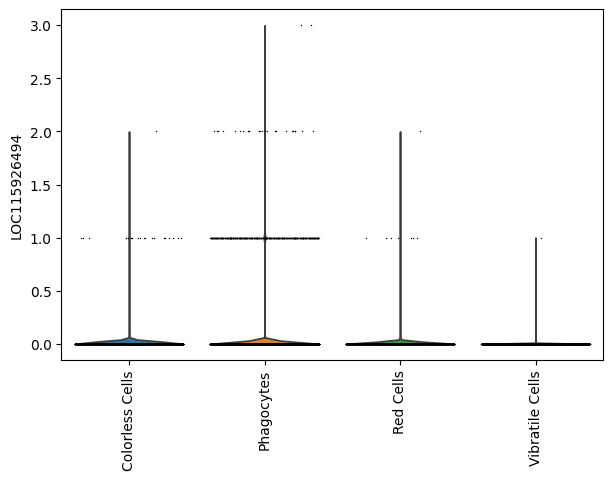

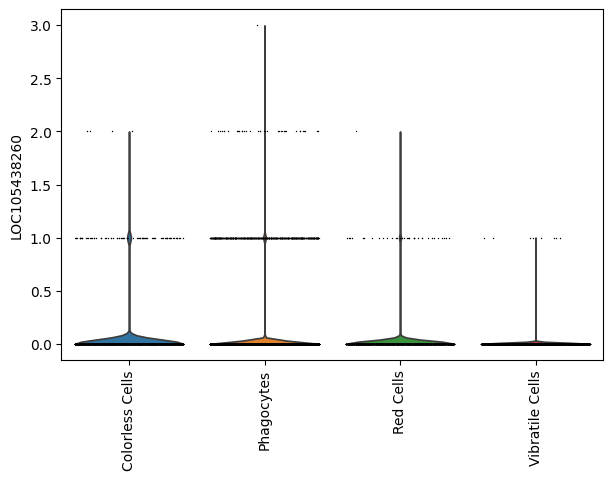

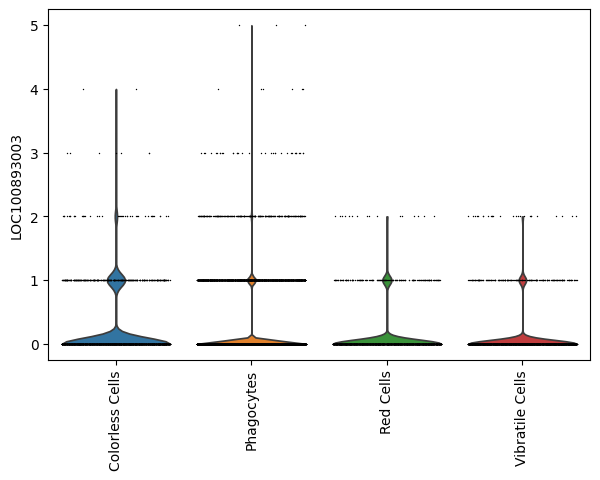

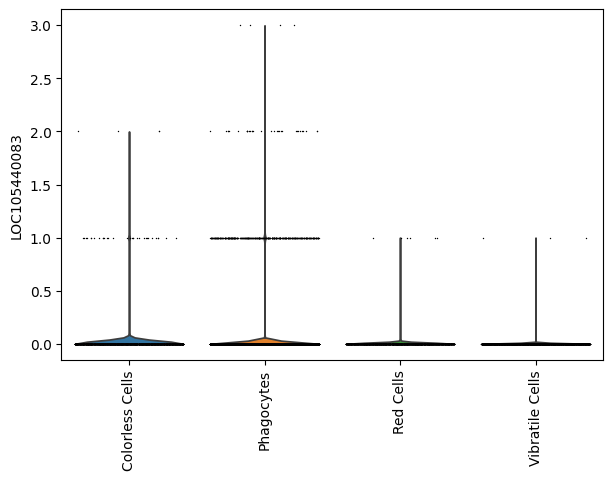

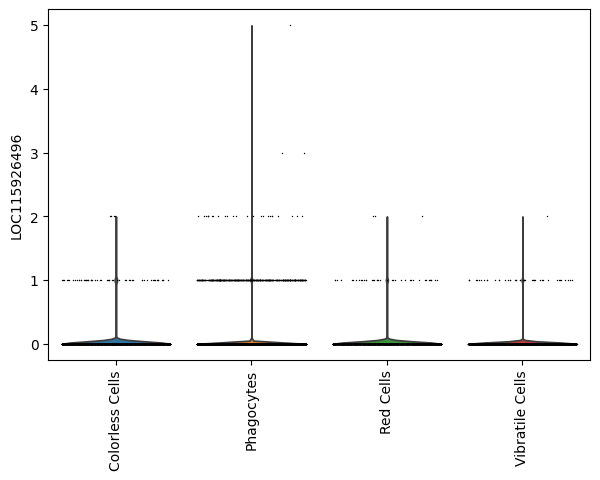

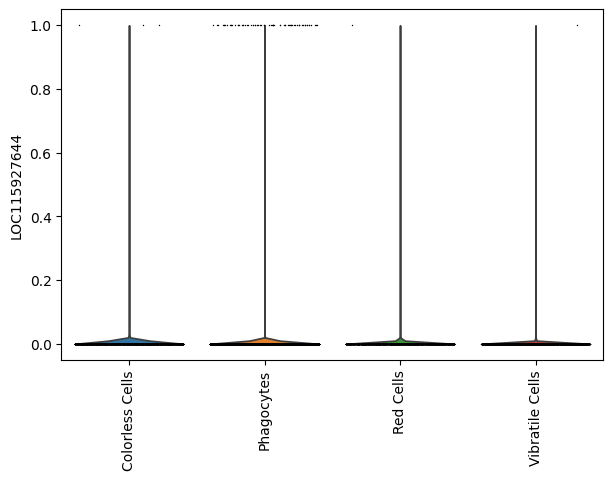

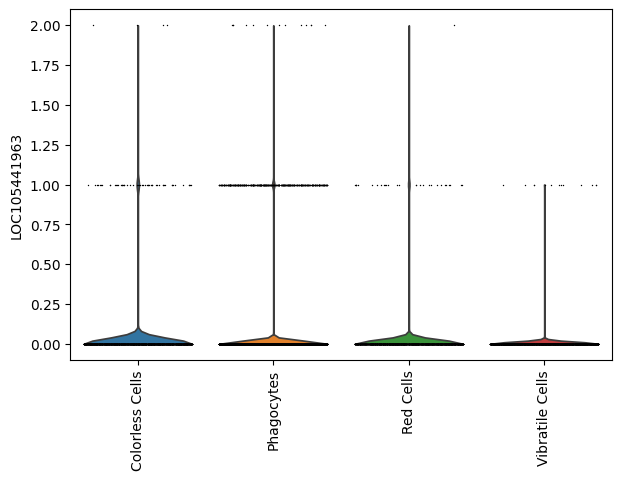

In [94]:
import matplotlib.pyplot as plt
#%matplotlib inline

# Plot for zapped condition
for gene in genes_of_interest:
    sc.pl.violin(adata_zapped, keys=gene, groupby='cell_type', jitter=0.4, rotation=90)
    plt.title(f'Gene Expression of {gene} in Zapped Condition')
    plt.savefig(f'zapped_{gene}_violin.png')
    plt.close()

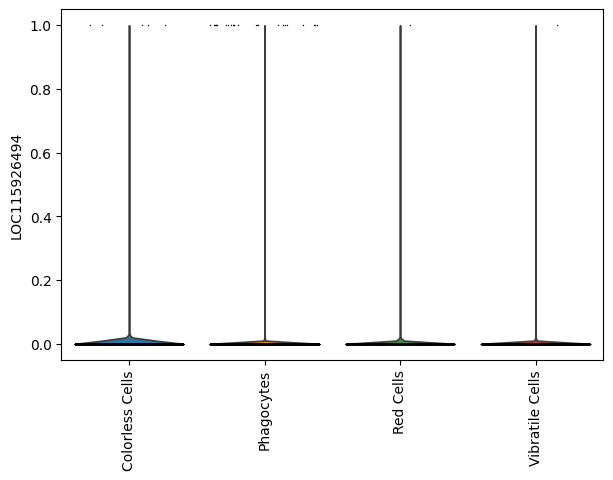

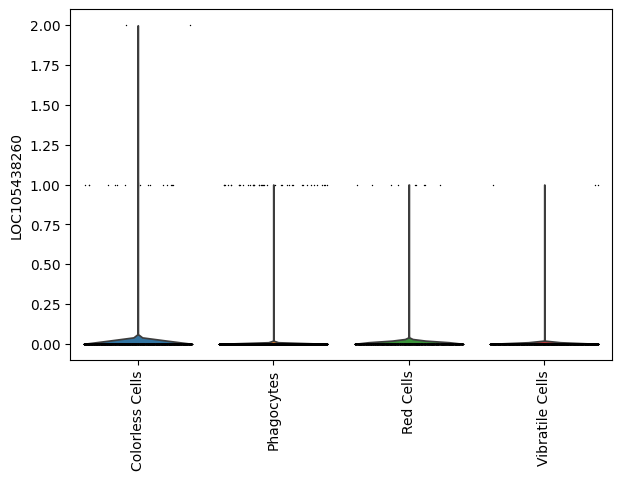

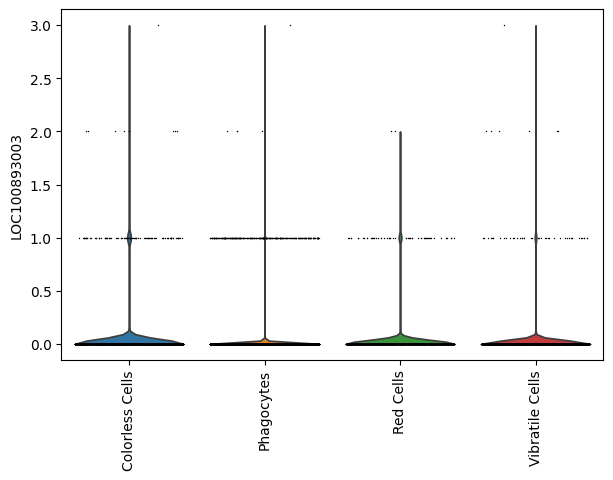

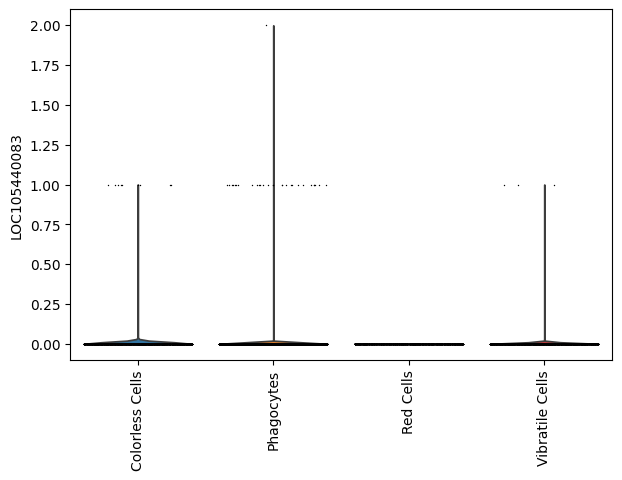

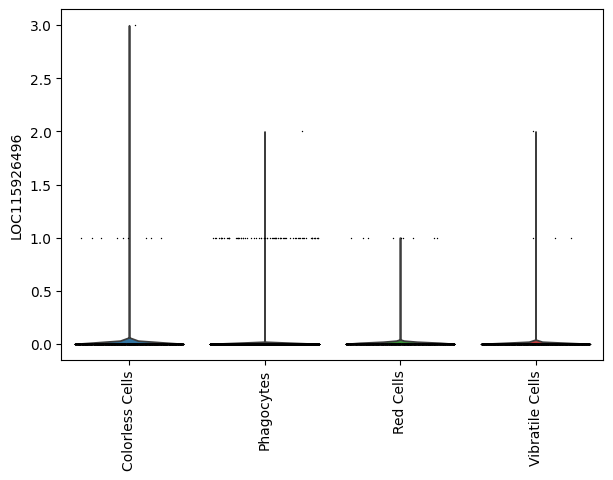

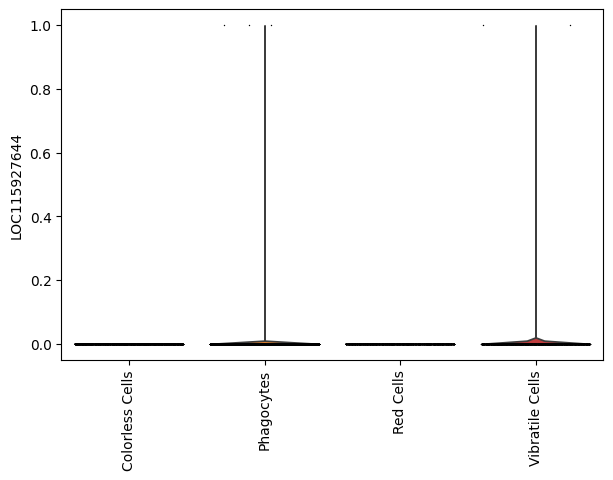

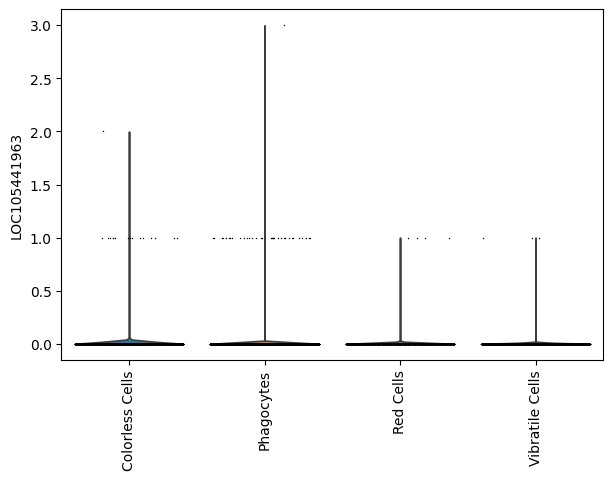

In [102]:
# Plot for control condition
for gene in genes_of_interest:
    sc.pl.violin(adata_control, keys=gene, groupby='cell_type', use_raw = True, jitter=0.4, rotation=90)
    plt.title(f'Gene Expression of {gene} in Control Condition')
    plt.savefig(f'control_{gene}_violin.png')
    plt.close()

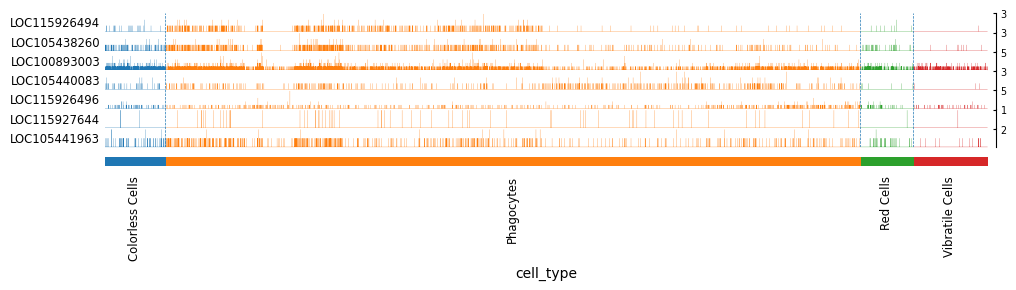

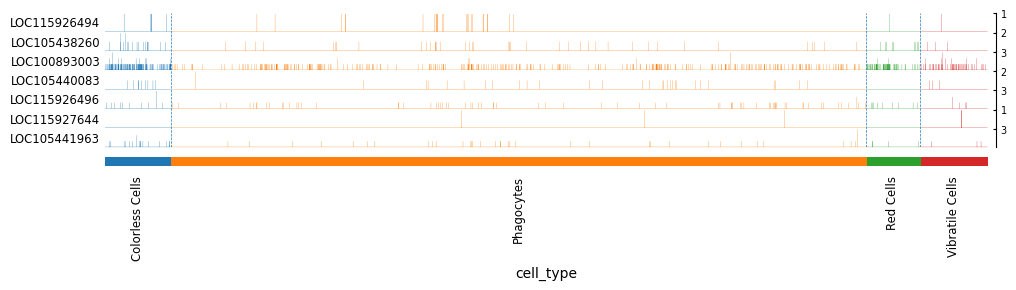

In [98]:
sc.pl.tracksplot(adata_zapped, var_names=genes_of_interest, groupby='cell_type', title='Gene Expression in Zapped Condition')
plt.savefig('zapped_tracksplot.png', bbox_inches='tight')
plt.close()

sc.pl.tracksplot(adata_control, var_names=genes_of_interest, groupby='cell_type', title='Gene Expression in Control Condition')
plt.savefig('control_tracksplot.png', bbox_inches='tight')
plt.close()


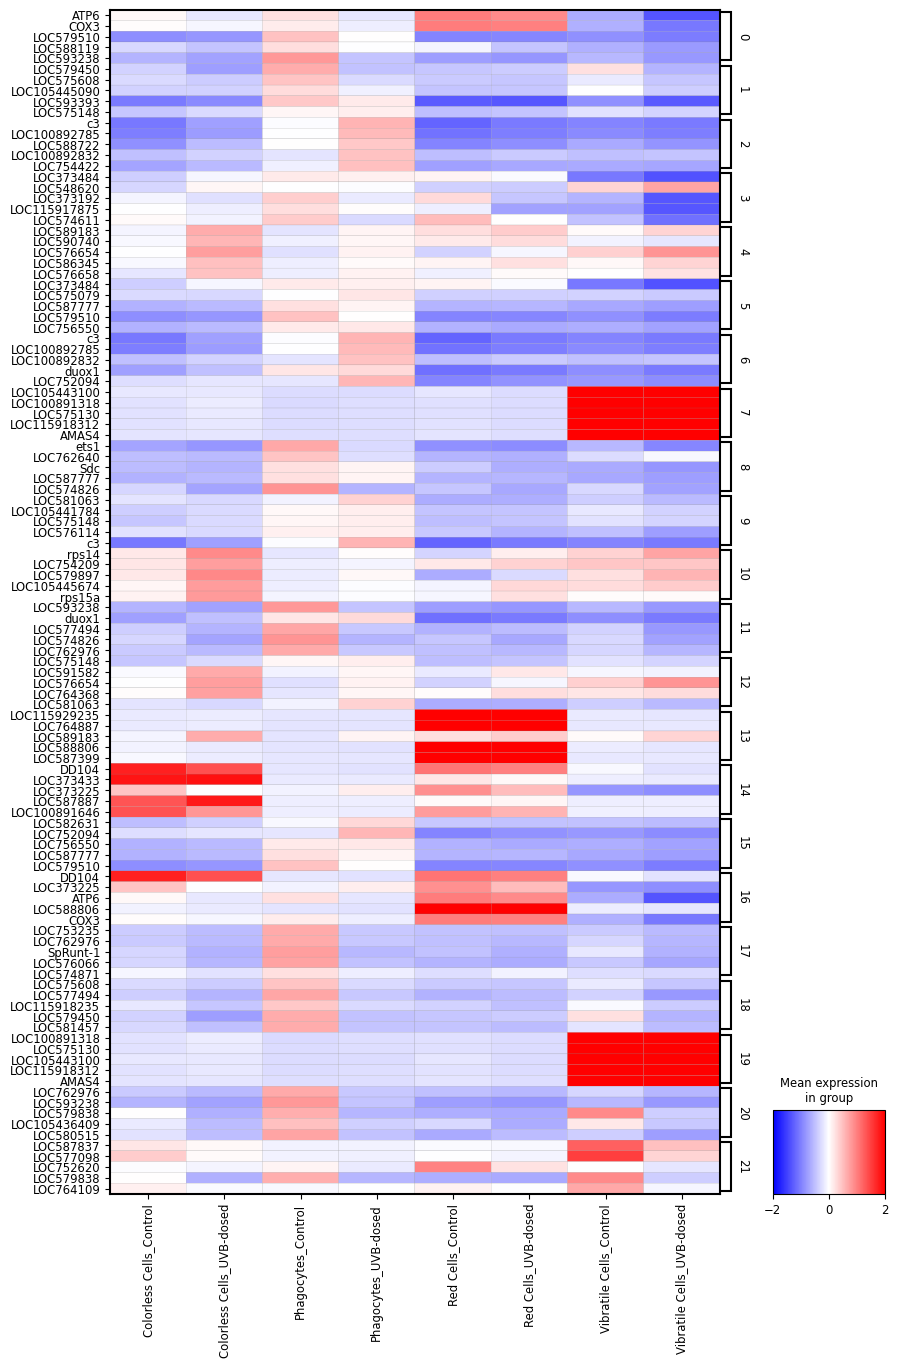

In [31]:
#sc.tl.dendrogram(adata, groupby = 'cell_type')
#Need to reassign cell_types to adata using the simpler dictionary above
#Other useful option is to normalize the gene expression using sc.pp.scale. Here we store this information under the scale layer.
adata.layers["scaled"] = sc.pp.scale(adata, copy=True).X

sc.pl.rank_genes_groups_matrixplot(
    adata, n_genes=5, vmin=-2, vmax=2, use_raw=True, cmap="bwr", layer="scaled", groupby = ['cell_type','condition'], 
    dendrogram=False, swap_axes=True, show=True, figsize = (10,15)
)

In [14]:
#Set adata.X back to raw counts
#adata.X = adata.layers['counts']

#TO SET ADATA.X BACK TO NORMALIZED counts
#adata.X = adata.layers['normalized_counts']

